# Space Creation in Build-Up Play: Who Makes It, Who Finds It, Who Feeds It

**PySport Analytics Cup 2.0 — football track** · SkillCorner A-League 2024/25

This notebook implements the research outline end to end:

| Section | Outline item |
|---|---|
| 1–3 | Data, configuration, coordinate handling and a data audit (detection / extrapolation) |
| 4 | Value surface (data-driven, fitted on SkillCorner xThreat) |
| 5 | Pitch control (Fernández & Bornn influence model) |
| 6 | Counterfactual baseline: expected positions conditioned on ball location **and** phase of play |
| 7 | Run detection from tracking, matched to SkillCorner off-ball runs |
| 8 | **Space Creator** — space generated for teammates, with the three-way split (created / conceded / baseline) |
| 9 | **Space Occupier** — arriving in space someone else opened |
| 10 | **Space Feeder** — vision (lead time, all attempts) and execution (completion, precision), weighted towards vision |
| 11 | **Space behind the defence** — line height, synchrony, step lag, goalkeeper gap, conceded space |
| 12 | **Taxonomy** — independent classifiers, attacking-only vs defence-aware lenses |
| 13 | **Body orientation** from the new pose data |
| 14 | Validation against SkillCorner Game Intelligence |
| 15 | Leaderboards and team comparison |
| 16 | Visuals for case studies (stills and GIFs to pair with match footage) |

**Design notes**
* Every function is written so it can be lifted into `src/` unchanged (the Cup rewards reusable methods).
* All analysis happens in the *attacking frame*: the team in possession always attacks towards +x.
  SkillCorner event coordinates are already in this frame; tracking is converted here.
* Metrics are computed for **all** in-possession phases and the phase is stored, so the build-up filter
  is applied at aggregation time and other phases stay available for comparison.
* Players whose positions are extrapolated (off-camera) are tracked with a reliability score rather than
  silently dropped, so every number can be filtered by data quality.

**Prior to Running**<br>
move into analytics-cup-football folder<br><br>
Run:<br>
python -m venv .venv<br>
.venv\Scripts\activate<br>
pip install numpy pandas scipy scikit-learn matplotlib pillow ipykernel<br>

## 1. Setup and configuration

In [1]:
from __future__ import annotations

import gzip
import os
import pickle
import shutil
import json
import math
import warnings
import zipfile
from dataclasses import dataclass, field
from types import SimpleNamespace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import animation
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))   # silences a joblib warning on Windows
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
# ---- Paths -------------------------------------------------------------------
# The SkillCorner open-data repo is cloned into analytics-cup-football/data/opendata. Run from notebooks/.
#   DATA_DIR/matches/{id}/{id}_match.json
#   DATA_DIR/matches/{id}/{id}_tracking_extrapolated.jsonl
#   DATA_DIR/matches/{id}/{id}_dynamic_events.csv
#   DATA_DIR/matches/{id}/{id}_phases_of_play.csv
#   DATA_DIR/bodypose/sample_1925299_phase406.jsonl.gz   (+ full archives, optional)


# ---- Caching switches (see the table in Section 11.1) ---------------------------
REBUILD_BASELINE = True   # True after changing roles, phases, CF_BANDWIDTH or the match set
RERUN_PIPELINE = True     # True after changing run detection, scoring, occupier, feeder or line code
RERUN_MATCHES = None       # or a list of match ids to rescore just those
REBUILD_REVIEW = True     # True to draw a NEW review sample (overwrites review_sheet.csv)
REVIEW_NAME = "review_v3"  # review folder; a new name starts a fresh sample and keeps older reviews

# ---- Focus ---------------------------------------------------------------------
OPP_HALF_ONLY = True       # keep only movements whose space opens mainly in the opponent's half
HALF_X = 0.0               # halfway line in the attacking frame (raise it, e.g. 17.5, for the final third only)
VACATED_ONLY = True        # cases, review and showcase: only plays where the space opens at a dragged defender's
                           # vacated (expected) spot — the coachable, reproducible pattern
VACATED_R = 8.0            # m: best opened space (and the beneficiary's target) must be this close to that spot


DATA_DIR = Path("../data/opendata/data")   # SkillCorner repo's data folder
CACHE_DIR = Path("../data/cache")          # keep cache and outputs outside the cloned repo
FIG_DIR = Path("../figures")
OUT_DIR = Path("../data/outputs")
for d in (CACHE_DIR, FIG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)
assert (DATA_DIR / "matches").is_dir(), f"No matches folder under {DATA_DIR.resolve()} — run the notebook from notebooks/"

MATCH_IDS = [1925299, 1996435] # These are the two matches with pose data, run for testing
# MATCH_IDS = None             # None = every match with real (non-LFS-pointer) tracking in DATA_DIR

# ---- Analysis settings -------------------------------------------------------
FPS = 10                                  # tracking / events frame rate
BUILDUP_PHASES = ("build_up", "create")   # SkillCorner in-possession phase types treated as build-up
GRID_RES = 2.0                            # pitch-control grid resolution (m)
CF_BANDWIDTH = 7.0                        # kernel bandwidth (m) for the expected-position model
CF_MIN_NEFF = 15.0                        # minimum effective sample size before falling back a level
CF_LEAVE_ONE_OUT = True                   # fit the baseline without the match being scored
TRAIN_STRIDE = 5                          # use every 5th frame (2 Hz) to fit the baseline
BASELINE_VERSION = "shape-v1"             # expected spots relative to the team's block (see Section 6)
MIN_SEP = 4.0                             # m: an expected spot is never on top of a teammate
OCCUPIED_R = 5.0                          # m: a dragged defender opens no space if a teammate stands where
                                          #    he should have been
PIPELINE_VERSION = "v6"                   # bump when scoring logic changes: cached results are then rebuilt
                                          # (v6: drags judged relative to each team's own movement)
ABNORMAL_MIN_M = 3.0                      # m a mover must move relative to his own team's shift to count as an
                                          #    abnormal movement (one that can create space at all)
DEV_GROWTH_MIN = 1.0                      # m a defender must get FURTHER from his expected spot during the movement
BEN_EXCLUDE_GROUPS = ("GK", "CB")         # role groups never suggested as the player to run into the space
KEEPER_BUFFER_M = 1.0                     # no usable space behind the keeper (or within this of his line)

# ---- Team plays (dashboard "Team plays" tab) ------------------------------------------
TEAMPLAY_JOIN_S = 1.0                     # a movement joins a team play if it starts within this of the play's end
TEAMPLAY_LEAD_S = 1.0                     # shown before the first movement (display only)
TEAMPLAY_BUFFER_S = 1.0                   # shown after the play ends (display only, never computed on)

RUN_MIN_SPEED = 5.0                       # m/s (~14.4 km/h) to count as running
RUN_MIN_FRAMES = 7                        # 0.7 s, same minimum as SkillCorner off-ball runs
RUN_MAX_GAP = 2                           # frames of slower movement tolerated inside a run
RUN_MIN_BALL_DIST = 3.0                   # exclude the ball carrier

DRAG_MIN_DISP = 1.5                       # m a defender must move during a run to count as dragged
DRAG_MIN_COS = 0.3                        # alignment between defender and runner displacement
DRAG_MIN_DEV = 1.5                        # m a defender must be away from his expected spot
DRAG_MIN_SHARE = 0.5                      # share of run frames where the runner is his nearest attacker

CREATED_MAP_THRESHOLD = 0.15              # ΔPC above this = "created space" cell
OCCUPY_WINDOW = 30                        # frames (3 s) after a run in which space can be occupied
PC_OPEN = 0.5                             # attacking control needed for a location to count as open
LEAD_CAP_S = 3.0                          # lead-time credit saturates at 3 s

W_VISION, W_EXEC = 0.6, 0.4               # feeder composite weights (vision weighted above execution)
MIN_TIP_MINUTES = 45.0                    # leaderboard filter: minutes with team in possession
RANDOM_STATE = 7

## 2. Data loading

### 2.1 Match metadata, roles and playing direction

In [3]:
def tracking_path(mid: int) -> Path:
    return DATA_DIR / "matches" / str(mid) / f"{mid}_tracking_extrapolated.jsonl"


def is_real_tracking(path: Path) -> bool:
    """Git LFS leaves a ~130-byte pointer file if the data was not pulled."""
    return path.exists() and path.stat().st_size > 10_000


def list_matches() -> list[int]:
    mids = sorted(int(p.name) for p in (DATA_DIR / "matches").iterdir() if p.is_dir() and p.name.isdigit())
    missing = [m for m in mids if not is_real_tracking(tracking_path(m))]
    if missing:
        print(f"{len(missing)} match(es) have no tracking (Git LFS pointer only): {missing}\n"
              "  -> run `git lfs pull` in the data repo to fetch them.")
    return [m for m in mids if m not in missing]


def load_events(mid: int) -> pd.DataFrame:
    de = pd.read_csv(DATA_DIR / "matches" / str(mid) / f"{mid}_dynamic_events.csv", low_memory=False)
    de["match_id"] = mid
    return de


def load_phases(mid: int) -> pd.DataFrame:
    return pd.read_csv(DATA_DIR / "matches" / str(mid) / f"{mid}_phases_of_play.csv")


@dataclass
class MatchMeta:
    match_id: int
    pitch_length: float
    pitch_width: float
    home_id: int
    away_id: int
    team_names: dict
    players: pd.DataFrame          # player_id, name, team_id, role, position_group, minutes_tip, ...
    direction: dict                # (team_id, period) -> +1 attacks towards +x, -1 towards -x
    periods: list


ROLE_GROUP = {"GK": "GK", "LCB": "CB", "RCB": "CB", "CB": "CB", "LB": "FB", "RB": "FB", "LWB": "FB", "RWB": "FB",
              "LDM": "DM", "RDM": "DM", "DM": "DM", "LM": "WM", "RM": "WM", "CM": "CM", "LCM": "CM", "RCM": "CM",
              "AM": "AM", "LW": "W", "RW": "W", "CF": "CF", "LF": "CF", "RF": "CF"}
DEFENDER_ROLES = {"LCB", "RCB", "CB", "LB", "RB", "LWB", "RWB"}


def load_meta(mid: int, events: pd.DataFrame | None = None) -> MatchMeta:
    m = json.load(open(DATA_DIR / "matches" / str(mid) / f"{mid}_match.json", encoding="utf-8"))
    rows = []
    for p in m["players"]:
        pt = p.get("playing_time") or {}
        tot = pt.get("total") or {}
        rows.append(dict(player_id=p["id"], name=p.get("short_name"), team_id=p["team_id"], number=p.get("number"),
                         role=p["player_role"]["acronym"], position_group=p["player_role"]["position_group"],
                         minutes=tot.get("minutes_played") or 0.0, minutes_tip=tot.get("minutes_tip") or 0.0,
                         minutes_otip=tot.get("minutes_otip") or 0.0))
    players = pd.DataFrame(rows)
    # Substitutes are listed with role "SUB": use the position SkillCorner assigns them in the events.
    if events is not None and (players.role == "SUB").any():
        modal = (events.dropna(subset=["player_id", "player_position"])
                 .groupby("player_id").player_position.agg(lambda s: s.mode().iat[0]))
        sub = players.role == "SUB"
        players.loc[sub, "role"] = players.loc[sub, "player_id"].map(modal).fillna("SUB")
    players["role_group"] = players.role.map(ROLE_GROUP).fillna("OTHER")

    home, away = m["home_team"]["id"], m["away_team"]["id"]
    direction = {}
    for i, side in enumerate(m["home_team_side"]):
        s = 1 if side == "left_to_right" else -1
        direction[(home, i + 1)], direction[(away, i + 1)] = s, -s
    return MatchMeta(mid, float(m["pitch_length"]), float(m["pitch_width"]), home, away,
                     {home: m["home_team"]["short_name"], away: m["away_team"]["short_name"]},
                     players, direction, [p["period"] for p in m["match_periods"]])


def check_direction(meta: MatchMeta, events: pd.DataFrame) -> pd.DataFrame:
    """Cross-check match.json playing direction against attacking_side in the events."""
    ev = (events.dropna(subset=["team_id", "attacking_side"])
          .groupby(["team_id", "period"]).attacking_side.agg(lambda s: s.mode().iat[0]).reset_index())
    ev["from_events"] = np.where(ev.attacking_side == "left_to_right", 1, -1)
    ev["from_match_json"] = [meta.direction.get((int(t), int(p))) for t, p in zip(ev.team_id, ev.period)]
    ev["agree"] = ev.from_events == ev.from_match_json
    return ev

### 2.2 Tracking

Tracking is stored as dense arrays: `pos[frame, player, xy]` in **raw pitch coordinates**, with NaN where a
player is not on the pitch, and `det[frame, player]` for the `is_detected` flag. Velocities come from a
Savitzky–Golay filter on each continuous segment. The parsed arrays are cached as `.npz`.

In [4]:
@dataclass
class Tracking:
    match_id: int
    frames: np.ndarray        # (F,) frame ids
    period: np.ndarray        # (F,)
    ball: np.ndarray          # (F, 3)
    ball_det: np.ndarray      # (F,)
    poss_group: np.ndarray    # (F,) 'home team' / 'away team' / ''
    poss_player: np.ndarray   # (F,) player id or -1
    player_ids: np.ndarray    # (P,)
    team_ids: np.ndarray      # (P,)
    pos: np.ndarray           # (F, P, 2) raw coords
    det: np.ndarray           # (F, P) bool
    vel: np.ndarray = None    # (F, P, 2)
    poss_team: np.ndarray = None   # (F,) team id in possession (phases first, tracking fallback), -1 if none
    phase: np.ndarray = None       # (F,) SkillCorner in-possession phase type
    sign: np.ndarray = None        # (F,) +1/-1 to put the team in possession into the attacking frame
    direction: dict = None         # (team_id, period) -> +1/-1

    def idx(self, frame) -> np.ndarray:
        """Map frame id(s) to array index (-1 if the frame is not in the tracking)."""
        frame = np.asarray(frame)
        i = np.searchsorted(self.frames, frame)
        i = np.clip(i, 0, len(self.frames) - 1)
        return np.where(self.frames[i] == frame, i, -1)


def parse_tracking(mid: int, meta: MatchMeta) -> Tracking:
    cache = CACHE_DIR / f"{mid}_tracking.npz"
    if cache.exists():
        z = np.load(cache, allow_pickle=True)
        return Tracking(mid, *(z[k] for k in ["frames", "period", "ball", "ball_det", "poss_group", "poss_player",
                                              "player_ids", "team_ids", "pos", "det"]))
    team_of = dict(zip(meta.players.player_id, meta.players.team_id))
    records = []
    with open(tracking_path(mid), encoding="utf-8") as fh:
        for line in fh:
            r = json.loads(line)
            if r.get("period") is None or not r.get("player_data"):
                continue
            records.append(r)
    pids = sorted({p["player_id"] for r in records for p in r["player_data"] if p["player_id"] in team_of},
                  key=lambda p: (team_of[p], p))
    col = {p: i for i, p in enumerate(pids)}
    F, P = len(records), len(pids)
    pos = np.full((F, P, 2), np.nan, np.float32)
    det = np.zeros((F, P), bool)
    ball = np.full((F, 3), np.nan, np.float32)
    ball_det = np.zeros(F, bool)
    frames = np.empty(F, np.int64)
    period = np.empty(F, np.int8)
    poss_group = np.empty(F, object)
    poss_player = np.full(F, -1, np.int64)
    for i, r in enumerate(records):
        frames[i], period[i] = r["frame"], r["period"]
        b = r.get("ball_data") or {}
        if b.get("x") is not None:
            ball[i] = (b["x"], b["y"], b.get("z") or 0.0)
            ball_det[i] = bool(b.get("is_detected"))
        po = r.get("possession") or {}
        poss_group[i] = po.get("group") or ""
        poss_player[i] = po.get("player_id") or -1
        for p in r["player_data"]:
            j = col.get(p["player_id"])
            if j is not None and p.get("x") is not None:
                pos[i, j] = (p["x"], p["y"])
                det[i, j] = bool(p.get("is_detected"))
    order = np.argsort(frames)
    trk = Tracking(mid, frames[order], period[order], ball[order], ball_det[order], poss_group[order],
                   poss_player[order], np.array(pids), np.array([team_of[p] for p in pids]), pos[order], det[order])
    np.savez_compressed(cache, frames=trk.frames, period=trk.period, ball=trk.ball, ball_det=trk.ball_det,
                        poss_group=trk.poss_group, poss_player=trk.poss_player, player_ids=trk.player_ids,
                        team_ids=trk.team_ids, pos=trk.pos, det=trk.det)
    return trk


def contiguous_segments(valid: np.ndarray, frames: np.ndarray) -> list[tuple[int, int]]:
    """Index ranges [a, b) where `valid` is True and frame ids are consecutive."""
    brk = np.r_[True, (np.diff(frames) != 1) | (valid[1:] != valid[:-1]), True]
    edges = np.flatnonzero(brk)
    return [(a, b) for a, b in zip(edges[:-1], edges[1:]) if valid[a]]


def add_velocity(trk: Tracking, window: int = 7, max_speed: float = 12.0) -> None:
    vel = np.zeros_like(trk.pos)
    for j in range(trk.pos.shape[1]):
        ok = ~np.isnan(trk.pos[:, j, 0])
        for a, b in contiguous_segments(ok, trk.frames):
            if b - a >= window:
                for k in range(2):
                    vel[a:b, j, k] = savgol_filter(trk.pos[a:b, j, k], window, 2, deriv=1, delta=1 / FPS)
    speed = np.linalg.norm(vel, axis=-1, keepdims=True)
    vel = np.where(speed > max_speed, vel / np.maximum(speed, 1e-9) * max_speed, vel)
    vel[np.isnan(trk.pos)] = np.nan
    trk.vel = vel


def add_context(trk: Tracking, meta: MatchMeta, phases: pd.DataFrame) -> None:
    """Possession team, phase type and attacking-frame sign for every frame."""
    F = len(trk.frames)
    poss_team = np.full(F, -1, np.int64)
    phase = np.full(F, "", object)
    for r in phases.itertuples():
        i0, i1 = np.searchsorted(trk.frames, [r.frame_start, r.frame_end + 1])
        poss_team[i0:i1] = r.team_in_possession_id
        phase[i0:i1] = r.team_in_possession_phase_type
    group_team = {"home team": meta.home_id, "away team": meta.away_id}
    fallback = np.array([group_team.get(g, -1) for g in trk.poss_group])
    poss_team = np.where(poss_team == -1, fallback, poss_team)
    sign = np.array([meta.direction.get((t, p), 1) if t != -1 else 1 for t, p in zip(poss_team, trk.period)])
    trk.poss_team, trk.phase, trk.sign, trk.direction = poss_team, phase, sign.astype(np.int8), meta.direction


def frame_state(trk: Tracking, i: int, team: int | None = None):
    """Positions/velocities at index i in the attacking frame of `team` (default: team in possession)."""
    team = trk.poss_team[i] if team is None else team
    s = trk.direction.get((int(team), int(trk.period[i])), 1)
    on = ~np.isnan(trk.pos[i, :, 0])
    att = on & (trk.team_ids == team)
    dfn = on & (trk.team_ids != team)
    P = trk.pos[i] * s
    V = np.nan_to_num(trk.vel[i] * s)
    return dict(att=np.flatnonzero(att), dfn=np.flatnonzero(dfn), pos=P, vel=V, ball=trk.ball[i, :2] * s,
                det=trk.det[i], sign=s)

### 2.3 Load the competition data

In [5]:
match_ids = MATCH_IDS or list_matches()
print(f"{len(match_ids)} matches with tracking:", match_ids)

events_all = pd.concat([load_events(m) for m in match_ids], ignore_index=True)
metas = {m: load_meta(m, events_all[events_all.match_id == m]) for m in match_ids}
phases_all = {m: load_phases(m) for m in match_ids}

dir_check = pd.concat([check_direction(metas[m], events_all[events_all.match_id == m]).assign(match_id=m)
                       for m in match_ids])
print("Playing direction agreement (match.json vs events):", f"{dir_check.agree.mean():.0%}")

players_all = pd.concat([metas[m].players.assign(match_id=m) for m in match_ids], ignore_index=True)
team_names = {k: v for m in metas.values() for k, v in m.team_names.items()}
print(events_all.event_type.value_counts().to_string())

2 matches with tracking: [1925299, 1996435]
Playing direction agreement (match.json vs events): 100%
event_type
passing_option        5360
player_possession     2059
on_ball_engagement    1961
off_ball_run          1013


## 3. Data audit

Broadcast tracking estimates players who are off-camera. Before crediting anyone with space creation we need to
know how often that happens, and where. The audit reports detection rates by role and by distance from the ball,
and how often the goalkeeper is detected when play is in the other half (relevant to the space-behind module).

In [6]:
def detection_audit(trk: Tracking, meta: MatchMeta) -> pd.DataFrame:
    role = dict(zip(meta.players.player_id, meta.players.role_group))
    on = ~np.isnan(trk.pos[..., 0])
    d_ball = np.linalg.norm(trk.pos - trk.ball[:, None, :2], axis=-1)
    rows = []
    for j, pid in enumerate(trk.player_ids):
        m = on[:, j]
        if not m.any():
            continue
        gk_far = np.nan
        if role.get(pid) == "GK":
            own_goal_x = -52.5 * meta.direction.get((trk.team_ids[j], 1), 1)  # period 1 reference
            per = trk.period[m]
            goal_x = np.where(per == 1, own_goal_x, -own_goal_x)
            far = np.abs(trk.ball[m, 0] - goal_x) > 52.5
            gk_far = trk.det[m, j][far].mean() if far.any() else np.nan
        rows.append(dict(match_id=trk.match_id, player_id=pid, role_group=role.get(pid, "OTHER"),
                         frames=int(m.sum()), detected=trk.det[m, j].mean(),
                         detected_near_ball=trk.det[m, j][d_ball[m, j] < 20].mean(),
                         detected_far_ball=trk.det[m, j][d_ball[m, j] >= 35].mean(),
                         gk_detected_ball_other_half=gk_far))
    return pd.DataFrame(rows)

## 4. Value surface

Not all space is equal. Rather than hand-picking a value function, the surface is fitted to SkillCorner's own
`xthreat` of passing options across every match (event coordinates are already in the attacking frame). A
Nadaraya–Watson smoother on a 1 m grid, mirrored across the long axis, gives a stable surface; a simple
distance-to-goal surface is kept as a fallback and for sensitivity checks.

In [7]:
@dataclass
class ValueSurface:
    xs: np.ndarray
    ys: np.ndarray
    z: np.ndarray       # (ny, nx)

    def __post_init__(self):
        self._f = RegularGridInterpolator((self.ys, self.xs), self.z, bounds_error=False, fill_value=None)

    def __call__(self, xy: np.ndarray) -> np.ndarray:
        xy = np.atleast_2d(xy)
        q = np.c_[np.clip(xy[:, 1], self.ys[0], self.ys[-1]), np.clip(xy[:, 0], self.xs[0], self.xs[-1])]
        return np.maximum(self._f(q), 0.0)


def fit_value_surface(events: pd.DataFrame, length=105.0, width=68.0, res=1.0, sigma_m=4.0) -> ValueSurface:
    po = events[(events.event_type == "passing_option")].dropna(subset=["x_start", "y_start", "xthreat"])
    x = np.r_[po.x_start, po.x_start]
    y = np.r_[po.y_start, -po.y_start]           # mirror: the pitch is symmetric left/right
    v = np.r_[po.xthreat, po.xthreat]
    xs = np.arange(-length / 2 + res / 2, length / 2, res)
    ys = np.arange(-width / 2 + res / 2, width / 2, res)
    sx, _, _ = np.histogram2d(y, x, bins=[np.r_[ys - res / 2, ys[-1] + res / 2], np.r_[xs - res / 2, xs[-1] + res / 2]],
                              weights=v)
    n, _, _ = np.histogram2d(y, x, bins=[np.r_[ys - res / 2, ys[-1] + res / 2], np.r_[xs - res / 2, xs[-1] + res / 2]])
    s = sigma_m / res
    num, den = gaussian_filter(sx, s), gaussian_filter(n, s)
    z = np.where(den > 0.5, num / np.maximum(den, 1e-9), np.nan)
    fallback = parametric_value(xs, ys) * np.nanmax(z)
    z = np.where(np.isnan(z), fallback, z)
    return ValueSurface(xs, ys, z)


def parametric_value(xs, ys, scale=18.0):
    X, Y = np.meshgrid(xs, ys)
    d = np.hypot(52.5 - X, Y)
    return np.exp(-d / scale)

## 5. Pitch control

Fernández & Bornn (2018) influence model: each player's influence is a bivariate normal centred half a second
ahead along their velocity, stretched in the direction of travel and wider the further they are from the ball.
Control is the logistic of attacking minus defending influence. It is fully vectorised, so evaluating a frame on
a 2 m grid costs about a millisecond — cheap enough to re-run under counterfactuals.

In [8]:
@dataclass
class Grid:
    length: float
    width: float
    res: float = GRID_RES

    def __post_init__(self):
        self.nx, self.ny = int(round(self.length / self.res)), int(round(self.width / self.res))
        self.xs = -self.length / 2 + (np.arange(self.nx) + 0.5) * self.length / self.nx
        self.ys = -self.width / 2 + (np.arange(self.ny) + 0.5) * self.width / self.ny
        X, Y = np.meshgrid(self.xs, self.ys)
        self.points = np.c_[X.ravel(), Y.ravel()]
        self.cell_area = (self.length / self.nx) * (self.width / self.ny)

    def cell(self, xy: np.ndarray) -> np.ndarray:
        xy = np.atleast_2d(xy)
        ix = np.clip(np.floor((xy[:, 0] + self.length / 2) / (self.length / self.nx)), 0, self.nx - 1).astype(int)
        iy = np.clip(np.floor((xy[:, 1] + self.width / 2) / (self.width / self.ny)), 0, self.ny - 1).astype(int)
        return iy * self.nx + ix


def influence(xy: np.ndarray, vel: np.ndarray, ball: np.ndarray, points: np.ndarray) -> np.ndarray:
    """(N players, G points) influence, Fernández & Bornn (2018)."""
    if len(xy) == 0:
        return np.zeros((0, len(points)))
    d = np.linalg.norm(xy - ball, axis=1)
    R = np.clip(4.0 + d ** 3 / (18.0 ** 3 / 6.0), 4.0, 10.0)
    speed = np.linalg.norm(vel, axis=1)
    srat = np.clip((speed / 13.0) ** 2, 0.0, 0.95)
    th = np.arctan2(vel[:, 1], vel[:, 0])
    c, s = np.cos(th), np.sin(th)
    sx2, sy2 = ((R + R * srat) / 2) ** 2, ((R - R * srat) / 2) ** 2
    a, b, e = c * c * sx2 + s * s * sy2, c * s * (sx2 - sy2), s * s * sx2 + c * c * sy2
    det = a * e - b * b
    ia, ib, ie = e / det, -b / det, a / det
    mu = xy + 0.5 * vel
    dx = points[None, :, 0] - mu[:, None, 0]
    dy = points[None, :, 1] - mu[:, None, 1]
    q = ia[:, None] * dx * dx + 2 * ib[:, None] * dx * dy + ie[:, None] * dy * dy
    px, py = xy[:, 0] - mu[:, 0], xy[:, 1] - mu[:, 1]
    q0 = ia * px * px + 2 * ib * px * py + ie * py * py
    return np.exp(-0.5 * (q - q0[:, None]))


def pitch_control(att_xy, att_v, def_xy, def_v, ball, points) -> np.ndarray:
    ia = influence(att_xy, att_v, ball, points).sum(0)
    idf = influence(def_xy, def_v, ball, points).sum(0)
    return 1.0 / (1.0 + np.exp(-(ia - idf)))


def space_value(pc: np.ndarray, value: np.ndarray, cell_area: float) -> float:
    """Value-weighted attacking space (xT · m²)."""
    return float((pc * value).sum() * cell_area)

## 6. Counterfactual baseline: expected positions

For every team, role and possession state (in / out), the expected position of a player is a kernel-weighted
average of where that player's role stands **given the ball location**, optionally also given the SkillCorner
phase. This is the "where would he have been if this run hadn't happened" reference. Without conditioning on the
ball, every ordinary shift with play would look like space creation.

Implementation: sufficient statistics (Σw, Σw·x, Σw·y) are accumulated per match on a 5 m ball grid, so a
**leave-one-match-out** baseline is just `total − this match`. Prediction falls back through
`(team, role, state, phase) → (team, role, state) → (league, role, state, phase) → (league, role, state)` until the
effective sample size is large enough.

**Shape-relative version (`BASELINE_VERSION = "shape-v1"`).** The model now learns each role's *offset from the centre of
his outfield teammates* (given the ball and phase), not an absolute spot. A player's expected spot is the actual centre of
his teammates at that moment plus that offset, so it moves with the block and keeps his place in it: a holding midfielder's
spot stays in front of the back line rather than drifting onto a centre-back. Expected spots are also pushed at least
`MIN_SEP` (4 m) away from any teammate, because two players are never expected in the same place.

In [9]:
class ExpectedPositions:
    def __init__(self, length=105.0, width=68.0, step=5.0, bandwidth=CF_BANDWIDTH):
        self.gx = np.arange(-length / 2, length / 2 + 1e-6, step)
        self.gy = np.arange(-width / 2, width / 2 + 1e-6, step)
        G = np.stack(np.meshgrid(self.gx, self.gy), -1).reshape(-1, 2)
        self.G, self.h = G, bandwidth
        self.stats: dict = {}       # key -> {match_id: (3, ny*nx)}
        self.total: dict = {}

    def add(self, match_id, keys: list, ball: np.ndarray, pos: np.ndarray):
        keys_arr = pd.Series(keys)
        for key, idx in keys_arr.groupby(keys_arr, sort=False).groups.items():
            idx = np.asarray(idx)
            acc = np.zeros((3, len(self.G)))
            for c in range(0, len(idx), 4000):
                ii = idx[c:c + 4000]
                d2 = ((ball[ii, None, :] - self.G[None]) ** 2).sum(-1)
                W = np.exp(-d2 / (2 * self.h ** 2))
                acc[0] += W.sum(0)
                acc[1] += W.T @ pos[ii, 0]
                acc[2] += W.T @ pos[ii, 1]
            self.stats.setdefault(key, {})
            self.stats[key][match_id] = self.stats[key].get(match_id, 0) + acc

    def finalize(self):
        self.total = {k: sum(v.values()) for k, v in self.stats.items()}

    def _interp(self, arr, ball):
        ny, nx = len(self.gy), len(self.gx)
        f = RegularGridInterpolator((self.gy, self.gx), arr.reshape(ny, nx), bounds_error=False, fill_value=None)
        b = np.c_[np.clip(ball[:, 1], self.gy[0], self.gy[-1]), np.clip(ball[:, 0], self.gx[0], self.gx[-1])]
        return f(b)

    def predict(self, chain: list, ball: np.ndarray, exclude_match=None) -> tuple[np.ndarray, np.ndarray]:
        """Expected (x, y) and effective n for each ball location, walking down the fallback chain."""
        ball = np.atleast_2d(ball)
        out = np.full((len(ball), 2), np.nan)
        neff = np.zeros(len(ball))
        todo = np.ones(len(ball), bool)
        for key in chain:
            if key not in self.total or not todo.any():
                continue
            s = self.total[key]
            if exclude_match is not None and exclude_match in self.stats[key]:
                s = s - self.stats[key][exclude_match]
            w = self._interp(s[0], ball[todo])
            ok = w >= CF_MIN_NEFF
            if ok.any():
                sel = np.flatnonzero(todo)[ok]
                out[sel, 0] = self._interp(s[1], ball[sel]) / w[ok]
                out[sel, 1] = self._interp(s[2], ball[sel]) / w[ok]
                neff[sel] = w[ok]
                todo[sel] = False
        return out, neff


def phase_group(phase: str) -> str:
    if phase in ("build_up",):
        return "build_up"
    if phase in ("create",):
        return "create"
    return "other"


def key_chain(team, role, state, phase):
    pg = phase_group(phase)
    return [(team, role, state, pg), (team, role, state, "any"), ("ALL", role, state, pg), ("ALL", role, state, "any")]


def block_centre_others(pos, group, outfield):
    """For each player in `group`, the average position of his outfield teammates in `group`, excluding himself."""
    P = pos[group]
    ok = outfield & ~np.isnan(P[:, 0])
    tot, n = np.nansum(P[ok], axis=0), ok.sum()
    out = np.full((len(group), 2), np.nan)
    for k in range(len(group)):
        own = ok[k]
        m = n - (1 if own else 0)
        if m > 0:
            out[k] = (tot - (P[k] if own else 0)) / m
    return out


def accumulate_expected(ep: ExpectedPositions, trk: Tracking, meta: MatchMeta):
    """Fit samples are each player's OFFSET from the centre of his outfield teammates (not his absolute position), so
    an expected spot moves with the team's block and keeps each role's place within it."""
    role = dict(zip(meta.players.player_id, meta.players.role))
    idx = np.flatnonzero((trk.poss_team != -1) & ~np.isnan(trk.ball[:, 0]))[::TRAIN_STRIDE]
    keys, balls, poss = [], [], []
    for i in idx:
        st = frame_state(trk, i)
        pg = phase_group(trk.phase[i])
        for group, state in ((st["att"], "in"), (st["dfn"], "out")):
            outfield = np.array([role.get(trk.player_ids[j]) != "GK" for j in group])
            centres = block_centre_others(st["pos"], group, outfield)
            for k, j in enumerate(group):
                if np.isnan(centres[k, 0]) or np.isnan(st["pos"][j, 0]):
                    continue
                r, t = role.get(trk.player_ids[j], "OTHER"), trk.team_ids[j]
                for key in ((t, r, state, pg), (t, r, state, "any"), ("ALL", r, state, pg), ("ALL", r, state, "any")):
                    keys.append(key)
                    balls.append(st["ball"])
                    poss.append(st["pos"][j] - centres[k])
    ep.add(trk.match_id, keys, np.array(balls), np.array(poss))

## 7. Runs

Runs are detected directly from tracking (sustained speed ≥ 4 m/s for ≥ 0.7 s, team in possession, not on the
ball) so the method does not depend on proprietary labels. Each run is then matched to SkillCorner's
`off_ball_run` events by temporal overlap (IoU), which gives run-type labels for the taxonomy and an external
check in Section 14.

In [10]:
from scipy.ndimage import binary_closing

N_PATH = 10            # points each path is resampled to
CARRY_MIN_FRAMES = 5   # 0.5 s
CARRY_MIN_DIST = 3.0   # m a carry must cover


def resample_path(path: np.ndarray, n: int = N_PATH) -> np.ndarray:
    t = np.linspace(0, 1, len(path))
    tt = np.linspace(0, 1, n)
    return np.c_[np.interp(tt, t, path[:, 0]), np.interp(tt, t, path[:, 1])]


def possession_mask(trk: Tracking, events: pd.DataFrame) -> np.ndarray:
    """(F, P) True while a player is on the ball, from SkillCorner player_possession windows."""
    mask = np.zeros(trk.pos.shape[:2], bool)
    col = {p: j for j, p in enumerate(trk.player_ids)}
    pp = events[events.event_type == "player_possession"]
    for r in pp.itertuples():
        j = col.get(r.player_id)
        if j is not None:
            i0, i1 = np.searchsorted(trk.frames, [r.frame_start, r.frame_end + 1])
            mask[i0:i1, j] = True
    return mask


def _movement_record(trk, role, j, a, b, kind, speed, **extra) -> dict:
    pid = trk.player_ids[j]
    s = trk.sign[a]
    path = trk.pos[a:b, j] * s
    d = path[-1] - path[0]
    return dict(match_id=trk.match_id, player_id=pid, team_id=trk.team_ids[j], role=role.get(pid, "OTHER"),
                kind=kind, idx_start=a, idx_end=b - 1, frame_start=int(trk.frames[a]), frame_end=int(trk.frames[b - 1]),
                period=int(trk.period[a]), phase=trk.phase[a],
                x_start=path[0, 0], y_start=path[0, 1], x_end=path[-1, 0], y_end=path[-1, 1],
                dx=d[0], dy=d[1], distance=float(np.linalg.norm(np.diff(path, axis=0), axis=1).sum()),
                angle=float(np.degrees(np.arctan2(d[1], d[0]))),
                speed_avg=float(speed[a:b, j].mean()), runner_detected=float(trk.det[a:b, j].mean()),
                path=resample_path(path - path[0]), **extra)


def detect_runs(trk: Tracking, meta: MatchMeta, onball: np.ndarray) -> list[dict]:
    """Off-ball runs: sustained speed, team in possession, never on the ball during the run."""
    role = dict(zip(meta.players.player_id, meta.players.role))
    speed = np.linalg.norm(trk.vel, axis=-1)
    dball = np.linalg.norm(trk.pos - trk.ball[:, None, :2], axis=-1)
    rows = []
    for j, pid in enumerate(trk.player_ids):
        in_poss = trk.poss_team == trk.team_ids[j]
        off_ball = ~onball[:, j] & (trk.poss_player != pid) & (np.nan_to_num(dball[:, j], nan=0) >= RUN_MIN_BALL_DIST)
        moving = np.nan_to_num(speed[:, j]) >= RUN_MIN_SPEED
        moving = binary_closing(moving & off_ball, structure=np.ones(RUN_MAX_GAP + 1)) & off_ball & in_poss
        for a, b in contiguous_segments(moving, trk.frames):
            if b - a >= RUN_MIN_FRAMES and not np.isnan(trk.pos[a:b, j, 0]).any():
                rows.append(_movement_record(trk, role, j, a, b, "off_ball", speed))
    return rows


def detect_carries(trk: Tracking, meta: MatchMeta, events: pd.DataFrame) -> list[dict]:
    """On-ball carries: SkillCorner possessions flagged as carries that cover real ground."""
    role = dict(zip(meta.players.player_id, meta.players.role))
    speed = np.linalg.norm(trk.vel, axis=-1)
    col = {p: j for j, p in enumerate(trk.player_ids)}
    pp = events[(events.event_type == "player_possession") & (events.carry == True)]
    rows = []
    for r in pp.itertuples():
        j = col.get(r.player_id)
        a, b = np.searchsorted(trk.frames, [r.frame_start, r.frame_end + 1])
        if j is None or b - a < CARRY_MIN_FRAMES or np.isnan(trk.pos[a:b, j, 0]).any():
            continue
        if trk.poss_team[a] != trk.team_ids[j] or (np.diff(trk.frames[a:b]) != 1).any():
            continue
        rec = _movement_record(trk, role, j, a, b, "carry", speed, sk_possession_id=r.event_id,
                               carry_end=r.end_type)
        if rec["distance"] >= CARRY_MIN_DIST:
            rows.append(rec)
    return rows


def detect_movements(trk: Tracking, meta: MatchMeta, events: pd.DataFrame) -> pd.DataFrame:
    onball = possession_mask(trk, events)
    df = pd.DataFrame(detect_runs(trk, meta, onball) + detect_carries(trk, meta, events))
    if len(df):                                   # keepers are never part of the drawing scheme
        df = df[df.role != "GK"]
    return df.reset_index(drop=True)


def match_sk_runs(runs: pd.DataFrame, events: pd.DataFrame, min_iou: float = 0.3) -> pd.DataFrame:
    """Attach SkillCorner off-ball run labels to off-ball runs (carries are left unmatched)."""
    sk = events[events.event_type == "off_ball_run"]
    cols = ["event_id", "event_subtype", "dangerous", "xthreat", "targeted", "received"]
    out = runs.copy()
    for c in cols:
        out["sk_" + c] = None
    out["sk_iou"] = 0.0
    by_player = {p: g for p, g in sk.groupby("player_id")}
    for i, r in out[out.kind == "off_ball"].iterrows():
        g = by_player.get(r.player_id)
        if g is None:
            continue
        inter = (np.minimum(g.frame_end, r.frame_end) - np.maximum(g.frame_start, r.frame_start) + 1).clip(lower=0)
        union = (np.maximum(g.frame_end, r.frame_end) - np.minimum(g.frame_start, r.frame_start) + 1)
        iou = inter / union
        k = iou.values.argmax()
        if iou.iat[k] >= min_iou:
            out.at[i, "sk_iou"] = float(iou.iat[k])
            for c in cols:
                out.at[i, "sk_" + c] = g[c].iat[k]
    return out

## 8. Space Creator

For a run ending at frame *t*, everything is measured as **space for teammates**: the runner is removed from the
attacking side, and each cell's value is weighted by how reachable it is for the remaining teammates
(`1 − exp(−Σ influence)`). Without that weight, a centre-back dragged towards his own goal would look like
*lost* space, because the area he now covers is one only the (removed) runner could have used.

* **Dragged defenders** — a defender is credited to the run if, over the run window, the runner was his nearest
  attacker most of the time, he moved with the runner (aligned displacement), and he ended away from his expected
  (ball- and phase-conditioned) position.
* Three pitch-control evaluations give the three-way split from the outline (4.7):
  * `V_actual` — real positions
  * `V_reset_dragged` — dragged defenders put back on their expected spots
  * `V_reset_all` — every defender on his expected spot

  **created** = `V_actual − V_reset_dragged` (space the run pulled open) ·
  **conceded** = `V_reset_dragged − V_reset_all` (defenders out of shape for other reasons) ·
  **baseline** = `V_reset_all` (space the defensive shape gives up anyway). The parts add up exactly.
* **Attacking-only lens** (ideal world, no defenders): the area the runner vacates relative to his own expected
  spot, weighted by how well teammates are placed to use it. This is the *designed* space; the defence-aware map
  is the *real* space. Both are kept for the taxonomy.

**Occupied spots don't count.** A defender pulled by the run only opens space if nobody else now stands where he should
have been: if another defender is within `OCCUPIED_R` (5 m) of his expected spot, he is not credited (counted in
`n_dragged_covered`). Example: a holding midfielder who tracks a support run while the centre-back behind him holds the
zone — the run moved him, but the space behind him is still covered.

**Relative to each team's own movement (v6).** When a whole team pushes up and the other drops, every player moves but
nobody moves *differently*, and nobody should be credited. So movement is measured against each team's shift (the
change in the centre of its outfield players, excluding the player himself):

* **Abnormal movement:** the mover must move at least `ABNORMAL_MIN_M` (3 m) relative to his own team's shift. Only
  abnormal movements, the ones trying to make space in some way, can drag anyone (`abnormal`, `rel_move_m`).
* **Dragged defender:** moved at least `DRAG_MIN_DISP` relative to his own line's shift, in the runner's relative
  direction (carriers: closed him down), had the runner as his nearest attacker, and got at least `DEV_GROWTH_MIN` (1 m)
  *further* from his expected spot during the movement, not just ended away from it.

In [11]:
DRAW_MIN_CLOSE = 2.0    # m a defender must close down a carrier to count as drawn
DRAW_MAX_DIST = 12.0    # m from the carrier at the end of the carry


@dataclass
class MatchContext:
    trk: Tracking
    meta: MatchMeta
    grid: Grid
    value_grid: np.ndarray
    ep: ExpectedPositions
    role: dict
    exclude: int | None
    coarse: Grid = None
    created_maps: dict = field(default_factory=dict)   # run index -> (idx_end, team, player_id, map)

    def expected(self, cols, state, ball, phase, pos):
        """Expected spot of each player in cols, given everyone's actual positions `pos` (attacking frame) at that
        moment: the centre of his outfield teammates plus his role's usual offset from it (given ball and phase),
        then pushed at least MIN_SEP away from any teammate so no two players are expected in the same place."""
        cols = list(cols)
        out = np.full((len(cols), 2), np.nan)
        if not cols:
            return out
        tids = self.trk.team_ids
        on = ~np.isnan(pos[:, 0])
        outfield = np.array([self.role.get(p) != "GK" for p in self.trk.player_ids])
        for k, j in enumerate(cols):
            mates = np.flatnonzero(on & (tids == tids[j]) & outfield & (np.arange(len(tids)) != j))
            if not len(mates):
                continue
            chain = key_chain(tids[j], self.role.get(self.trk.player_ids[j], "OTHER"), state, phase)
            off = self.ep.predict(chain, ball[None], self.exclude)[0][0]
            out[k] = pos[mates].mean(0) + off
        for k, j in enumerate(cols):                 # separation from teammates' actual positions
            if np.isnan(out[k, 0]):
                continue
            mates = np.flatnonzero(on & (tids == tids[j]) & (np.arange(len(tids)) != j))
            for _ in range(4):
                d = np.linalg.norm(pos[mates] - out[k], axis=1)
                if not len(d) or d.min() >= MIN_SEP:
                    break
                m = int(np.argmin(d))
                v = out[k] - pos[mates[m]]
                n = np.linalg.norm(v)
                v = v / n if n > 1e-6 else np.array([-1.0, 0.0])
                out[k] = pos[mates[m]] + v * MIN_SEP
        return out


def keeper_mask(ctx: MatchContext, st: dict) -> np.ndarray:
    """1 everywhere except behind the defending keeper (between him and his goal line, minus KEEPER_BUFFER_M):
    space there is never something a team can use."""
    trk, pts = ctx.trk, ctx.grid.points
    gk = [k for k in st["dfn"] if ctx.role.get(trk.player_ids[k]) == "GK" and not np.isnan(st["pos"][k, 0])]
    if not gk:
        return np.ones(len(pts))
    return (pts[:, 0] < st["pos"][gk[0], 0] - KEEPER_BUFFER_M).astype(float)


def coarse_sample(ctx: MatchContext, m: np.ndarray) -> np.ndarray:
    return m[ctx.grid.cell(ctx.coarse.points)]


def score_run(ctx: MatchContext, run) -> dict:
    trk, pts = ctx.trk, ctx.grid.points
    a, e = int(run.idx_start), int(run.idx_end)
    j = int(np.flatnonzero(trk.player_ids == run.player_id)[0])
    st = frame_state(trk, e, run.team_id)
    att = np.array([k for k in st["att"] if k != j])
    dfn = st["dfn"]
    P, V, ball = st["pos"], st["vel"], st["ball"]
    E = ctx.expected(dfn, "out", ball, trk.phase[e], P)

    # Which defenders did the run drag?
    s = st["sign"]
    A = trk.pos[a:e + 1][:, st["att"]] * s
    D = trk.pos[a:e + 1][:, dfn] * s
    dist = np.linalg.norm(D[:, :, None, :] - A[:, None, :, :], axis=-1)
    nearest = np.nanargmin(np.where(np.isnan(dist), np.inf, dist), axis=2)
    runner_pos = int(np.flatnonzero(st["att"] == j)[0])
    share = (nearest == runner_pos).mean(0)
    # Movement relative to each team's own shift. When a whole team pushes up and the other drops, everyone moves
    # but nobody moves *differently*: those movements are not dragging. Shift = change in the centre of the team's
    # outfield players (excluding the player himself).
    P0 = trk.pos[a] * s

    def outfield(cols):
        return np.array([k for k in cols if ctx.role.get(trk.player_ids[k]) != "GK"], int)

    def shift_without(cols, k):
        ok = [c for c in outfield(cols) if c != k and not np.isnan(P0[c, 0]) and not np.isnan(P[c, 0])]
        return (P[ok].mean(0) - P0[ok].mean(0)) if ok else np.zeros(2)

    rel_run = (P[j] - P0[j]) - shift_without(st["att"], j)
    abnormal = bool(np.linalg.norm(rel_run) >= ABNORMAL_MIN_M)
    rel_def = np.array([(P[k] - P0[k]) - shift_without(dfn, k) for k in dfn]) if len(dfn) else np.zeros((0, 2))
    cos = (rel_def @ rel_run) / (np.linalg.norm(rel_def, axis=1) * np.linalg.norm(rel_run) + 1e-9)
    moved = np.linalg.norm(rel_def, axis=1) >= DRAG_MIN_DISP          # moved differently from his own line
    dev = np.linalg.norm(P[dfn] - E, axis=1)
    # ...and got further out of position during the movement, not just ended out of it
    st0 = frame_state(trk, a, run.team_id)
    E0 = ctx.expected(dfn, "out", st0["ball"], trk.phase[a], P0)
    dev0 = np.linalg.norm(P0[dfn] - E0, axis=1)
    grew = np.nan_to_num(dev - dev0, nan=0.0) >= DEV_GROWTH_MIN
    out_of_shape = (dev >= DRAG_MIN_DEV) & ~np.isnan(E[:, 0]) & grew
    if run.kind == "carry":
        # A carrier *draws* defenders: they close him down rather than follow his path.
        d0 = np.linalg.norm(D[0] - A[0, runner_pos], axis=1)
        d1 = np.linalg.norm(D[-1] - A[-1, runner_pos], axis=1)
        drawn = ((d0 - d1) >= DRAW_MIN_CLOSE) & (d1 <= DRAW_MAX_DIST)
        dragged = (drawn | (share >= DRAG_MIN_SHARE)) & moved & out_of_shape
    else:
        # An off-ball runner *drags* defenders: they track him and move with him (relative to their own teams).
        dragged = (share >= DRAG_MIN_SHARE) & moved & (cos >= DRAG_MIN_COS) & out_of_shape
    if not abnormal:                     # moving with his team is not trying to make space: nobody is credited
        dragged = np.zeros(len(dfn), bool)

    # Being pulled by the run is not enough: if another defender now stands where this one should have been, the
    # spot is still held and the run opened no space there. Those defenders are not credited.
    covered_drag = np.zeros(len(dfn), bool)
    for k in np.flatnonzero(dragged):
        others = np.delete(P[dfn], k, axis=0)
        others = others[~np.isnan(others[:, 0])]
        if len(others) and np.linalg.norm(others - E[k], axis=1).min() < OCCUPIED_R:
            covered_drag[k] = True
    dragged = dragged & ~covered_drag
    # Keepers are never part of the drawing scheme
    dragged = dragged & np.array([ctx.role.get(trk.player_ids[k]) != "GK" for k in dfn], bool)

    def pc_with(def_xy, def_v):
        return pitch_control(P[att], V[att], def_xy, def_v, ball, pts)

    Dxy, Dv = P[dfn].copy(), V[dfn].copy()
    pc_actual = pc_with(Dxy, Dv)
    Dr, Dvr = Dxy.copy(), Dv.copy()
    Dr[dragged], Dvr[dragged] = E[dragged], 0.0
    pc_drag = pc_with(Dr, Dvr)
    Da, Dva = np.where(np.isnan(E), Dxy, E), np.zeros_like(Dv)
    pc_all = pc_with(Da, Dva)
    # Only count space teammates can actually reach: weight value by teammates' combined influence
    team_use = 1 - np.exp(-influence(P[att], V[att], ball, pts).sum(0))
    vg, ca = ctx.value_grid * team_use, ctx.grid.cell_area
    v_actual, v_drag, v_all = space_value(pc_actual, vg, ca), space_value(pc_drag, vg, ca), space_value(pc_all, vg, ca)
    created_map = (pc_actual - pc_drag) * keeper_mask(ctx, st)     # never space behind the keeper

    # Naive comparison: change in teammates' space from run start to run end
    st0 = frame_state(trk, a, run.team_id)
    att0 = np.array([k for k in st0["att"] if k != j])
    use0 = 1 - np.exp(-influence(st0["pos"][att0], st0["vel"][att0], st0["ball"], pts).sum(0))
    v_start = space_value(pitch_control(st0["pos"][att0], st0["vel"][att0], st0["pos"][st0["dfn"]],
                                        st0["vel"][st0["dfn"]], st0["ball"], pts), ctx.value_grid * use0, ca)

    # Attacking-only lens: space the runner vacates vs his own expected spot, usable by teammates
    Er = ctx.expected([j], "in", ball, trk.phase[e], P)[0]
    if np.isnan(Er[0]):
        vacated = np.zeros(len(pts))
    else:
        i_exp = influence(Er[None], np.zeros((1, 2)), ball, pts)[0]
        i_act = influence(P[[j]], V[[j]], ball, pts)[0]
        vacated = np.clip(i_exp - i_act, 0, None) * team_use
    attack_only_value = float((vacated * ctx.value_grid).sum() * ca)
    ideal = pts[np.argmax(vacated * ctx.value_grid)] if vacated.any() else np.array([np.nan, np.nan])

    pos_mass = np.clip(created_map, 0, None) * vg
    centroid = (pos_mass[:, None] * pts).sum(0) / pos_mass.sum() if pos_mass.sum() > 0 else np.array([np.nan] * 2)
    ctx.created_maps[run.Index] = (e, run.team_id, run.player_id, created_map.astype(np.float32))
    return dict(created=v_actual - v_drag, conceded=v_drag - v_all, baseline=v_all, v_actual=v_actual,
                naive_change=v_actual - v_start, n_dragged=int(dragged.sum()), abnormal=abnormal,
                rel_move_m=float(np.linalg.norm(rel_run)),
                n_dragged_covered=int(covered_drag.sum()),
                dragged_ids=list(trk.player_ids[dfn][dragged]),
                dragged_detected=float(st["det"][dfn][dragged].mean()) if dragged.any() else np.nan,
                created_area_m2=float((created_map > CREATED_MAP_THRESHOLD).sum() * ca),
                created_cx=centroid[0], created_cy=centroid[1],
                attack_only_value=attack_only_value, ideal_x=ideal[0], ideal_y=ideal[1],
                defence_map=coarse_sample(ctx, np.clip(created_map, 0, None) * vg).astype(np.float32),
                attack_map=coarse_sample(ctx, vacated * ctx.value_grid).astype(np.float32))

## 9. Space Occupier

Uses SkillCorner `passing_option` events as the moments a player offers himself (with or without receiving).
A player *occupies created space* when he stands in cells that a **teammate's** run opened in the preceding 3 s.
We record the value of that space, the delay between the run and the arrival, and his arrival speed.

In [12]:
def score_occupation(ctx: MatchContext, events: pd.DataFrame) -> pd.DataFrame:
    trk = ctx.trk
    po = events[events.event_type == "passing_option"].copy()
    po["frame"] = po.peak_passing_option_frame.fillna(po.frame_start).astype(int)
    po["idx"] = trk.idx(po.frame.values)
    po = po[po.idx >= 0]
    maps = pd.DataFrame([(k, v[0], v[1], v[2]) for k, v in ctx.created_maps.items()],
                        columns=["run", "idx_end", "team_id", "player_id"])
    rows = []
    for r in po.itertuples():
        cols = np.flatnonzero(trk.player_ids == r.player_id)
        if len(cols) == 0 or trk.poss_team[r.idx] != r.team_id:
            continue
        j = cols[0]
        st = frame_state(trk, r.idx, r.team_id)
        q = st["pos"][j]
        if np.isnan(q[0]):
            continue
        cand = maps[(maps.team_id == r.team_id) & (maps.player_id != r.player_id)
                    & (maps.idx_end <= r.idx) & (maps.idx_end >= r.idx - OCCUPY_WINDOW)]
        cell = ctx.grid.cell(q)[0]
        contrib = np.array([max(ctx.created_maps[k][3][cell], 0.0) for k in cand.run]) if len(cand) else np.zeros(0)
        total = float(contrib.sum())
        best = cand.iloc[int(contrib.argmax())] if len(cand) and total > 0 else None
        rows.append(dict(match_id=trk.match_id, event_id=r.event_id, player_id=r.player_id, team_id=r.team_id,
                         frame=r.frame, phase=trk.phase[r.idx], x=q[0], y=q[1],
                         created_here=total, in_created_space=total >= CREATED_MAP_THRESHOLD,
                         occupy_value=total * float(ctx.value_grid[cell]),
                         latency_s=(r.idx - best.idx_end) / FPS if best is not None else np.nan,
                         creator_id=best.player_id if best is not None else None,
                         arrival_speed=float(np.linalg.norm(st["vel"][j])), detected=bool(st["det"][j]),
                         targeted=r.targeted, received=r.received, sk_xthreat=r.xthreat, sk_dangerous=r.dangerous))
    return pd.DataFrame(rows)

## 10. Space Feeder

For every pass with an intended target:

* **Lead time** — the target location is the receiver's position at reception (or, for failed passes, where he
  would have been). Attacking control at that point is tracked from 3 s before the release to the reception.
  The space *opens* at the start of the final stretch where control ≥ 0.5. `lead_s = t_open − t_release`:
  positive means the ball was played **before** the space opened (anticipation), negative means it was already open.
* **Vision credit** — `value(target) × clip(lead_s, 0, 3) / 3`, counted on **every attempt**, completed or not.
* **Execution** — completion, and precision: distance from the target to the best point (control × value) within
  8 m at reception.
* The composite weights vision above execution (`W_VISION`, `W_EXEC`), so players who see the pass are rewarded
  even when they don't always land it, while players strong on both rise to the top.

In [13]:
def pc_series_at_point(trk: Tracking, idxs: np.ndarray, team: int, point: np.ndarray) -> np.ndarray:
    out = np.full(len(idxs), np.nan)
    for k, i in enumerate(idxs):
        st = frame_state(trk, i, team)
        out[k] = pitch_control(st["pos"][st["att"]], st["vel"][st["att"]], st["pos"][st["dfn"]],
                               st["vel"][st["dfn"]], st["ball"], point[None])[0]
    return out


def score_passes(ctx: MatchContext, events: pd.DataFrame) -> pd.DataFrame:
    trk, pts = ctx.trk, ctx.grid.points
    pp = events[events.event_type == "player_possession"].sort_values("frame_start")
    passes = pp[(pp.end_type == "pass") & pp.player_targeted_id.notna()]
    starts = pp[["player_id", "frame_start"]]
    maps = [(v[0], v[1], v[3]) for v in ctx.created_maps.values()]
    rows = []
    for r in passes.itertuples():
        i_pass = trk.idx(r.frame_end)
        if i_pass < 0:
            continue
        tgt = int(r.player_targeted_id)
        nxt = starts[(starts.player_id == tgt) & (starts.frame_start > r.frame_end)
                     & (starts.frame_start <= r.frame_end + 60)]
        if r.pass_outcome == "successful" and len(nxt):
            f_rec = int(nxt.frame_start.iat[0])
        else:
            dist = r.pass_distance if pd.notna(r.pass_distance) else 15.0
            f_rec = int(r.frame_end + FPS * np.clip(dist / 15.0, 0.3, 3.0))
        i_rec = trk.idx(f_rec)
        cols = np.flatnonzero(trk.player_ids == tgt)
        if i_rec < 0 or len(cols) == 0:
            continue
        st_rec = frame_state(trk, i_rec, r.team_id)
        L = st_rec["pos"][cols[0]]
        if np.isnan(L[0]):
            continue
        i0 = max(i_pass - 3 * FPS, 0)
        idxs = np.arange(i0, i_rec + 1)
        idxs = idxs[trk.period[idxs] == trk.period[i_pass]]
        if len(idxs) == 0:
            continue
        pcs = pc_series_at_point(trk, idxs, r.team_id, L)
        if pcs[-1] >= PC_OPEN:
            closed = np.flatnonzero(pcs < PC_OPEN)
            k_open = closed[-1] + 1 if len(closed) else 0
            lead = (idxs[k_open] - i_pass) / FPS
        else:
            lead = np.nan
        cell = ctx.grid.cell(L)[0]
        val = float(ctx.value_grid[cell])
        created = sum(max(m[cell], 0) for ie, t, m in maps if t == r.team_id and i_pass - 20 <= ie <= i_rec)
        pc_rec = pitch_control(st_rec["pos"][st_rec["att"]], st_rec["vel"][st_rec["att"]], st_rec["pos"][st_rec["dfn"]],
                               st_rec["vel"][st_rec["dfn"]], st_rec["ball"], pts)
        near = np.linalg.norm(pts - L, axis=1) <= 8.0
        best = pts[near][np.argmax((pc_rec * ctx.value_grid)[near])]
        miss = float(np.linalg.norm(best - L))
        vision = val * np.clip(lead, 0, LEAD_CAP_S) / LEAD_CAP_S if pd.notna(lead) else 0.0
        rows.append(dict(match_id=trk.match_id, event_id=r.event_id, player_id=r.player_id, team_id=r.team_id,
                         target_id=tgt, frame_pass=int(r.frame_end), frame_rec=f_rec, phase=trk.phase[i_pass],
                         target_x=L[0], target_y=L[1], target_value=val, lead_s=lead, opened=pd.notna(lead),
                         into_created_space=created >= CREATED_MAP_THRESHOLD,
                         sk_dangerous=r.player_targeted_dangerous, sk_line_break=pd.notna(r.furthest_line_break),
                         completed=r.pass_outcome == "successful", precision_m=miss, precision=np.exp(-miss / 5.0),
                         vision_credit=vision, high_pass=r.high_pass, pass_range=r.pass_range,
                         sk_option_event=r.targeted_passing_option_event_id,
                         detected_target=bool(st_rec["det"][cols[0]])))
    return pd.DataFrame(rows)

## 11. Space behind the defence (integrated module)

Sampled at 2 Hz whenever a team is in possession (defending team defends the goal at +x):

* **line_x** — last outfield defender (the offside line); **depth** = distance from line to goal.
* **spread** — standard deviation of the back line in x (low = moving as a unit).
* **gk_gap** — goalkeeper's distance behind the line; a high sweeper-keeper shrinks usable space.
* **space_behind** — value-weighted attacking control beyond the line (goalkeeper influence included).
* **conceded_by_line** — when back-line defenders sit more than 1 m deeper than their line, the strip between
  where the line *would* be if they held it and where it actually is becomes onside territory. Attacking control
  in that strip (and the attackers standing in it) is space the line conceded, attributed to the laggards by
  how far out of line each one is.
* **step lag** (separate function) — per defender, the lag that best aligns his x-velocity with the rest of
  the back line; positive = steps late.

In [14]:
def back_line(st, trk, role):
    out = [k for k in st["dfn"] if role.get(trk.player_ids[k]) in DEFENDER_ROLES]
    if len(out) < 3:
        outfield = [k for k in st["dfn"] if role.get(trk.player_ids[k]) != "GK"]
        out = sorted(outfield, key=lambda k: -st["pos"][k, 0])[:4]
    return np.array(out, int)


def score_defensive_line(ctx: MatchContext, stride: int = 5, pc_stride: int = 10) -> tuple[pd.DataFrame, pd.DataFrame]:
    trk, pts, L = ctx.trk, ctx.grid.points, ctx.meta.pitch_length
    frames, per_def = [], []
    idx = np.flatnonzero((trk.poss_team != -1) & ~np.isnan(trk.ball[:, 0]))[::stride]
    for n, i in enumerate(idx):
        st = frame_state(trk, i)
        P, V = st["pos"], st["vel"]
        bl = back_line(st, trk, ctx.role)
        outfield = [k for k in st["dfn"] if ctx.role.get(trk.player_ids[k]) != "GK"]
        gk = [k for k in st["dfn"] if ctx.role.get(trk.player_ids[k]) == "GK"]
        if len(bl) < 3 or not outfield:
            continue
        line_x = float(np.nanmax(P[outfield, 0]))
        med_x, med_vx = float(np.nanmedian(P[bl, 0])), float(np.nanmedian(V[bl, 0]))
        rec = dict(match_id=trk.match_id, frame=int(trk.frames[i]), team_def=int(trk.team_ids[bl[0]]),
                   team_att=int(trk.poss_team[i]), phase=trk.phase[i], line_x=line_x, depth=L / 2 - line_x,
                   spread=float(np.nanstd(P[bl, 0])), stepping_up=med_vx < -0.5, dropping=med_vx > 0.5,
                   gk_gap=float(P[gk[0], 0] - line_x) if gk else np.nan,
                   gk_detected=bool(st["det"][gk[0]]) if gk else False,
                   line_detected=float(st["det"][bl].mean()), ball_x=float(st["ball"][0]))
        if n % (pc_stride // stride) == 0:
            pc = pitch_control(P[st["att"]], V[st["att"]], P[st["dfn"]], V[st["dfn"]], st["ball"], pts)
            behind = pts[:, 0] > line_x
            rec["space_behind"] = float((pc * ctx.value_grid)[behind].sum() * ctx.grid.cell_area)
            # Laggards: back-line defenders deeper than their line by > 1 m. Had they held the line, the strip between
            # the held line and the actual line would be offside territory, so attacking control there is conceded.
            deep = bl[(P[bl, 0] - med_x) > 1.0]
            if len(deep):
                held = max([P[k, 0] for k in outfield if k not in set(deep)] + [med_x])
                strip = (pts[:, 0] > held) & (pts[:, 0] <= line_x)
                rec["conceded_by_line"] = float((pc * ctx.value_grid)[strip].sum() * ctx.grid.cell_area)
                rec["attackers_onside_by_laggard"] = int(((P[st["att"], 0] > held) & (P[st["att"], 0] <= line_x)).sum())
                devs = P[deep, 0] - med_x
                for k, dv in zip(deep, devs):
                    per_def.append(dict(match_id=trk.match_id, frame=rec["frame"], player_id=int(trk.player_ids[k]),
                                        team_id=rec["team_def"], deviation_m=float(dv),
                                        conceded_share=rec["conceded_by_line"] * dv / devs.sum(),
                                        stepping_up=rec["stepping_up"]))
            else:
                rec["conceded_by_line"] = 0.0
        frames.append(rec)
    return pd.DataFrame(frames), pd.DataFrame(per_def)


def step_lag(trk: Tracking, meta: MatchMeta, max_lag: int = 10, min_frames: int = 200) -> pd.DataFrame:
    """Lag (frames) at which each back-line defender's x-velocity best matches the rest of his line."""
    role = dict(zip(meta.players.player_id, meta.players.role))
    rows = []
    for team in (meta.home_id, meta.away_id):
        defending = trk.poss_team == (meta.away_id if team == meta.home_id else meta.home_id)
        cols = [j for j in np.flatnonzero(trk.team_ids == team) if role.get(trk.player_ids[j]) in DEFENDER_ROLES]
        if len(cols) < 3:
            continue
        vx = trk.vel[:, cols, 0] * trk.sign[:, None]   # attacking frame of the team in possession
        for c, j in enumerate(cols):
            others = np.nanmedian(np.delete(vx, c, axis=1), axis=1)
            own = vx[:, c]
            ok = defending & ~np.isnan(own) & ~np.isnan(others)
            if ok.sum() < min_frames:
                continue
            best, best_r = 0, -np.inf
            for lag in range(-max_lag, max_lag + 1):
                o = np.roll(own, -lag)
                m = ok & np.roll(ok, -lag)
                if m.sum() < min_frames:
                    continue
                rr = np.corrcoef(o[m], others[m])[0, 1]
                if rr > best_r:
                    best, best_r = lag, rr
            rows.append(dict(match_id=trk.match_id, player_id=int(trk.player_ids[j]), team_id=int(team),
                             role=role.get(trk.player_ids[j]), lag_s=best / FPS, sync_r=best_r))
    return pd.DataFrame(rows)

### 11.1 Per-match pipeline

One pass per match: load tracking → runs → creator → occupier → feeder → defensive line. Created-space maps are
held only while the match is in memory. The expected-position model is fitted over **all** matches first so the
leave-one-match-out baseline is available to every match.

**Caching.** The baseline and each match's results are saved to disk; set the switches in Section 1 to redo them.

| What you changed | Switches |
|---|---|
| Taxonomy, leaderboards, visuals, review, beneficiary, pose | none |
| Drag/draw thresholds, run detection, creator/occupier/feeder/line code | `RERUN_PIPELINE = True` (or `RERUN_MATCHES = [...]`) |
| Bandwidth, roles, phase grouping, which matches | `REBUILD_BASELINE = True` and `RERUN_PIPELINE = True` |

In [15]:
def load_match(mid):
    meta = metas[mid]
    trk = parse_tracking(mid, meta)
    add_velocity(trk)
    add_context(trk, meta, phases_all[mid])
    return trk, meta


# The baseline only needs refitting when roles, phases, the bandwidth or the match set change.
ep_path, audit_path = CACHE_DIR / "expected_positions.pkl", CACHE_DIR / "audit.pkl"
cached = None
if ep_path.exists() and audit_path.exists() and not REBUILD_BASELINE:
    cached = pickle.load(open(ep_path, "rb"))
    if (sorted(cached["match_ids"]) != sorted(match_ids) or cached["bandwidth"] != CF_BANDWIDTH
            or cached.get("version") != BASELINE_VERSION):
        print("Cached baseline was fitted on different matches or settings: rebuilding")
        cached = None

if cached:
    ep, audit = cached["ep"], pd.read_pickle(audit_path)
    print("Loaded expected-position baseline from cache")
else:
    audit, ep = [], ExpectedPositions()
    for mid in match_ids:
        trk, meta = load_match(mid)
        audit.append(detection_audit(trk, meta))
        accumulate_expected(ep, trk, meta)
        print(f"{mid}: {len(trk.frames):,} frames, {len(trk.player_ids)} players")
    ep.finalize()
    audit = pd.concat(audit, ignore_index=True)
    pickle.dump(dict(ep=ep, match_ids=list(match_ids), bandwidth=CF_BANDWIDTH, version=BASELINE_VERSION),
                open(ep_path, "wb"))
    audit.to_pickle(audit_path)

1925299: 47,942 frames, 32 players
1996435: 43,531 frames, 30 players


In [16]:
print("Detection rate by role group (share of frames detected on camera):")
display(audit.groupby("role_group")[["detected", "detected_near_ball", "detected_far_ball"]].mean().round(3))
print("Goalkeeper detected while the ball is in the other half:",
      f"{audit.gk_detected_ball_other_half.mean():.1%}")

Detection rate by role group (share of frames detected on camera):


,detected,detected_near_ball,detected_far_ball
role_group,,,
AM,0.750,0.874,0.340
CB,0.515,0.798,0.111
CF,0.668,0.864,0.157
DM,0.760,0.884,0.275
FB,0.625,0.830,0.387
GK,0.208,0.696,0.050
W,0.710,0.859,0.411
WM,0.753,0.869,0.251


Goalkeeper detected while the ball is in the other half: 0.1%


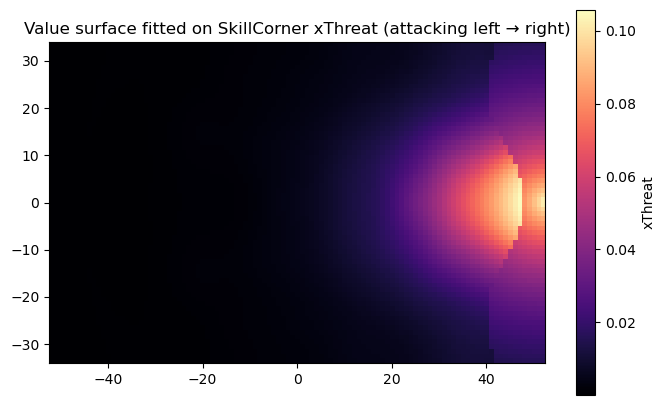

In [17]:
value_surface = fit_value_surface(events_all)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(value_surface.z, origin="lower", extent=[-52.5, 52.5, -34, 34], cmap="magma")
ax.set_title("Value surface fitted on SkillCorner xThreat (attacking left → right)")
plt.colorbar(im, ax=ax, label="xThreat")
plt.savefig(FIG_DIR / "value_surface.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
def process_match(mid: int) -> dict:
    trk, meta = load_match(mid)
    grid = Grid(meta.pitch_length, meta.pitch_width)
    ctx = MatchContext(trk, meta, grid, value_surface(grid.points), ep, dict(zip(meta.players.player_id, meta.players.role)),
                       exclude=mid if CF_LEAVE_ONE_OUT else None,
                       coarse=Grid(105.0, 68.0, res=5.0))   # fixed so maps stack across matches
    ev = events_all[events_all.match_id == mid]
    runs = match_sk_runs(detect_movements(trk, meta, ev), ev)
    scored = pd.DataFrame([score_run(ctx, r) for r in runs.itertuples()], index=runs.index)
    runs = pd.concat([runs, scored], axis=1)
    occ = score_occupation(ctx, ev)
    passes = score_passes(ctx, ev)
    line, line_def = score_defensive_line(ctx)
    lag = step_lag(trk, meta)
    return dict(runs=runs, occupation=occ, passes=passes, line=line, line_def=line_def, lag=lag)


results = {}
for mid in match_ids:
    path = OUT_DIR / f"results_{mid}_{PIPELINE_VERSION}.pkl"   # new version -> rescored automatically
    redo = RERUN_PIPELINE or not path.exists() or (RERUN_MATCHES is not None and mid in RERUN_MATCHES)
    if not redo:
        results[mid] = pd.read_pickle(path)
        continue
    try:
        results[mid] = process_match(mid)
        pd.to_pickle(results[mid], path)
        r = results[mid]
        k = r["runs"].kind.value_counts()
        print(f"{mid}: scored — {k.get('off_ball', 0)} off-ball runs, {k.get('carry', 0)} carries, "
              f"{len(r['occupation'])} options, {len(r['passes'])} passes, {len(r['line'])} line frames")
    except Exception as exc:          # keep going; report at the end
        print(f"{mid}: FAILED — {exc!r}")
print(f"{len(results)} of {len(match_ids)} matches loaded or scored")

RUNS = pd.concat([r["runs"] for r in results.values()], ignore_index=True)
OCC = pd.concat([r["occupation"] for r in results.values()], ignore_index=True)
PASSES = pd.concat([r["passes"] for r in results.values()], ignore_index=True)
LINE = pd.concat([r["line"] for r in results.values()], ignore_index=True)
LINE_DEF = pd.concat([r["line_def"] for r in results.values()], ignore_index=True)
LAG = pd.concat([r["lag"] for r in results.values()], ignore_index=True)

for name, df in dict(runs=RUNS.drop(columns=["path", "defence_map", "attack_map"]), occupation=OCC, passes=PASSES,
                     line=LINE, line_def=LINE_DEF, step_lag=LAG).items():
    df.to_csv(OUT_DIR / f"{name}.csv", index=False)
RUNS.to_pickle(OUT_DIR / "runs_full.pkl")

1925299: scored — 466 off-ball runs, 426 carries, 2715 options, 912 passes, 7238 line frames
1996435: scored — 565 off-ball runs, 387 carries, 2595 options, 877 passes, 6511 line frames
2 of 2 matches loaded or scored


## 12. Space-creation taxonomy

Each run gets one value from each **independent** classifier, so types combine freely. Categories are learned from
the data where possible; SkillCorner's run types are kept as a candidate label set.

| Classifier | Method |
|---|---|
| Run direction | DTW distance between resampled run paths → hierarchical clustering (option 1) |
| Where space is created | PCA + k-means on the created-space map (option 2), in **both lenses** |
| Creator position | role group from the line-up |
| Creator location | start zone: third × channel |
| Run type | SkillCorner label where matched; k-NN on path features for the rest (options 4 & 5) |
| Ball type into the space | next teammate pass: through ball on the ground, over the top, switch, … |
| Body orientation | from pose data where available (Section 13) |

In [19]:
def dtw_matrix(A: np.ndarray, B: np.ndarray, chunk: int = 200) -> np.ndarray:
    """Pairwise DTW between path sets A (n, T, 2) and B (m, T, 2)."""
    n, m, T = len(A), len(B), A.shape[1]
    out = np.empty((n, m))
    for c in range(0, n, chunk):
        a = A[c:c + chunk]
        cost = np.linalg.norm(a[:, None, :, None, :] - B[None, :, None, :, :], axis=-1)   # (c, m, T, T)
        D = np.full((len(a), m, T + 1, T + 1), np.inf)
        D[:, :, 0, 0] = 0
        for i in range(1, T + 1):
            for j in range(1, T + 1):
                D[:, :, i, j] = cost[:, :, i - 1, j - 1] + np.minimum(np.minimum(D[:, :, i - 1, j], D[:, :, i, j - 1]),
                                                                      D[:, :, i - 1, j - 1])
        out[c:c + chunk] = D[:, :, T, T]
    return out


def choose_k(X, ks, precomputed=False, labels_fn=None):
    best = (None, -1, None)
    for k in ks:
        lab = labels_fn(k)
        if len(set(lab)) < 2:
            continue
        s = silhouette_score(X, lab, metric="precomputed" if precomputed else "euclidean")
        if s > best[1]:
            best = (k, s, lab)
    return best


def direction_label(dx, dy):
    ang = np.degrees(np.arctan2(dy, dx))
    side = "left" if dy > 0 else "right"
    if abs(ang) <= 30:
        return "forward"
    if abs(ang) >= 150:
        return "backward"
    if abs(ang) < 75:
        return f"forward-diagonal {side}"
    if abs(ang) > 105:
        return f"backward-diagonal {side}"
    return f"lateral {side}"


def classify_run_direction(runs: pd.DataFrame, n_fit: int = 1500, ks=range(4, 11)):
    rng = np.random.default_rng(RANDOM_STATE)
    paths = np.stack(runs.path.values)
    fit = rng.choice(len(runs), min(n_fit, len(runs)), replace=False)
    Dm = dtw_matrix(paths[fit], paths[fit])
    Dm = (Dm + Dm.T) / 2
    np.fill_diagonal(Dm, 0)
    Z = linkage(squareform(Dm, checks=False), "ward")   # "average" chained ~90% of runs into one cluster
    k, sil, lab = choose_k(Dm, ks, precomputed=True, labels_fn=lambda k: fcluster(Z, k, "maxclust"))
    medoids = []
    for c in np.unique(lab):
        members = np.flatnonzero(lab == c)
        medoids.append(fit[members[Dm[np.ix_(members, members)].sum(1).argmin()]])
    assign = dtw_matrix(paths, paths[medoids]).argmin(1)
    names = {}
    for c, mi in enumerate(medoids):
        end = paths[mi][-1]
        names[c] = f"D{c}: {direction_label(*end)} (~{np.linalg.norm(end):.0f} m)"
    sizes = pd.Series([names[a] for a in assign]).value_counts(normalize=True)
    print(f"Run direction: k={k}, silhouette={sil:.2f}; largest cluster holds {sizes.iloc[0]:.0%} of runs")
    return pd.Series([names[a] for a in assign], index=runs.index), medoids


def zone_name(x, y):
    if np.isnan(x):
        return "none"
    third = "defensive third" if x < -17.5 else ("middle third" if x < 17.5 else "final third")
    ay = abs(y)
    lane = "central" if ay < 9.16 else ("half-space" if ay < 20.16 else "wide")
    side = "" if lane == "central" else (" left" if y > 0 else " right")
    return f"{lane}{side}, {third}"


def classify_space_maps(maps: np.ndarray, coarse: Grid, prefix: str, ks=range(4, 11)):
    """PCA + k-means on normalised created-space maps; clusters named by their centroid zone."""
    mass = maps.sum(1, keepdims=True)
    ok = mass[:, 0] > 1e-6
    X = maps[ok] / mass[ok]
    Xp = PCA(n_components=min(10, X.shape[1], len(X) - 1), random_state=RANDOM_STATE).fit_transform(X)
    k, sil, lab = choose_k(Xp, ks, labels_fn=lambda k: KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xp))
    names = {}
    for c in np.unique(lab):
        m = X[lab == c].mean(0)
        cx, cy = (m[:, None] * coarse.points).sum(0) / m.sum()
        names[c] = f"{prefix}{c}: {zone_name(cx, cy)}"
    out = np.full(len(maps), f"{prefix}-: no space created", dtype=object)
    out[ok] = [names[l] for l in lab]
    print(f"Space zone ({prefix}): k={k}, silhouette={sil:.2f}")
    return out


def classify_ball_type(runs: pd.DataFrame, events: pd.DataFrame, window: int = 20) -> pd.DataFrame:
    pp = events[(events.event_type == "player_possession") & (events.end_type == "pass")]
    by = {(m, t): g for (m, t), g in pp.groupby(["match_id", "team_id"])}
    out = []
    for r in runs.itertuples():
        g = by.get((r.match_id, r.team_id))
        hit = None
        if g is not None:
            # off-ball run: the ball played by a teammate; carry: the carrier's own pass at the end of the carry
            who = (g.player_id != r.player_id) if r.kind == "off_ball" else (g.player_id == r.player_id)
            c = g[(g.frame_end >= r.frame_start) & (g.frame_end <= r.frame_end + window) & who]
            if len(c):
                hit = c.iloc[0]
        if hit is None:
            out.append(("none", False))
            continue
        ty = hit.player_targeted_y_reception if pd.notna(hit.player_targeted_y_reception) else hit.player_targeted_y_pass
        dy = abs((ty if pd.notna(ty) else hit.y_end) - hit.y_end)
        if hit.furthest_line_break == "last":
            kind = "over the top" if hit.high_pass is True else "through ball on the ground"
        elif dy > 25:
            kind = "switch"
        elif hit.high_pass is True:
            kind = "lofted"
        elif hit.pass_range == "short":
            kind = "short combination"
        elif hit.furthest_line_break in ("first", "second_last"):
            kind = "line-breaking ground pass"
        else:
            kind = "other ground pass"
        out.append((kind, hit.player_targeted_id == r.player_id))
    return pd.DataFrame(out, index=runs.index, columns=["ball_type", "ball_to_runner"])


def run_type_classifier(runs: pd.DataFrame):
    """k-NN on path + start location + role, trained on SkillCorner-labelled runs, applied to the rest."""
    feats = np.c_[np.stack(runs.path.values).reshape(len(runs), -1), runs[["x_start", "y_start"]].values,
                  pd.get_dummies(runs.role_group).values.astype(float)]
    lab = runs.sk_event_subtype
    train = lab.notna().values
    if train.sum() < 30:
        print(f"Only {train.sum()} SkillCorner-labelled runs: k-NN skipped, unmatched runs left unlabelled")
        return lab.fillna("unlabelled"), np.where(train, "skillcorner", "none"), pd.Series(np.nan, index=runs.index), np.nan
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights="distance"))
    acc = cross_val_score(model, feats[train], lab[train].astype(str), cv=5).mean() if train.sum() > 50 else np.nan
    model.fit(feats[train], lab[train].astype(str))
    pred = pd.Series(model.predict(feats), index=runs.index)
    conf = pd.Series(model.predict_proba(feats).max(1), index=runs.index)
    print(f"Run-type k-NN trained on {train.sum()} SkillCorner-labelled runs; 5-fold accuracy: "
          + (f"{acc:.1%}" if pd.notna(acc) else "n/a (too few labels)"))
    final = lab.where(lab.notna(), pred)
    source = np.where(train, "skillcorner", "knn")
    return final, source, conf, acc

In [ ]:
RUNS["role_group"] = RUNS.role.map(ROLE_GROUP).fillna("OTHER")
RUNS["creator_location"] = [zone_name(x, y) for x, y in zip(RUNS.x_start, RUNS.y_start)]
RUNS["run_direction"], DIR_MEDOIDS = classify_run_direction(RUNS)
COARSE = Grid(105.0, 68.0, res=5.0)
RUNS["space_zone_defence"] = classify_space_maps(np.stack(RUNS.defence_map.values), COARSE, "S")
RUNS["space_zone_attack"] = classify_space_maps(np.stack(RUNS.attack_map.values), COARSE, "A")
RUNS = RUNS.join(classify_ball_type(RUNS, events_all))
RUNS["run_type"], RUNS["run_type_source"], RUNS["run_type_conf"], RUNTYPE_ACC = run_type_classifier(RUNS)
is_carry = RUNS.kind == "carry"
RUNS.loc[is_carry, "run_type"] = "carry (on ball)"
RUNS.loc[is_carry, "run_type_source"] = "carry"
RUNS.loc[is_carry, "run_type_conf"] = np.nan


def cosine_rows(A, B):
    return (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1) + 1e-12)


RUNS["lens_similarity"] = cosine_rows(np.stack(RUNS.defence_map.values), np.stack(RUNS.attack_map.values))
RUNS["lens_value_gap"] = RUNS.attack_only_value - RUNS.created.clip(lower=0)

# Where does the space open? Value-weighted share of the created space beyond HALF_X (the opponent's half by default).
# Movements that open no space are placed by where they end.
_dm = np.stack(RUNS.defence_map.values)
_tot = _dm.sum(1)
RUNS["opp_half_share"] = np.where(_tot > 0, _dm[:, COARSE.points[:, 0] > HALF_X].sum(1) / np.maximum(_tot, 1e-12), np.nan)
RUNS["created_opp_half"] = RUNS.created.clip(lower=0) * RUNS.opp_half_share.fillna(0)
RUNS["attacking_half"] = np.where(RUNS.opp_half_share.notna(), RUNS.opp_half_share >= 0.5, RUNS.x_end > HALF_X)
print(f"Space opens mainly beyond x = {HALF_X:g}: {RUNS.attacking_half.mean():.0%} of movements "
      f"({'kept' if OPP_HALF_ONLY else 'not filtered'})")

TAXONOMY = ["kind", "run_direction", "space_zone_defence", "space_zone_attack", "role_group", "creator_location", "run_type",
            "ball_type"]
display(RUNS[TAXONOMY].describe().T)

# Saved for the interactive dashboard (app/dashboard.py)
RUNS.to_pickle(OUT_DIR / "runs_enriched.pkl")

### 12.1 Two lenses: designed space vs real space

`lens_similarity` compares the attacking-only map (where the run *should* open space if there were no defenders)
with the defence-aware map (where space actually opened). Low similarity = the defence closed or redirected the
designed space. The cross-tab shows which designed zones turn into which real zones.

In [ ]:
bu = RUNS[RUNS.phase.isin(BUILDUP_PHASES)]
display(pd.crosstab(bu.space_zone_attack, bu.space_zone_defence, normalize="index").round(2))
display(bu.groupby("run_type")[["created", "attack_only_value", "lens_similarity"]].mean().sort_values("created",
                                                                                                      ascending=False))

space_zone_defence,S-: no space created,"S0: central, final third","S1: central, middle third","S2: central, middle third","S3: central, final third","S4: central, middle third","S5: half-space right, final third","S6: central, middle third","S7: half-space right, middle third","S8: half-space right, final third","S9: half-space left, final third"
space_zone_attack,,,,,,,,,,,
A-: no space created,0.79,0.02,0.15,0.02,0.00,0.00,0.00,0.00,0.02,0.00,0.00
"A0: central, middle third",0.74,0.00,0.13,0.07,0.01,0.01,0.00,0.03,0.00,0.00,0.01
"A1: central, final third",0.71,0.03,0.00,0.00,0.13,0.00,0.00,0.03,0.03,0.03,0.05
"A2: central, middle third",0.80,0.00,0.11,0.06,0.00,0.01,0.00,0.00,0.01,0.00,0.00
"A3: central, middle third",0.73,0.00,0.20,0.03,0.00,0.00,0.00,0.00,0.01,0.01,0.01
"A4: central, final third",0.62,0.10,0.00,0.10,0.05,0.00,0.10,0.00,0.00,0.05,0.00
"A5: central, middle third",0.64,0.05,0.05,0.02,0.02,0.07,0.00,0.05,0.05,0.04,0.00
"A6: half-space right, middle third",0.76,0.01,0.05,0.02,0.00,0.04,0.01,0.00,0.12,0.00,0.00
"A7: central, final third",0.78,0.02,0.04,0.02,0.04,0.05,0.00,0.04,0.02,0.00,0.00


,created,attack_only_value,lens_similarity
run_type,,,
behind,0.023242,0.333288,0.152718
pulling_wide,0.016724,0.300570,0.070738
carry (on ball),0.013183,0.151731,0.060314
run_ahead_of_the_ball,0.010743,0.334214,0.067351
coming_short,0.003923,0.094163,0.081698
overlap,0.003511,0.199113,0.043947
dropping_off,0.003105,0.054068,0.035829
pulling_half_space,0.002941,0.351729,0.000246
underlap,0.001566,0.549935,0.003790


### 12.2 Which space-creation types work, and against what?

Outcome per run type, split by the defending team's out-of-possession phase (high press vs mid/low block).
These are exploratory with 20 matches.

In [ ]:
oop = (events_all[["match_id", "frame_start", "team_out_of_possession_phase_type"]].dropna()
       .drop_duplicates(["match_id", "frame_start"]))
bu = pd.merge_asof(bu.sort_values("frame_start"), oop.sort_values("frame_start"), on="frame_start",
                   by="match_id", direction="backward")
display(bu.pivot_table(index="run_type", columns="team_out_of_possession_phase_type", values="created",
                       aggfunc="mean").round(3))

team_out_of_possession_phase_type,chaotic,defending_direct,defending_quick_break,high_block,low_block,medium_block
run_type,,,,,,
behind,NaN,NaN,NaN,0.000,-0.013,0.031
carry (on ball),NaN,0.000,NaN,0.003,0.056,0.007
coming_short,0.000,0.001,NaN,0.003,0.001,0.007
cross_receiver,NaN,NaN,NaN,0.000,-0.014,0.001
dropping_off,0.001,0.026,NaN,0.002,0.000,0.001
overlap,NaN,NaN,-0.016,0.000,0.005,0.004
pulling_half_space,NaN,0.000,NaN,0.000,NaN,0.004
pulling_wide,NaN,NaN,NaN,0.002,0.072,0.016
run_ahead_of_the_ball,0.012,0.000,NaN,0.001,0.005,0.015


## 13. Body orientation (pose)

Pose is the Cup's headline new data, so it is treated as a core component:

* **Shoulder heading** (SkillCorner's gated method: both shoulders present, plausible width, error ≤ 15 cm) and
  **head yaw** (nose relative to the ear midpoint), both turned into the attacking frame.
* **Orientation class** relative to the opponent goal: facing forward (< 45°), side-on / open (45–135°),
  back to goal (> 135°).
* **Scanning** before a pass: head turns of > 30° relative to the torso in the 2 s before release.
* Joined to runs (creator at run start, dragged defenders at run end), occupations and passes.

Only two matches have pose (1925299, 1996435). Download them from the Hugging Face Hub
(`SkillCorner/opendata-bodypose`, `raw/{match_id}.jsonl.zip`) into `DATA_DIR/bodypose/`. Without them the
notebook falls back to the 12-second sample phase so the code path still runs.

In [ ]:
POSE_FPS = 25
POSE_MATCHES = (1925299, 1996435)
POSE_FILES = {mid: DATA_DIR / "bodypose" / "raw" / f"{mid}.jsonl.zip" for mid in POSE_MATCHES}
POSE_SAMPLE = DATA_DIR / "bodypose" / "sample_1925299_phase406.jsonl.gz"


def iter_pose(path: Path):
    if path.suffix == ".gz":
        with gzip.open(path, "rt", encoding="utf-8") as fh:
            for line in fh:
                yield json.loads(line)
    elif path.suffix == ".zip":
        with zipfile.ZipFile(path) as z:
            with z.open(z.namelist()[0]) as fh:
                for line in fh:
                    yield json.loads(line)


def wrap180(a):
    return (np.asarray(a) + 180) % 360 - 180


def pose_rows(path: Path, meta: MatchMeta, wanted_10fps: set | None = None, max_err_cm: float = 15.0) -> pd.DataFrame:
    team_of = dict(zip(meta.players.player_id, meta.players.team_id))
    rows = []
    for rec in iter_pose(path):
        f10 = math.floor(rec["frame"] * FPS / POSE_FPS + 0.5)
        if wanted_10fps is not None and f10 not in wanted_10fps:
            continue
        for p in rec.get("player_data") or []:
            J = p.get("joints")
            if not J or "lShoulder" not in J or "rShoulder" not in J:
                continue
            (lx, ly, _), (rx, ry, _) = J["lShoulder"]["xyz"], J["rShoulder"]["xyz"]
            width = math.hypot(rx - lx, ry - ly)
            err = max(J["lShoulder"].get("p90_mae_cm") or 99, J["rShoulder"].get("p90_mae_cm") or 99)
            if not (0.15 <= width <= 0.60) or err > max_err_cm:
                continue
            shoulder = math.degrees(math.atan2(rx - lx, -(ry - ly)))      # left→right axis rotated +90°
            head = np.nan
            if all(k in J for k in ("nose", "lEar", "rEar")):
                ex, ey = (J["lEar"]["xyz"][0] + J["rEar"]["xyz"][0]) / 2, (J["lEar"]["xyz"][1] + J["rEar"]["xyz"][1]) / 2
                head = math.degrees(math.atan2(J["nose"]["xyz"][1] - ey, J["nose"]["xyz"][0] - ex))
            team = team_of.get(p["player_id"])
            s = meta.direction.get((team, rec["period"]), 1)
            flip = 0 if s == 1 else 180
            rows.append(dict(frame25=rec["frame"], frame=f10, period=rec["period"], player_id=p["player_id"],
                             team_id=team, shoulder_deg=float(wrap180(shoulder + flip)),
                             head_deg=float(wrap180(head + flip)) if not np.isnan(head) else np.nan, err_cm=err))
    df = pd.DataFrame(rows)
    if len(df):
        df["head_rel_deg"] = wrap180(df.head_deg - df.shoulder_deg)
        a = df.shoulder_deg.abs()
        df["orientation"] = np.where(a < 45, "facing forward", np.where(a <= 135, "side-on / open", "back to goal"))
    return df


def scans_before(pose: pd.DataFrame, player_id: int, frame: int, secs: float = 2.0, thr: float = 30.0) -> float:
    w = pose[(pose.player_id == player_id) & (pose.frame <= frame) & (pose.frame > frame - secs * FPS)]
    if len(w) < 10:
        return np.nan
    rel = w.sort_values("frame25").head_rel_deg.rolling(5, center=True, min_periods=1).median().values
    out = np.abs(rel) > thr
    return float(np.sum(out[1:] & ~out[:-1]))


def orientation_at(pose: pd.DataFrame, player_id, frame, tol: int = 2):
    w = pose[(pose.player_id == player_id) & ((pose.frame - frame).abs() <= tol)]
    if not len(w):
        return np.nan, None
    r = w.iloc[(w.frame - frame).abs().argmin()]
    return r.shoulder_deg, r.orientation


# Download the full pose files once (needs `pip install huggingface_hub`); skipped when they're already there.
missing = [m for m, p in POSE_FILES.items() if not p.exists()]
if missing:
    try:
        from huggingface_hub import hf_hub_download
        for mid in missing:
            hf_hub_download(repo_id="SkillCorner/opendata-bodypose", repo_type="dataset",
                            filename=f"raw/{mid}.jsonl.zip", local_dir=DATA_DIR / "bodypose")
    except Exception as exc:
        print(f"Couldn't download pose files ({exc!r}); falling back to the sample where possible")

# Parse each full file once (15–30 min) and cache every frame, so the cache survives changes to runs or passes.
pose_frames = []
for mid, path in POSE_FILES.items():
    if mid not in metas:
        continue
    cache = CACHE_DIR / f"pose_{mid}.pkl"
    if cache.exists():
        df = pd.read_pickle(cache)
        print(f"{mid}: pose loaded from cache")
    elif path.exists():
        print(f"{mid}: parsing the full pose file once (15–30 min)...")
        df = pose_rows(path, metas[mid])
        df.to_pickle(cache)
    elif mid == 1925299 and POSE_SAMPLE.exists():
        print(f"{path.name} not found -> using the 12-second sample for {mid} (not cached)")
        df = pose_rows(POSE_SAMPLE, metas[mid])
    else:
        print(f"{path.name} not found -> skipping pose for {mid}")
        continue
    pose_frames.append(df.assign(match_id=mid))
POSE = pd.concat(pose_frames, ignore_index=True) if pose_frames else pd.DataFrame()
print(f"{len(POSE):,} reliable player-frames with pose")
if len(POSE):
    print(POSE.groupby("match_id").agg(players=("player_id", "nunique"), frames=("frame", "nunique")))

1925299: parsing the full pose file once (15–30 min)...
1996435: parsing the full pose file once (15–30 min)...
3,040,425 reliable player-frames with pose
          players  frames
match_id                 
1925299        32   42787
1996435        30   38329


In [ ]:
POSE_COLS_RUNS = ["orient_start_deg", "orientation_start", "orient_end_deg", "orientation_end"]
POSE_COLS_PASSES = ["scans_2s", "passer_orient_deg"]
RUNS = RUNS.drop(columns=[c for c in POSE_COLS_RUNS if c in RUNS], errors="ignore")       # safe to re-run
PASSES = PASSES.drop(columns=[c for c in POSE_COLS_PASSES if c in PASSES], errors="ignore")

if len(POSE):
    POSE_BY = {k: g.sort_values("frame25") for k, g in POSE.groupby(["match_id", "player_id"])}
    EMPTY = POSE.iloc[:0]

    def _p(m, pid):
        return POSE_BY.get((m, pid), EMPTY)

    pr = RUNS[RUNS.match_id.isin(POSE.match_id.unique())].copy()
    o = [orientation_at(_p(r.match_id, r.player_id), r.player_id, r.frame_start) for r in pr.itertuples()]
    pr["orient_start_deg"], pr["orientation_start"] = zip(*o) if o else ([], [])
    o = [orientation_at(_p(r.match_id, r.player_id), r.player_id, r.frame_end) for r in pr.itertuples()]
    pr["orient_end_deg"], pr["orientation_end"] = zip(*o) if o else ([], [])
    RUNS = RUNS.join(pr[POSE_COLS_RUNS])

    pp_ = PASSES[PASSES.match_id.isin(POSE.match_id.unique())].copy()
    pp_["scans_2s"] = [scans_before(_p(r.match_id, r.player_id), r.player_id, r.frame_pass) for r in pp_.itertuples()]
    pp_["passer_orient_deg"] = [orientation_at(_p(r.match_id, r.player_id), r.player_id, r.frame_pass)[0]
                                for r in pp_.itertuples()]
    PASSES = PASSES.join(pp_[POSE_COLS_PASSES])

    print(f"Pose found for {RUNS.orientation_start.notna().sum():,} movements and {PASSES.scans_2s.notna().sum():,} passes")
    print("Body orientation at the start of the movement vs space created (pose matches):")
    display(RUNS.dropna(subset=["orientation_start"]).groupby(["kind", "orientation_start"])[["created", "attack_only_value"]]
            .agg(["mean", "count"]).round(3))
    print("Do early passers scan more?")
    q = PASSES.dropna(subset=["scans_2s", "lead_s"])
    if len(q) > 10:
        print(spearmanr(q.scans_2s, q.lead_s))

Pose found for 1,710 movements and 1,725 passes
Body orientation at the start of the movement vs space created (pose matches):


created       attack_only_value      
                              mean count              mean count
kind     orientation_start                                      
carry    back to goal        0.009   117             0.309   117
         facing forward      0.028   304             0.438   304
         side-on / open      0.032   380             0.568   380
off_ball back to goal        0.005   133             0.298   133
         facing forward      0.006   511             0.646   511
         side-on / open      0.019   265             0.543   265

Do early passers scan more?
SignificanceResult(statistic=0.02275336199720285, pvalue=0.39324864329641107)


## 14. Validation against SkillCorner Game Intelligence

In [ ]:
sk_runs = events_all[events_all.event_type == "off_ball_run"]
matched_ids = set(RUNS.sk_event_id.dropna())
val = {
    "SkillCorner runs found by tracking detection (recall)": len(matched_ids) / max(len(sk_runs), 1),
    "Tracking off-ball runs that match a SkillCorner run": RUNS[RUNS.kind == "off_ball"].sk_event_id.notna().mean(),
}
m = RUNS.dropna(subset=["sk_xthreat"])
if len(m) > 10:
    val["Spearman: created space vs SkillCorner run xThreat"] = spearmanr(m.created, m.sk_xthreat.astype(float))[0]
    val["Mean created, SK dangerous runs"] = m[m.sk_dangerous == True].created.mean()
    val["Mean created, SK non-dangerous runs"] = m[m.sk_dangerous == False].created.mean()

# Defensive line vs SkillCorner's last defensive line
skl = (events_all[events_all.event_type == "player_possession"]
       [["match_id", "frame_start", "team_id", "last_defensive_line_x_start"]].dropna()
       .rename(columns={"frame_start": "frame", "team_id": "team_att"}).sort_values("frame"))
lv = pd.merge_asof(LINE.sort_values("frame"), skl, on="frame", by=["match_id", "team_att"], tolerance=3,
                   direction="nearest").dropna(subset=["last_defensive_line_x_start"])
if len(lv):
    val["Line height: MAE vs SkillCorner (m)"] = (lv.line_x - lv.last_defensive_line_x_start).abs().mean()
    val["Line height: correlation with SkillCorner"] = lv[["line_x", "last_defensive_line_x_start"]].corr().iat[0, 1]

# Lead time vs how long SkillCorner's passing option had existed
opt = events_all[events_all.event_type == "passing_option"][["event_id", "frame_start"]].rename(
    columns={"event_id": "sk_option_event", "frame_start": "option_start"})
lt = PASSES.merge(opt, on="sk_option_event", how="inner").dropna(subset=["lead_s"])
if len(lt) > 10:
    lt["option_age_s"] = (lt.frame_pass - lt.option_start) / FPS
    val["Spearman: lead time vs SK option age at release"] = spearmanr(lt.lead_s, lt.option_age_s)[0]
val["Run-type k-NN accuracy vs SkillCorner"] = RUNTYPE_ACC
display(pd.Series(val).round(3).to_frame("value"))

,value
SkillCorner runs found by tracking detection (recall),0.371
Tracking off-ball runs that match a SkillCorner run,0.470
Spearman: created space vs SkillCorner run xThreat,-0.067
"Mean created, SK dangerous runs",0.004
"Mean created, SK non-dangerous runs",0.014
Line height: MAE vs SkillCorner (m),0.398
Line height: correlation with SkillCorner,0.999
Spearman: lead time vs SK option age at release,-0.063
Run-type k-NN accuracy vs SkillCorner,0.423


In [ ]:
print("Does data quality change the creator metric? (mean created by runner detection rate)")
display(RUNS.groupby(pd.cut(RUNS.runner_detected, [0, .25, .5, .75, 1.0], include_lowest=True))
        .created.agg(["mean", "count"]).round(4))

Does data quality change the creator metric? (mean created by runner detection rate)


C:\Users\bchm5\AppData\Local\Temp\ipykernel_14856\3260332289.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(RUNS.groupby(pd.cut(RUNS.runner_detected, [0, .25, .5, .75, 1.0], include_lowest=True))


,mean,count
runner_detected,,
"(-0.001, 0.25]",0.0098,74
"(0.25, 0.5]",-0.0022,47
"(0.5, 0.75]",0.0170,54
"(0.75, 1.0]",0.0180,1669


## 15. Leaderboards and team comparison

Build-up phases only, reliable rows only (runner and dragged defenders mostly on camera), per 30 minutes of the
player's team being in possession. Sample size is fixed by the competition, so a minimum-minutes cut is applied
and team comparisons are exploratory.

In [ ]:
mins = players_all.groupby("player_id").agg(name=("name", "first"), team_id=("team_id", "first"),
                                             role=("role", lambda s: s.mode().iat[0]),
                                             minutes_tip=("minutes_tip", "sum"), matches=("match_id", "nunique"))
mins["team"] = mins.team_id.map(team_names)


def per30(s):
    return s / mins.minutes_tip.reindex(s.index) * 30


R = RUNS[RUNS.phase.isin(BUILDUP_PHASES) & (RUNS.runner_detected >= 0.5)
         & ~(RUNS.dragged_detected < 0.5)]
if OPP_HALF_ONLY:
    R = R[R.attacking_half]     # only movements whose space opens mainly in the opponent's half
RO, RC = R[R.kind == "off_ball"], R[R.kind == "carry"]
creator = pd.DataFrame({"runs_p30": per30(RO.groupby("player_id").size()),
                        "created_p30": per30(RO.groupby("player_id").created.sum()),
                        "created_per_run": RO.groupby("player_id").created.mean(),
                        "drag_rate": RO.groupby("player_id").n_dragged.apply(lambda s: (s > 0).mean())})
carrier = pd.DataFrame({"carries_p30": per30(RC.groupby("player_id").size()),
                        "carry_created_p30": per30(RC.groupby("player_id").created.sum()),
                        "created_per_carry": RC.groupby("player_id").created.mean(),
                        "draw_rate": RC.groupby("player_id").n_dragged.apply(lambda s: (s > 0).mean())})

O = OCC[OCC.phase.isin(BUILDUP_PHASES) & OCC.detected]
occupier = pd.DataFrame({"occupy_value_p30": per30(O.groupby("player_id").occupy_value.sum()),
                         "in_created_p30": per30(O.groupby("player_id").in_created_space.sum()),
                         "median_latency_s": O[O.in_created_space].groupby("player_id").latency_s.median(),
                         "arrival_speed": O[O.in_created_space].groupby("player_id").arrival_speed.mean()})

F = PASSES[PASSES.phase.isin(BUILDUP_PHASES)]
F_space = F[F.opened | F.into_created_space | F.sk_line_break]
feeder = pd.DataFrame({"vision_p30": per30(F.groupby("player_id").vision_credit.sum()),
                       "space_attempts_p30": per30(F_space.groupby("player_id").size()),
                       "mean_lead_s": F_space.groupby("player_id").lead_s.mean(),
                       "completion_into_space": F_space.groupby("player_id").completed.mean(),
                       "precision": F_space.groupby("player_id").precision.mean()})


def z(s):
    return (s - s.mean()) / s.std()


board = mins.join([creator, carrier, occupier, feeder])
board = board[board.minutes_tip >= MIN_TIP_MINUTES]
print(f"{len(board)} players with ≥ {MIN_TIP_MINUTES:.0f} minutes of their team in possession")
board["execution"] = (z(board.completion_into_space) + z(board.precision)) / 2
board["feeder_score"] = W_VISION * z(board.vision_p30) + W_EXEC * z(board.execution)
board.to_csv(OUT_DIR / "player_leaderboard.csv")

cols = ["name", "team", "role", "minutes_tip"]
print("Top space creators — off-ball runs"); display(board.sort_values("created_p30", ascending=False)[cols + list(creator.columns)].head(15).round(3))
print("Top space creators — carrying the ball")
display(board.sort_values("carry_created_p30", ascending=False)[cols + list(carrier.columns)].head(15).round(3))
print("Top space occupiers"); display(board.sort_values("occupy_value_p30", ascending=False)[cols + list(occupier.columns)].head(15).round(3))
print("Top space feeders (vision weighted above execution)")
display(board.sort_values("feeder_score", ascending=False)[cols + list(feeder.columns) + ["feeder_score"]].head(15).round(3))

0 players with ≥ 45 minutes of their team in possession
Top space creators — off-ball runs


,name,team,role,minutes_tip,runs_p30,created_p30,created_per_run,drag_rate
player_id,,,,,,,,


Top space creators — carrying the ball


,name,team,role,minutes_tip,carries_p30,carry_created_p30,created_per_carry,draw_rate
player_id,,,,,,,,


Top space occupiers


,name,team,role,minutes_tip,occupy_value_p30,in_created_p30,median_latency_s,arrival_speed
player_id,,,,,,,,


Top space feeders (vision weighted above execution)


,name,team,role,minutes_tip,vision_p30,space_attempts_p30,mean_lead_s,completion_into_space,precision,feeder_score
player_id,,,,,,,,,,


In [ ]:
team_tip = players_all.groupby(["match_id", "team_id"]).minutes_tip.max().groupby("team_id").sum()
line_team = LINE[LINE.phase.isin(BUILDUP_PHASES)].groupby("team_def").agg(
    line_depth=("depth", "mean"), spread_stepping_up=("spread", lambda s: s[LINE.loc[s.index, "stepping_up"]].mean()),
    gk_gap=("gk_gap", "mean"), space_behind=("space_behind", "mean"), conceded_by_line=("conceded_by_line", "mean"))
teams = pd.DataFrame({
    "created_offball_p30": RO.groupby("team_id").created.sum() / team_tip * 30,
    "created_carry_p30": RC.groupby("team_id").created.sum() / team_tip * 30,
    "occupy_value_p30": O.groupby("team_id").occupy_value.sum() / team_tip * 30,
    "vision_p30": F.groupby("team_id").vision_credit.sum() / team_tip * 30,
    "completion_into_space": F_space.groupby("team_id").completed.mean(),
}).join(line_team.add_prefix("def_"))
teams.index = teams.index.map(team_names)
teams.to_csv(OUT_DIR / "team_comparison.csv")
display(teams.sort_values("created_offball_p30", ascending=False).round(3))

,created_offball_p30,created_carry_p30,occupy_value_p30,vision_p30,completion_into_space,def_line_depth,def_spread_stepping_up,def_gk_gap,def_space_behind,def_conceded_by_line
team_id,,,,,,,,,,
Adelaide United,2.154,1.605,0.002,0.012,0.916,39.807,3.476,24.843,35.529,0.491
Sydney FC,1.326,2.380,0.005,0.021,0.928,41.836,2.547,25.183,36.519,0.365
Perth Glory,0.941,0.851,0.004,0.009,0.907,37.008,1.793,23.301,34.650,0.299
Brisbane FC,0.324,0.614,0.003,0.009,0.942,40.552,2.158,24.692,35.717,0.490


In [ ]:
late = (LAG.groupby("player_id").agg(lag_s=("lag_s", "mean"), sync_r=("sync_r", "mean"), matches=("match_id", "nunique"))
        .join(LINE_DEF.groupby("player_id").conceded_share.sum().rename("conceded_by_line"))
        .join(mins[["name", "team", "role"]]))
print("Back-line synchrony: late steppers and space conceded by not holding the line")
display(late.sort_values("conceded_by_line", ascending=False).head(15).round(3))

Back-line synchrony: late steppers and space conceded by not holding the line


,lag_s,sync_r,matches,conceded_by_line,name,team,role
player_id,,,,,,,
809759,0.0,0.891,1,806.207,P. Kikianis,Adelaide United,LCB
26766,-0.1,0.892,1,729.384,B. Vriends,Adelaide United,RCB
809166,0.0,0.888,1,654.604,A. Lebib,Perth Glory,RCB
965697,-0.2,0.915,1,553.981,L. Herrington,Brisbane FC,RCB
51644,-0.1,0.890,1,441.223,R. Grant,Sydney FC,RCB
998256,-0.1,0.905,1,420.086,K. Shaw,Sydney FC,LCB
560989,-0.2,0.883,1,303.321,T. Mrčela,Perth Glory,LCB
69111,-0.1,0.885,1,238.604,H. Bility,Brisbane FC,LCB
11897,0.2,0.791,1,138.209,J. Risdon,Perth Glory,RB


## 16. Visuals for case studies

Each case shows: actual pitch control, the **created** map (defence-aware lens) with dragged defenders and their
expected spots, and the **attacking-only** map. The title carries the period and match clock so the moment can be
found in broadcast footage and shown side by side. `animate_run` writes a GIF of the same moment.
* **Timing.** Each GIF starts 2.5 s before the movement and runs until 3 s after the moment the opened space is
  largest. It holds for 0.8 s when the movement starts and for 2.5 s at that peak, when green arrows show up to three
  teammates who can use the space (main beneficiary bold, others with at least 15% of the usable space) and where each
  should go. Stills are drawn at the same peak moment.
* **Focus.** With `OPP_HALF_ONLY = True`, cases, the review sample and the leaderboards keep only movements whose space
  opens mainly beyond `HALF_X` (the halfway line; set it to 17.5 for the final third).
* **Lens overlap (review GIFs).** Designed space (attacking-only) and real space (defence-aware) are each scaled to
  their own maximum over the play; their overlap is the smaller of the two at each spot, i.e. space that is both planned
  for and actually open (gold). The **prime moment** is when total overlap peaks and the **prime window** the stretch
  around it above half that peak. The first pass after the movement starts is labelled early / on time / late against
  that window, and whether it went into prime space. Each review case gets an extra still, `C##_overlap.png`.
* **Beneficiary targets must be free now**, not just newly opened: attacking control ≥ 0.5 at the spot, no defender
  within 3 m, and spots where another teammate already stands count only 20% for this player. If none of the opened
  space passes those checks, no beneficiary is shown.
* **Vacated-spot plays only** (`VACATED_ONLY = True`): cases, the credited review strata and the showcase keep only plays
  where, at the peak, the best opened space lies within `VACATED_R` (8 m) of a dragged defender's expected spot that he
  has left — and so does the main beneficiary's target, if there is one. This is the pattern coaches and scouts can
  recognise and reproduce: a defender is pulled away and a teammate moves into the spot he should have held. The
  "not credited" and "low data quality" review strata are unchanged (they exist to catch misses). Leaderboards are not
  filtered.
* **Live green space in the GIFs:** the space opened for teammates is drawn on every frame from the start of the
  movement (one fixed colour scale per GIF), and the arrows follow the best spots as that space moves, smoothed across
  frames. Arrows appear once the space reaches 20% of its peak.
* **Covered vacated spots:** a vacated spot only counts if it isn't still held. Defenders within `COVER_R` (6 m) of the
  spot are counted against teammates who can get there within `COVER_T` (1.5 s). No defenders = *clear*; more teammates
  than defenders = *overload* (kept); otherwise *covered* (dropped). Stills draw the 6 m circle (green clear, purple
  overload) and state the count.
* **The analysis stops at the pass.** The peak, prime moment, prime window, green space and arrows are only computed up
  to the first pass after the movement starts. The GIF keeps playing to show how the play panned out (with an X where
  the ball went), but nothing model-based is drawn after the pass — that would be a new situation.
* **Keepers are never part of the drawing scheme (v5):** keepers are not movers, never count as pulled defenders, and
  space behind the defending keeper (or within `KEEPER_BUFFER_M` of his line) is never counted.
* **Who can run into the space:** never a centre-back or keeper (`BEN_EXCLUDE_GROUPS`), never the mover himself.
* **Team plays** (`build_team_plays`, `team_scene`): all movements by one team in the same moment, grouped. A movement
  joins a play if it starts within `TEAMPLAY_JOIN_S` (1 s) of the play's end and before the play's first pass; a new
  team, a pass or a longer gap starts a new play. In a team play the space is what all credited pulls open together, for
  players who are not movers. The dashboard shows each play from `TEAMPLAY_LEAD_S` before to `TEAMPLAY_BUFFER_S` after
  (display only).
* **Team plays use abnormal movers only:** a player moving up with his team is an ordinary teammate (and can be suggested
  as the runner into the space); only abnormal movements are ringed, drawn and credited. `n_moves` counts those.
* **One green arrow by default** (`TOP_BENEFICIARIES = 1`): only the best suggestion is drawn, so several players aren't
  sent to the same spot. The dashboard has a toggle to show all of them.

In [ ]:
from matplotlib.lines import Line2D
import textwrap

KIND_STYLE = {"off_ball": dict(color="#d62728", label="off-ball run"),
              "carry": dict(color="#ff7f0e", label="carry (on ball)")}
ATT_C, DEF_C, BEN_C = "#d62728", "#1f77b4", "#2ca02c"

# Who benefits from the space? Arrival-time model (Spearman-style): each player reacts for 0.7 s along his current
# velocity, then runs straight at 7 m/s. A teammate's chance of getting to a cell first is a logistic of how much
# sooner he arrives than the quickest defender.
REACTION_S, VMAX, ARRIVAL_SIGMA = 0.7, 7.0, 0.45

# GIF timing: enough play before the movement to read the situation, and enough after the space peaks to see
# whether anyone uses it. The GIF holds still at the start of the movement and when the space is at its largest.
GIF_PRE_S, GIF_POST_S = 2.5, 3.0
PAUSE_START_S, PAUSE_PEAK_S = 0.8, 2.5
PEAK_SEARCH_S = 2.0          # look this long after the movement ends for the moment the space is largest
TOP_BENEFICIARIES = 1        # arrows drawn at the peak (only the best suggestion by default; 3 shows more)
MIN_BEN_SHARE = 0.15         # ...for teammates with at least this share of the usable space


def arrival_times(xy, vel, points):
    p = xy + vel * REACTION_S
    return REACTION_S + np.linalg.norm(points[None] - p[:, None], axis=-1) / VMAX


# A target spot must be usable NOW, not just newly opened: the attacking team controls it, no defender is on top of it,
# and no other teammate is already standing there.
TARGET_MIN_CONTROL = 0.5     # teammates' pitch control needed at the spot (0.5 = more attacking than defending)
DEF_CLEAR_M = 3.0            # a spot with a defender closer than this is not open at all...
OPEN_SCALE_M = 6.0           # ...and it counts as fully open once the nearest defender is this far away
TEAM_CLEAR_M = 3.0           # spots this close to ANOTHER teammate count for little for this player...
CROWD_FACTOR = 0.2           # ...only 20% of their value

# Weights for the spot score (powers): 1 = as before, 2 = matters much more, 0.5 = softer, 0 = ignore it
W_SPACE = 1.0                # space created there
W_VALUE = 1.0                # how dangerous the spot is (lower this if arrows still chase the goal)
W_FREE = 2.0                 # how free the spot is now: control and distance from the nearest defender
W_REACH = 1.0                # his chance of getting there first

def find_beneficiary(ctx, run, i, created, exclude_pids=()) -> dict | None:
    """Teammates who can use the opened space. Each spot counts by
    (space created there) × value × how free it is now (attacking control above 0.5, no defender within 3 m)
    × his chance of getting there first × (reduced if another teammate is already there).
    Returns the main beneficiary plus a ranking with each teammate's best target spot."""
    trk, pts = ctx.trk, ctx.grid.points
    st = frame_state(trk, i, run.team_id)
    excl = set(int(p) for p in exclude_pids) | {int(run.player_id)}
    att = np.array([k for k in st["att"] if int(trk.player_ids[k]) not in excl
                    and ROLE_GROUP.get(ctx.role.get(trk.player_ids[k]), "OTHER") not in BEN_EXCLUDE_GROUPS
                    and ctx.role.get(trk.player_ids[k]) != "GK"])
    if len(att) == 0:
        return None
    P, V, ball = st["pos"], st["vel"], st["ball"]
    mover = [k for k in st["att"] if trk.player_ids[k] == run.player_id]
    mates = np.array([k for k in st["att"] if k not in mover])
    pc = pitch_control(P[mates], V[mates], P[st["dfn"]], V[st["dfn"]], ball, pts)
    control_free = np.clip((pc - TARGET_MIN_CONTROL) / (1 - TARGET_MIN_CONTROL), 0, 1)
    d_def = np.linalg.norm(pts[None] - P[st["dfn"]][:, None], axis=-1).min(0)
    openness = np.clip((d_def - DEF_CLEAR_M) / (OPEN_SCALE_M - DEF_CLEAR_M), 0, 1)   # 0 within 3 m, 1 from 6 m
    free = control_free * openness
    gain = (np.clip(created, 0, None) ** W_SPACE) * (ctx.value_grid ** W_VALUE) * (free ** W_FREE)
    if gain.sum() <= 0:
        return None                                                   # space opened, but none of it is usable now
    t_att = arrival_times(P[att], V[att], pts)
    t_def = arrival_times(P[st["dfn"]], V[st["dfn"]], pts).min(0)
    ease = 1 / (1 + np.exp(-(t_def - t_att) / ARRIVAL_SIGMA))          # (teammates, cells)
    near = np.linalg.norm(pts[None] - P[att][:, None], axis=-1) < TEAM_CLEAR_M   # (teammates, cells)
    others_there = near.sum(0)[None] - near                            # other teammates already at each spot
    crowd = np.where(others_there > 0, CROWD_FACTOR, 1.0)
    score = (ease ** W_REACH) * gain[None] * crowd
    benefit = score.sum(1) * ctx.grid.cell_area
    if benefit.max() <= 0:
        return None
    best_c = np.argmax(score, axis=1)                                   # each teammate's best spot
    rows = np.arange(len(att))
    ranking = pd.DataFrame({"player_id": trk.player_ids[att], "col": att, "benefit": benefit,
                            "share": benefit / max(benefit.sum(), 1e-12),
                            "tx": pts[best_c, 0], "ty": pts[best_c, 1], "time_s": t_att[rows, best_c],
                            "ease": ease[rows, best_c],
                            "dist_m": np.linalg.norm(pts[best_c] - P[att], axis=1),
                            "control_at_spot": pc[best_c], "nearest_def_m": d_def[best_c]}
                           ).sort_values("benefit", ascending=False)
    ranking["name"] = ranking.player_id.map(mins["name"])
    top = ranking.iloc[0]
    return dict(col=int(top.col), player_id=int(top.player_id), name=top["name"], target=np.array([top.tx, top.ty]),
                benefit=float(top.benefit), share=float(top.share), time_s=float(top.time_s), ease=float(top.ease),
                dist_m=float(top.dist_m), control=float(top.control_at_spot), nearest_def_m=float(top.nearest_def_m),
                ranking=ranking, frame_idx=int(i))


def draw_pitch(ax, L=105, W=68, color="#999"):
    ax.plot([-L / 2, L / 2, L / 2, -L / 2, -L / 2], [-W / 2, -W / 2, W / 2, W / 2, -W / 2], color=color, lw=1)
    ax.plot([0, 0], [-W / 2, W / 2], color=color, lw=1)
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=False, color=color, lw=1))
    for s in (-1, 1):
        ax.plot([s * L / 2, s * (L / 2 - 16.5), s * (L / 2 - 16.5), s * L / 2], [-20.16, -20.16, 20.16, 20.16], color=color, lw=1)
        ax.plot([s * L / 2, s * (L / 2 - 5.5), s * (L / 2 - 5.5), s * L / 2], [-9.16, -9.16, 9.16, 9.16], color=color, lw=1)
    ax.set_xlim(-L / 2 - 2, L / 2 + 2); ax.set_ylim(-W / 2 - 2, W / 2 + 2); ax.set_aspect("equal"); ax.axis("off")


def match_clock(trk, i):
    p = trk.period[i]
    start = trk.frames[trk.period == p].min()
    secs = (trk.frames[i] - start) / FPS + (45 * 60 if p == 2 else 0)
    return f"P{p} {int(secs // 60):02d}:{int(secs % 60):02d}"


def build_ctx(mid):
    trk, meta = load_match(mid)
    grid = Grid(meta.pitch_length, meta.pitch_width)
    return MatchContext(trk, meta, grid, value_surface(grid.points), ep, dict(zip(meta.players.player_id, meta.players.role)),
                        exclude=mid if CF_LEAVE_ONE_OUT else None, coarse=COARSE)


def run_scene(ctx, run, i, with_created=False):
    """Positions, teammates' pitch control and dragged-defender arrows at index i, in the attacking frame."""
    trk, g = ctx.trk, ctx.grid
    st = frame_state(trk, i, run.team_id)
    j = int(np.flatnonzero(trk.player_ids == run.player_id)[0])
    att = np.array([k for k in st["att"] if k != j])
    P, V, ball = st["pos"], st["vel"], st["ball"]
    pc = pitch_control(P[att], V[att], P[st["dfn"]], V[st["dfn"]], ball, g.points)
    drag_cols = [k for k in st["dfn"] if trk.player_ids[k] in set(run.dragged_ids)
                 and ctx.role.get(trk.player_ids[k]) != "GK"]
    exp = ctx.expected(drag_cols, "out", ball, trk.phase[i], P) if drag_cols else np.zeros((0, 2))
    a, e = int(run.idx_start), int(run.idx_end)
    trail = trk.pos[a:min(i, e) + 1, j] * st["sign"] if i >= a else np.zeros((0, 2))
    scene = dict(P=P, att=st["att"], dfn=st["dfn"], ball=ball, runner=P[j], pc=pc, trail=trail,
                 drag_now=P[drag_cols] if drag_cols else np.zeros((0, 2)), drag_exp=exp)
    if with_created:
        scene["created"] = np.zeros(len(g.points))
        if drag_cols:
            Dr, Dv = P[st["dfn"]].copy(), V[st["dfn"]].copy()
            sel = np.isin(st["dfn"], drag_cols)
            ok = ~np.isnan(exp[:, 0])
            Dr[np.flatnonzero(sel)[ok]], Dv[np.flatnonzero(sel)[ok]] = exp[ok], 0
            scene["created"] = (pc - pitch_control(P[att], V[att], Dr, Dv, ball, g.points)) * keeper_mask(ctx, st)
    return scene


def designed_map(ctx, run, i):
    """Attacking-only lens at full resolution: space the mover vacates relative to his expected spot, weighted by how
    well his teammates can reach it (no defenders). Same formula as in score_run, on the 2 m grid."""
    trk, pts = ctx.trk, ctx.grid.points
    st = frame_state(trk, i, run.team_id)
    j = int(np.flatnonzero(trk.player_ids == run.player_id)[0])
    att = np.array([k for k in st["att"] if k != j])
    P, V, ball = st["pos"], st["vel"], st["ball"]
    Er = ctx.expected([j], "in", ball, trk.phase[i], P)[0]
    if np.isnan(Er[0]) or len(att) == 0:
        return np.zeros(len(pts))
    i_exp = influence(Er[None], np.zeros((1, 2)), ball, pts)[0]
    i_act = influence(P[[j]], V[[j]], ball, pts)[0]
    team_use = 1 - np.exp(-influence(P[att], V[att], ball, pts).sum(0))
    return np.clip(i_exp - i_act, 0, None) * team_use * keeper_mask(ctx, st)


def pass_cutoff(ctx, run):
    """Index of the first pass by the movement's team from the start of the movement (None if there isn't one in the
    data). Space, prime areas and arrows are only computed up to here: once the ball is played it's a new situation."""
    trk = ctx.trk
    if "PASSES" not in globals() or not len(PASSES):
        return None
    f0 = trk.frames[int(run.idx_start)]
    p = PASSES[(PASSES.match_id == run.match_id) & (PASSES.team_id == run.team_id) & (PASSES.frame_pass >= f0)]
    if not len(p):
        return None
    i = int(trk.idx(int(p.frame_pass.min())))
    return i if i >= 0 else None


def pass_info(ctx, run):
    """The first pass after the movement starts: index, passer, receiver and target (attacking frame)."""
    trk = ctx.trk
    if "PASSES" not in globals() or not len(PASSES):
        return None
    f0 = trk.frames[int(run.idx_start)]
    p = PASSES[(PASSES.match_id == run.match_id) & (PASSES.team_id == run.team_id)
               & (PASSES.frame_pass >= f0)].sort_values("frame_pass")
    if not len(p):
        return None
    r = p.iloc[0]
    i = int(trk.idx(int(r.frame_pass)))
    if i < 0:
        return None
    return dict(idx=i, passer=int(r.player_id), receiver=int(r.target_id), target=np.array([r.target_x, r.target_y]),
                completed=bool(r.completed))


def space_peak(ctx, run, step: int = 2):
    """Frame index where the space opened for teammates is largest (value-weighted), from movement start to
    PEAK_SEARCH_S after it ends — but never after the ball is played."""
    trk = ctx.trk
    a, e = int(run.idx_start), int(run.idx_end)
    hi = min(e + int(PEAK_SEARCH_S * FPS), len(trk.frames) - 1)
    cut = pass_cutoff(ctx, run)
    if cut is not None:
        hi = max(min(hi, cut), a)
    idxs = np.arange(a, hi + 1, step)
    idxs = idxs[trk.period[idxs] == trk.period[a]]
    vals = [float((np.clip(run_scene(ctx, run, i, with_created=True)["created"], 0, None) * ctx.value_grid).sum())
            for i in idxs]
    k = int(np.argmax(vals)) if len(vals) else 0
    return (int(idxs[k]) if len(idxs) else e), (vals[k] if vals else 0.0)


def gif_window(ctx, run, peak):
    trk = ctx.trk
    a, e = int(run.idx_start), int(run.idx_end)
    lo = max(a - int(GIF_PRE_S * FPS), 0)
    hi = min(max(e, peak) + int(GIF_POST_S * FPS), len(trk.frames) - 1)
    idxs = np.arange(lo, hi + 1)
    return idxs[trk.period[idxs] == trk.period[a]]


def draw_beneficiaries(ax, P, ben, top=TOP_BENEFICIARIES, min_share=MIN_BEN_SHARE):
    """Arrows from each teammate who can use the space to his best spot in it. The main beneficiary is bold."""
    if ben is None:
        return
    rk = ben["ranking"]
    rk = rk[(rk.share >= min_share) | (rk.index == rk.index[0])].head(top)
    for n, r in enumerate(rk.itertuples()):
        pos, tgt = P[int(r.col)], np.array([r.tx, r.ty])
        main = n == 0
        ax.scatter(*pos, s=260 if main else 180, facecolors="none", edgecolors=BEN_C, lw=2.2 if main else 1.4,
                   alpha=1 if main else .75, zorder=5)
        ax.scatter(*tgt, marker="*", s=260 if main else 150, c=BEN_C, edgecolors="white", lw=.8,
                   alpha=1 if main else .75, zorder=6)
        ax.annotate("", xy=tgt, xytext=pos, zorder=6,
                    arrowprops=dict(arrowstyle="-|>", color=BEN_C, lw=2.2 if main else 1.4, ls="--",
                                    alpha=1 if main else .75, shrinkA=8, shrinkB=8))
        label = f"{r.name} ({r.share:.0%})"
        ax.annotate(label, pos, xytext=(0, 13), textcoords="offset points", ha="center", color=BEN_C,
                    fontsize=8 if main else 7, weight="bold" if main else "normal", zorder=7,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=.75))


def draw_beneficiary(ax, pos, ben):
    """Main beneficiary only (kept so older cells still work)."""
    P = {int(ben["col"]): pos}
    draw_beneficiaries(ax, P, dict(ben, ranking=ben["ranking"].head(1)))


def draw_scene(ax, scene, run, show_arrows=True):
    """Players, runner ring, path and the 'pulled from → ended up' arrows for dragged/drawn defenders."""
    style = KIND_STYLE[run.kind]
    ax.scatter(*scene["P"][scene["att"]].T, c=ATT_C, s=45, zorder=4, edgecolors="white", lw=.5)
    ax.scatter(*scene["P"][scene["dfn"]].T, c=DEF_C, s=45, zorder=4, edgecolors="white", lw=.5)
    if len(scene["trail"]) > 1:
        ax.plot(*scene["trail"].T, c=style["color"], lw=2.5, zorder=3, ls="-" if run.kind == "carry" else "--")
    ax.scatter(*scene["runner"], s=260, facecolors="none", edgecolors="black", lw=2, zorder=5)
    ax.scatter(*scene["ball"], c="black", s=22, zorder=6)
    if show_arrows:
        for e, now in zip(scene["drag_exp"], scene["drag_now"]):
            if np.isnan(e[0]):
                continue
            ax.scatter(*e, s=60, facecolors="none", edgecolors=DEF_C, lw=1.5, zorder=4)
            ax.annotate("", xy=now, xytext=e, zorder=5,
                        arrowprops=dict(arrowstyle="-|>", color=DEF_C, lw=1.8, shrinkA=4, shrinkB=5))


def legend_handles(run):
    style = KIND_STYLE[run.kind]
    pulled = "pulled by the run" if run.kind == "off_ball" else "drawn by the carrier"
    return [Line2D([], [], marker="o", ls="", color=ATT_C, label="team in possession (attacking →)"),
            Line2D([], [], marker="o", ls="", color=DEF_C, label="defending team"),
            Line2D([], [], marker="o", ls="", mfc="none", mec="black", mew=2, ms=11,
                   label="the runner" if run.kind == "off_ball" else "the ball carrier"),
            Line2D([], [], color=style["color"], lw=2.5, ls="-" if run.kind == "carry" else "--", label=f"path of the {style['label']}"),
            Line2D([], [], marker="o", ls="", mfc="none", mec=DEF_C, ms=8, label="defender's expected spot"),
            Line2D([], [], color=DEF_C, marker=">", lw=1.8, label=f"defender {pulled}: expected spot → where he ended up"),
            Line2D([], [], marker="o", ls="", mfc="none", mec=BEN_C, mew=2, ms=11, label="teammates who can use the space (share)"),
            Line2D([], [], color=BEN_C, ls="--", marker="*", ms=10, lw=2, label="where they should go (best spot)")]


def case_title(ctx, run, i):
    name = mins["name"].get(run.player_id, run.player_id)
    team = team_names.get(run.team_id, "")
    what = KIND_STYLE[run.kind]["label"] if run.kind == "carry" else f"off-ball run ({run.run_type})"
    return (f"{name} ({team}) — {what} | {match_clock(ctx.trk, i)} | "
            f"match {run.match_id} | space created {run.created:.3f}")


def beneficiary_text(ben):
    return (f"Main beneficiary: {ben['name']} — {ben['share']:.0%} of the usable space, best spot {ben['dist_m']:.0f} m "
            f"away (~{ben['time_s']:.1f} s), {ben['control']:.0%} attacking control there, nearest defender "
            f"{ben['nearest_def_m']:.0f} m, {ben['ease']:.0%} chance to get there first")


def wrap_lines(*lines, width=110):
    return "\n".join(textwrap.fill(l, width) for l in lines if l)


def plot_run_case(run, ctx=None, save=True, peak=None):
    """Three panels at the moment the opened space is largest."""
    ctx = ctx or build_ctx(run.match_id)
    g = ctx.grid
    if peak is None:
        peak, _ = space_peak(ctx, run)
    sc = run_scene(ctx, run, peak, with_created=True)
    created = sc["created"]
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
    panels = [(sc["pc"], "RdBu_r", 0, 1, "Teammates' pitch control (red = attacking team)"),
              (np.clip(created, 0, None) * ctx.value_grid, "Greens", 0, None,
               f"Space created for teammates — at its largest ({match_clock(ctx.trk, peak)})"),
              (designed_map(ctx, run, peak) * ctx.value_grid, "Purples", 0, None, "Designed space (attacking-only lens)")]
    ben = find_beneficiary(ctx, run, peak, created)
    vac = vacated_check(ctx, run, peak=peak, sc=sc, ben=ben)
    for ax, (m, cmap, lo, hi, title) in zip(axes, panels):
        draw_pitch(ax)
        shape = (g.ny, g.nx) if m.size == g.nx * g.ny else (COARSE.ny, COARSE.nx)
        ax.imshow(m.reshape(shape), origin="lower", extent=[-52.5, 52.5, -34, 34], cmap=cmap, alpha=.75,
                  vmin=lo, vmax=hi if hi is not None else max(np.nanmax(m), 1e-9))
        draw_scene(ax, sc, run)
        if ax is not axes[2]:      # the attacking-only lens has no defenders to beat
            draw_beneficiaries(ax, sc["P"], ben)
            draw_cover(ax, vac)
        ax.set_title(title, fontsize=10)
    fig.legend(handles=legend_handles(run), loc="lower center", ncol=4, fontsize=9, frameon=False)
    fig.suptitle(wrap_lines(case_title(ctx, run, peak), beneficiary_text(ben) if ben else "", cover_text(vac),
                            width=160), fontsize=11)
    fig.subplots_adjust(bottom=0.12, top=0.86)
    if save:
        (FIG_DIR / "cases").mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / "cases" / f"{run.kind}_{run.match_id}_{run.frame_end}.png", dpi=150, bbox_inches="tight")
    plt.show()
    return ctx, ben


def frame_sequence(idxs, a, peak, with_peak_pause=True):
    """Frames to draw, with holds at the start of the movement and at the peak."""
    seq = []
    for i in idxs:
        seq.append((int(i), None))
        if i == a:
            seq += [(int(i), "movement starts")] * int(PAUSE_START_S * FPS)
        if with_peak_pause and i == peak:
            seq += [(int(i), "PAUSED — space at its largest: where teammates should go")] * int(PAUSE_PEAK_S * FPS)
    return seq


COVER_R = 6.0     # m around the vacated spot: defenders here mean the spot is still covered...
COVER_T = 1.5     # ...unless more teammates can get there within this many seconds (an overload)


def vacated_check(ctx, run, peak=None, sc=None, ben="compute") -> dict:
    """Does the space open where a dragged defender should have been? At the peak moment, the best opened spot must be
    within VACATED_R of a dragged defender's expected spot (one he has left), and so must the main beneficiary's target
    if there is one."""
    if peak is None:
        peak, _ = space_peak(ctx, run)
    if sc is None:
        sc = run_scene(ctx, run, peak, with_created=True)
    out = dict(vacated=False, peak=peak, space_to_spot=np.nan, target_to_spot=np.nan, ben=None, spot=None,
               defenders_near=0, attackers_near=0, cover="none")
    exp, now = sc["drag_exp"], sc["drag_now"]
    if not len(exp):
        return out
    ok = ~np.isnan(exp[:, 0]) & (np.linalg.norm(now - exp, axis=1) >= DRAG_MIN_DEV)
    gain = np.clip(sc["created"], 0, None) * ctx.value_grid
    if not ok.any() or gain.sum() <= 0:
        return out
    spots = exp[ok]
    hot = ctx.grid.points[int(np.argmax(gain))]
    out["space_to_spot"] = float(np.linalg.norm(spots - hot, axis=1).min())
    if isinstance(ben, str):
        ben = find_beneficiary(ctx, run, peak, sc["created"])
    out["ben"] = ben
    if ben is not None:
        out["target_to_spot"] = float(np.linalg.norm(spots - ben["target"], axis=1).min())
    # Is the vacated spot still covered? Count defenders standing within COVER_R of it, and teammates (not the mover
    # or the keeper) who can get there within COVER_T. Covered = defenders there and no overload.
    spot = spots[int(np.argmin(np.linalg.norm(spots - hot, axis=1)))]
    out["spot"] = spot
    trk = ctx.trk
    st = frame_state(trk, peak, run.team_id)
    P, V = st["pos"], st["vel"]
    n_def = int((np.linalg.norm(P[st["dfn"]] - spot, axis=1) <= COVER_R).sum())
    mates = np.array([k for k in st["att"] if trk.player_ids[k] != run.player_id
                      and ctx.role.get(trk.player_ids[k]) != "GK"])
    n_att = int((arrival_times(P[mates], V[mates], spot[None])[:, 0] <= COVER_T).sum()) if len(mates) else 0
    out["defenders_near"], out["attackers_near"] = n_def, n_att
    out["cover"] = "clear" if n_def == 0 else ("overload" if n_att > n_def else "covered")
    out["vacated"] = bool(out["space_to_spot"] <= VACATED_R
                          and (ben is None or out["target_to_spot"] <= VACATED_R)
                          and out["cover"] != "covered")
    return out


def cover_text(v):
    if v.get("spot") is None:
        return ""
    d, a = v["defenders_near"], v["attackers_near"]
    verdict = {"clear": "vacated spot is clear", "overload": "OVERLOAD — more attackers than defenders can get there",
               "covered": "COVERED — defenders still hold the spot"}[v["cover"]]
    return f"Vacated spot: {d} defender(s) within {COVER_R:.0f} m, {a} teammate(s) within {COVER_T:.1f} s — {verdict}"


def draw_cover(ax, v):
    if v.get("spot") is None:
        return
    color = {"clear": BEN_C, "overload": "#9467bd", "covered": "#7f7f7f"}[v["cover"]]
    ax.add_patch(plt.Circle(tuple(v["spot"]), COVER_R, fill=False, ls=":", lw=1.6, color=color, zorder=3))


def filter_vacated(df: pd.DataFrame) -> pd.DataFrame:
    """Keep movements whose space opens at a vacated defender spot (checked match by match; order preserved)."""
    if not len(df):
        return df.assign(space_to_spot=[], target_to_spot=[])
    keep = {}
    for mid, g in df.groupby("match_id", sort=False):
        ctx = build_ctx(mid)
        for run in g.itertuples():
            v = vacated_check(ctx, run)
            if v["vacated"]:
                keep[run.Index] = v
    out = df.loc[[k for k in df.index if k in keep]].copy()
    out["space_to_spot"] = [keep[k]["space_to_spot"] for k in out.index]
    out["target_to_spot"] = [keep[k]["target_to_spot"] for k in out.index]
    out["cover"] = [keep[k]["cover"] for k in out.index]
    print(f"Vacated-spot filter: {len(out)} of {len(df)} movements kept "
          f"(clear {sum(v['cover'] == 'clear' for v in keep.values())}, "
          f"overload {sum(v['cover'] == 'overload' for v in keep.values())})")
    return out


LIVE_MIN_FRAC = 0.2      # live arrows appear once the opened space reaches this share of its peak
LIVE_SMOOTH = 0.35       # how quickly live targets follow the space (lower = steadier arrows)


def animate_run(run, ctx=None, fname=None):
    """GIF: 2.5 s of build-up, the movement, a pause when the opened space is largest, then 3 s of what happened next.
    The green layer is the space opened for teammates on every frame, and the arrows follow the best spots to move to
    as that space shifts (smoothed so they don't jitter)."""
    ctx = ctx or build_ctx(run.match_id)
    trk, g = ctx.trk, ctx.grid
    a, e = int(run.idx_start), int(run.idx_end)
    peak, _ = space_peak(ctx, run)
    idxs = gif_window(ctx, run, peak)
    pinfo = pass_info(ctx, run)
    cut = pinfo["idx"] if pinfo else None
    seq = []
    for k_i, lab in frame_sequence(idxs, a, peak):
        seq.append((k_i, lab))
        if cut is not None and k_i == cut and lab is None:
            seq += [(k_i, "BALL PLAYED — the play continues; space is no longer computed")] * FPS
    scenes, bens = {}, {}
    for i in idxs:                                   # precompute so the colour scale is fixed across the GIF
        i = int(i)
        scenes[i] = run_scene(ctx, run, i, with_created=True)
    gains = {i: np.clip(sc["created"], 0, None) * ctx.value_grid for i, sc in scenes.items()}
    gmax = max(float(gm.max()) for gm in gains.values()) or 1e-12
    gpeak = float(gains[peak].sum()) if peak in gains else max(float(gm.sum()) for gm in gains.values())
    smooth = {}
    for i in sorted(scenes):
        if i < a or (cut is not None and i > cut) or gains[i].sum() < LIVE_MIN_FRAC * gpeak:
            continue
        ben = find_beneficiary(ctx, run, i, scenes[i]["created"])
        if ben is None:
            continue
        rk = ben["ranking"].copy()
        for r in rk.itertuples():                    # smooth each teammate's target across frames
            prev = smooth.get(r.player_id)
            if prev is not None:
                rk.at[r.Index, "tx"] = prev[0] + LIVE_SMOOTH * (r.tx - prev[0])
                rk.at[r.Index, "ty"] = prev[1] + LIVE_SMOOTH * (r.ty - prev[1])
            smooth[r.player_id] = (rk.at[r.Index, "tx"], rk.at[r.Index, "ty"])
        ben = dict(ben, ranking=rk, target=np.array([rk.iloc[0].tx, rk.iloc[0].ty]))
        bens[i] = ben
    ben_peak = bens.get(peak)
    fig, ax = plt.subplots(figsize=(10, 7.8))
    shown = np.zeros(len(g.points))

    def draw(k):
        i, label = seq[k]
        sc = scenes[i]
        ax.clear()
        draw_pitch(ax)
        ax.imshow(sc["pc"].reshape(g.ny, g.nx), origin="lower", extent=[-52.5, 52.5, -34, 34], cmap="RdBu_r",
                  vmin=0, vmax=1, alpha=.35)
        live = i >= a and (cut is None or i <= cut)
        if live:
            ax.imshow(np.ma.masked_less(gains[i], 0.05 * gmax).reshape(g.ny, g.nx), origin="lower",
                      extent=[-52.5, 52.5, -34, 34], cmap="Greens", vmin=0, vmax=gmax, alpha=.8)
        draw_scene(ax, sc, run, show_arrows=live)
        if cut is not None and i >= cut:
            ax.scatter(*pinfo["target"], marker="X", s=140, c="black", zorder=8)
        ben = bens.get(i)
        if ben is not None:
            draw_beneficiaries(ax, sc["P"], ben)
        stage = ("before" if i < a else ("during" if i <= e else "after")) + f" the {KIND_STYLE[run.kind]['label']}"
        if cut is not None and i > cut:
            stage = "after the pass — how the play panned out (no space computed)"
        elif i < peak:
            stage += f" — space peaks in {(peak - i) / FPS:.1f} s"
        ax.set_title(wrap_lines(case_title(ctx, run, i), stage, beneficiary_text(ben) if ben else ""), fontsize=8.5)
        if label:
            ax.text(0, 33, label, ha="center", va="top", fontsize=10, weight="bold", color="black",
                    bbox=dict(boxstyle="round,pad=0.3", fc="#fff3b0", ec="#c9a400"))
        ax.legend(handles=legend_handles(run) + [Line2D([], [], marker="s", ls="", color="#41ab5d",
                                                        label="space opened for teammates (live)")],
                  loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, fontsize=7.5, frameon=False)

    anim = animation.FuncAnimation(fig, draw, frames=len(seq), interval=100)
    (FIG_DIR / "cases").mkdir(exist_ok=True)
    out = FIG_DIR / "cases" / (fname or f"{run.kind}_{run.match_id}_{run.frame_end}.gif")
    anim.save(out, writer=animation.PillowWriter(fps=10))
    plt.close(fig)
    return out


def pick_cases(runs: pd.DataFrame, n: int = 10, per_kind=(5, 5), max_per_player: int = 1) -> pd.DataFrame:
    """Top movements by space created in the opponent's half, split between off-ball runs and carries."""
    key = "created_opp_half" if "created_opp_half" in runs else "created"
    pool = runs[(runs.n_dragged > 0) & (runs[key] > 0)].sort_values(key, ascending=False)
    picks = []
    for kind, k in zip(("off_ball", "carry"), per_kind):
        sub = pool[pool.kind == kind]
        picks.append(sub.groupby("player_id").head(max_per_player).head(k))
    out = pd.concat(picks)
    if len(out) < n:   # top up from whichever kind has more cases
        out = pd.concat([out, pool.drop(out.index).groupby("player_id").head(max_per_player).head(n - len(out))])
    return out.head(n)


# ---- Team plays: every movement by one team in the same moment of play, grouped ------------------------------
def build_team_plays(runs: pd.DataFrame, passes: pd.DataFrame) -> pd.DataFrame:
    """Group movements into team plays. Within one match and one team, movements are taken in order of their start;
    each movement's analysis ends at the team's first pass after it starts (or PEAK_SEARCH_S after it ends, if no pass).
    A movement joins the current play if it starts within TEAMPLAY_JOIN_S of the play's end and before the play's
    first pass; otherwise it starts a new play. Different teams never share a play."""
    rows = []
    P = passes.sort_values("frame_pass") if len(passes) else passes
    for (mid, team), g in runs[runs.role != "GK"].sort_values("frame_start").groupby(["match_id", "team_id"]):
        tp = P[(P.match_id == mid) & (P.team_id == team)].frame_pass.values if len(P) else np.array([])
        cur = None
        for k, r in zip(g.index, g.itertuples()):
            nxt = tp[tp >= r.frame_start]
            pass_f = int(nxt[0]) if len(nxt) else None
            end = min(pass_f, r.frame_end + int(PEAK_SEARCH_S * FPS)) if pass_f is not None \
                else r.frame_end + int(PEAK_SEARCH_S * FPS)
            if (cur is not None and r.period == cur["period"]
                    and r.frame_start <= cur["frame_end"] + int(TEAMPLAY_JOIN_S * FPS)
                    and (cur["pass_frame"] is None or r.frame_start < cur["pass_frame"])):
                cur["members"].append(k)
                cur["frame_end"] = max(cur["frame_end"], end)
                if cur["pass_frame"] is not None:
                    cur["frame_end"] = min(cur["frame_end"], cur["pass_frame"])
            else:
                cur = dict(match_id=int(mid), team_id=int(team), period=int(r.period), frame_start=int(r.frame_start),
                           frame_end=int(end), pass_frame=pass_f, members=[k])
                rows.append(cur)
    out = pd.DataFrame(rows)
    if len(out):
        ab = runs["abnormal"] if "abnormal" in runs else pd.Series(True, index=runs.index)
        out["n_moves"] = out.members.apply(lambda m: int(ab.loc[m].sum()))
        out["movers"] = out.members.apply(lambda m: sorted(set(int(p) for p in runs.loc[m, "player_id"])))
        out["n_dragged"] = out.members.apply(lambda m: int(runs.loc[m, "n_dragged"].sum()))
        out["space"] = out.members.apply(lambda m: float(runs.loc[m, "created_opp_half"].clip(lower=0).sum()))
        out["attacking_half"] = out.members.apply(lambda m: bool(runs.loc[m, "attacking_half"].any()))
        out["phase"] = out.members.apply(lambda m: runs.loc[m[0], "phase"])
    return out


def team_scene(ctx, tp, i, with_created=True):
    """One frame of a team play, in the attacking frame of the team in possession: every mover active so far, every
    defender a mover has pulled (credited in scoring) with his expected spot, and the space all of those pulls open
    together for the players who are NOT movers."""
    trk, g = ctx.trk, ctx.grid
    team = int(tp["team_id"])
    st = frame_state(trk, i, team)
    P, V, ball = st["pos"], st["vel"], st["ball"]
    f = trk.frames[i]
    # Only abnormal movements count as movers: players just moving up with their team are ordinary teammates here
    started = [k for k in tp["members"] if RUNS.at[k, "frame_start"] <= f and bool(RUNS.at[k, "abnormal"])]
    movers = set(int(RUNS.at[k, "player_id"]) for k in started)
    pulled_by = {}
    for k in started:
        for d in RUNS.at[k, "dragged_ids"]:
            pulled_by.setdefault(int(d), int(RUNS.at[k, "player_id"]))
    drag_cols = [k for k in st["dfn"] if int(trk.player_ids[k]) in pulled_by
                 and ctx.role.get(trk.player_ids[k]) != "GK" and not np.isnan(P[k, 0])]
    exp = ctx.expected(drag_cols, "out", ball, trk.phase[i], P) if drag_cols else np.zeros((0, 2))
    others = np.array([k for k in st["att"] if int(trk.player_ids[k]) not in movers])
    pc = pitch_control(P[others], V[others], P[st["dfn"]], V[st["dfn"]], ball, g.points) if len(others) \
        else np.zeros(len(g.points))
    scene = dict(P=P, att=st["att"], dfn=st["dfn"], ball=ball, pc=pc, movers=movers,
                 drag=[(int(trk.player_ids[k]), exp[n], P[k], pulled_by[int(trk.player_ids[k])])
                       for n, k in enumerate(drag_cols) if not np.isnan(exp[n, 0])])
    if with_created:
        scene["created"] = np.zeros(len(g.points))
        ok = [n for n in range(len(drag_cols)) if not np.isnan(exp[n, 0])]
        if ok and len(others):
            Dr, Dv = P[st["dfn"]].copy(), V[st["dfn"]].copy()
            for n in ok:
                q = int(np.flatnonzero(st["dfn"] == drag_cols[n])[0])
                Dr[q], Dv[q] = exp[n], 0
            scene["created"] = ((pc - pitch_control(P[others], V[others], Dr, Dv, ball, g.points))
                                * keeper_mask(ctx, st))
    return scene


def team_play_beneficiaries(ctx, tp, i, created, movers):
    """Who should run into the space at frame i of a team play: never a mover, a centre-back or a keeper."""
    pseudo = SimpleNamespace(team_id=int(tp["team_id"]), player_id=-1, match_id=int(tp["match_id"]))
    return find_beneficiary(ctx, pseudo, i, created, exclude_pids=movers)

Vacated-spot filter: 20 of 40 movements kept (clear 20, overload 0)
kind
off_ball    5
carry       5


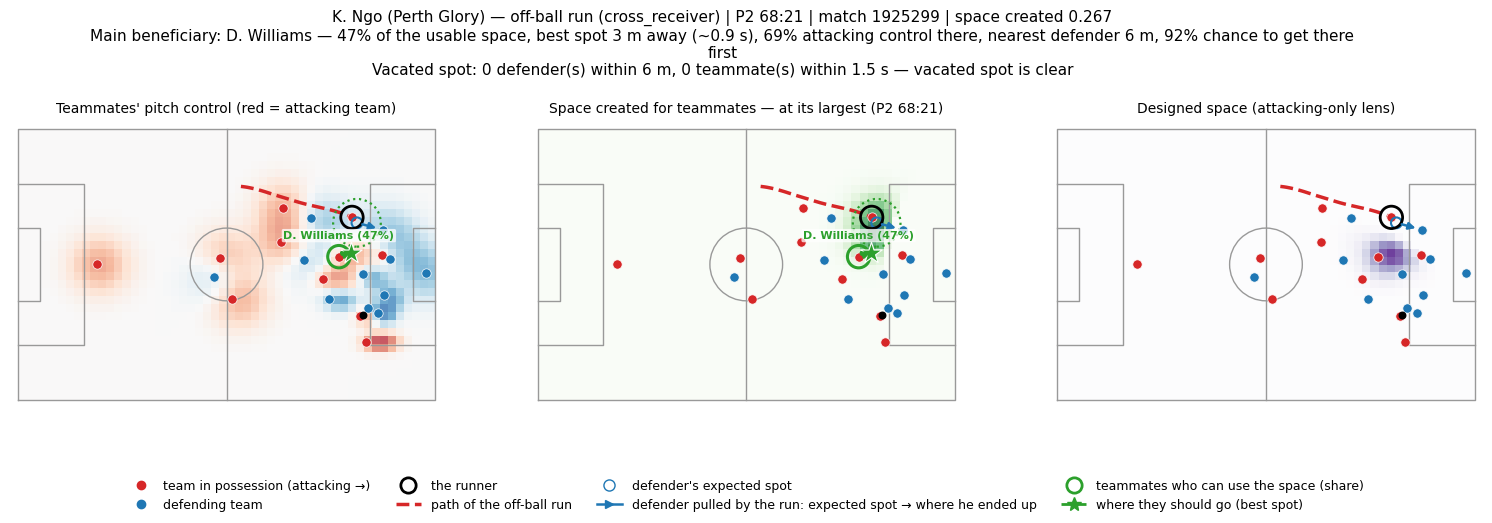

  who benefits from K. Ngo's off-ball run:


,name,benefit,share
3,D. Williams,0.023,0.471
5,N. Pennington,0.012,0.256
4,N. Blair,0.008,0.165


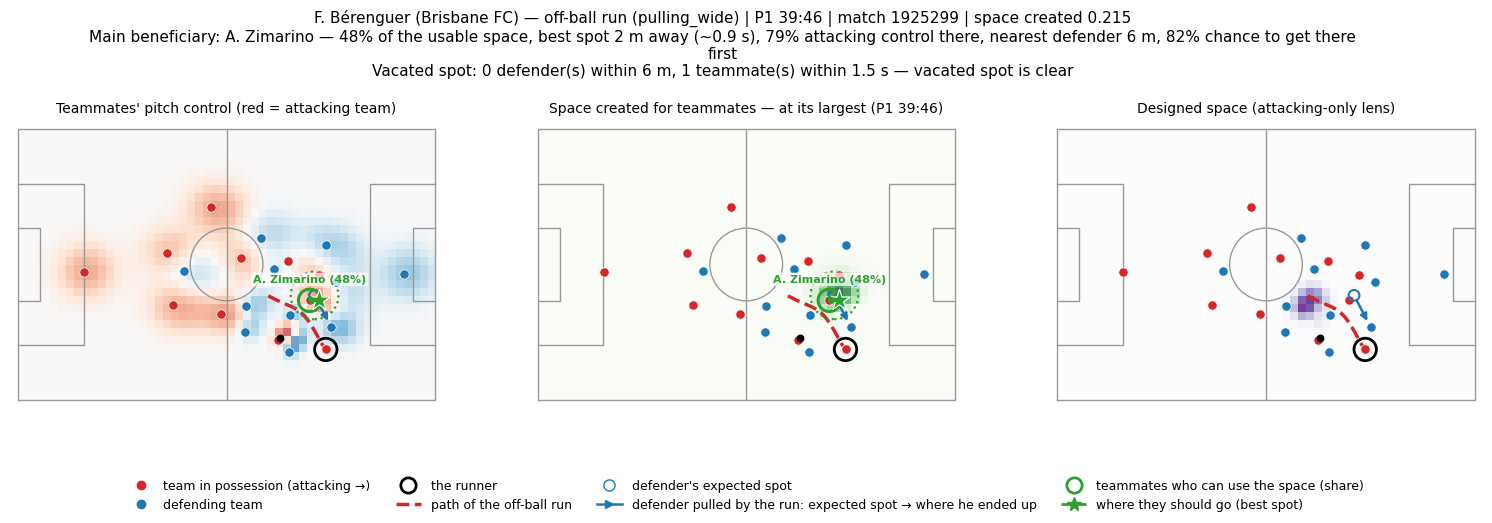

  who benefits from F. Bérenguer's off-ball run:


,name,benefit,share
6,A. Zimarino,0.049,0.478
5,T. Waddingham,0.027,0.269
4,K. Jelacic,0.017,0.170


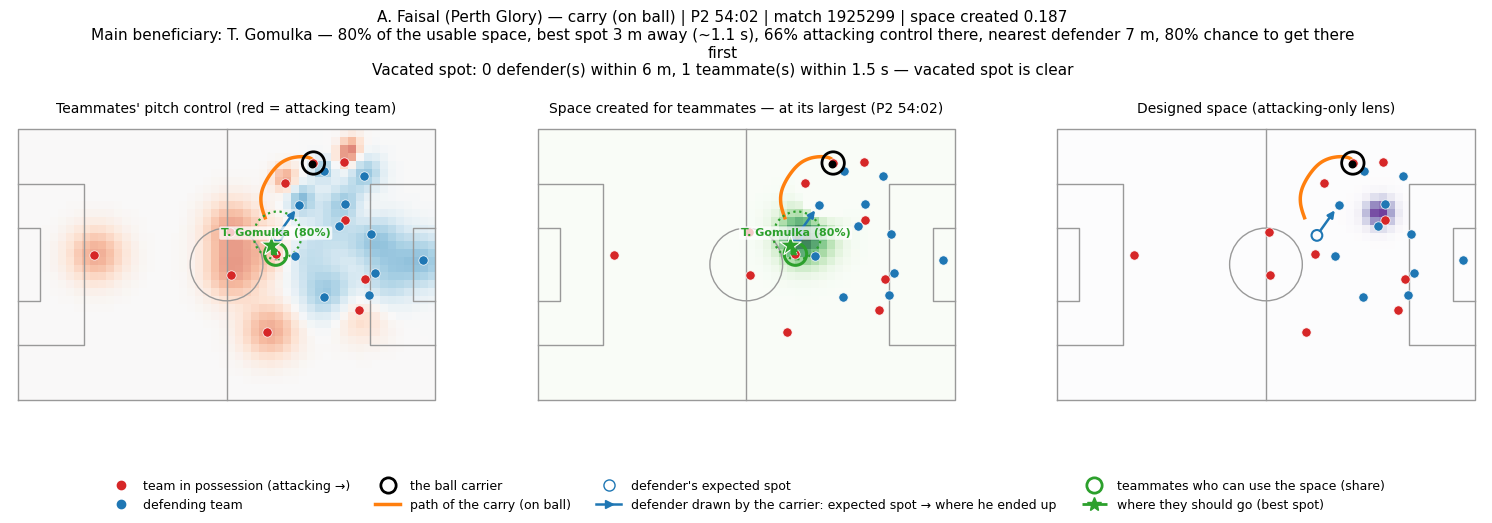

  who benefits from A. Faisal's carry (on ball):


,name,benefit,share
2,T. Gomulka,0.043,0.804
5,N. Pennington,0.008,0.143
0,J. Risdon,0.002,0.036


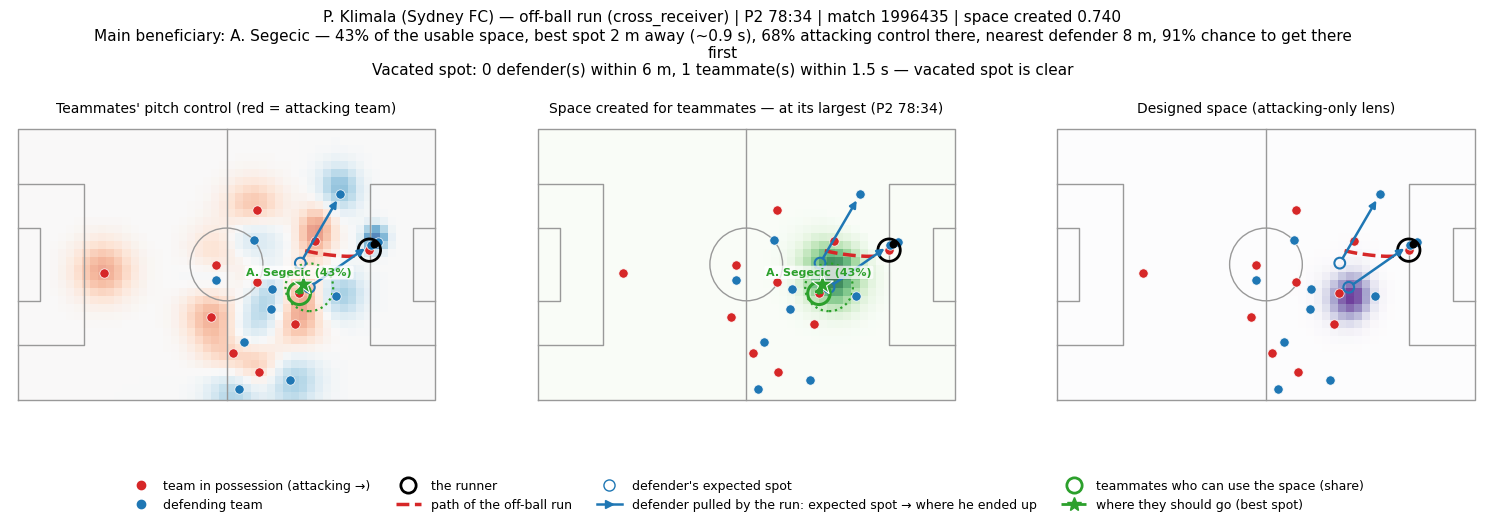

  who benefits from P. Klimala's off-ball run:


,name,benefit,share
6,A. Segecic,0.146,0.431
5,J. Kucharski,0.081,0.240
1,Léo Sena,0.061,0.180


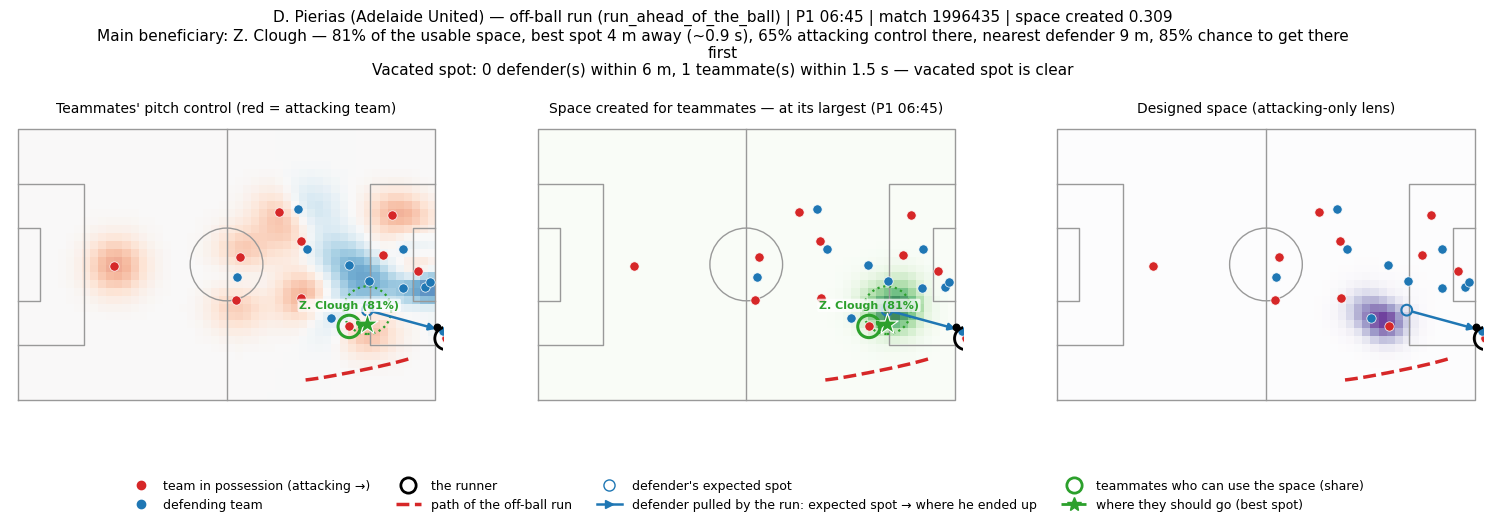

  who benefits from D. Pierias's off-ball run:


,name,benefit,share
0,Z. Clough,0.064,0.807
2,S. Mauk,0.006,0.075
4,A. Goodwin,0.005,0.062


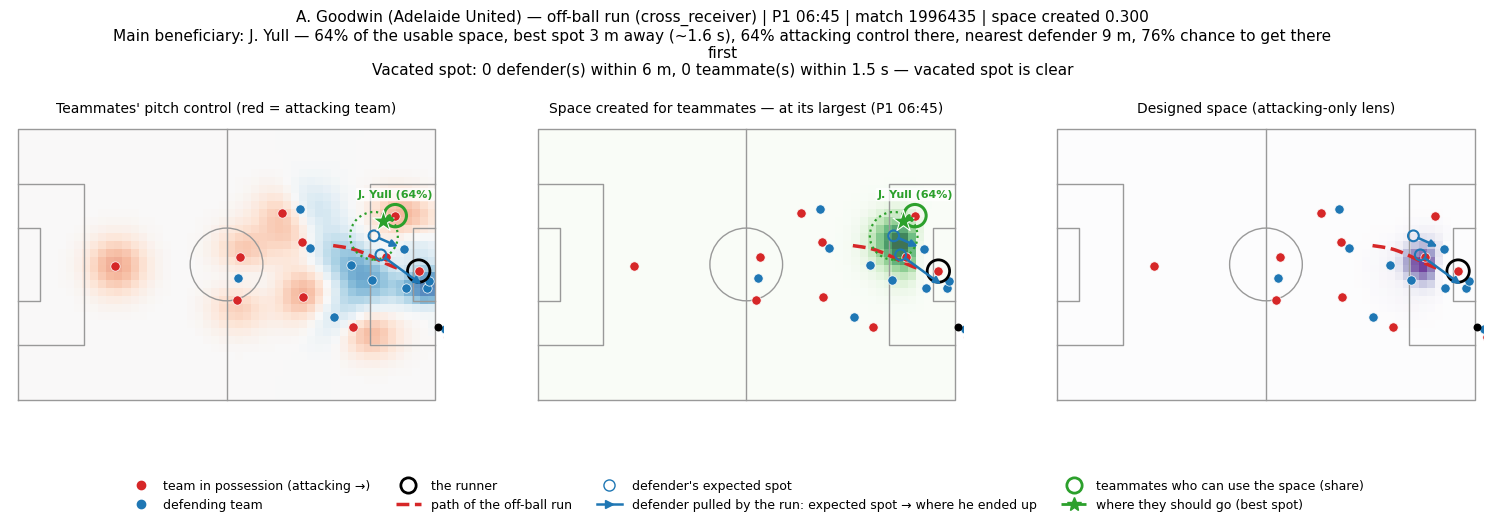

  who benefits from A. Goodwin's off-ball run:


,name,benefit,share
4,J. Yull,0.083,0.639
2,S. Mauk,0.037,0.284
5,E. Alagich,0.006,0.044


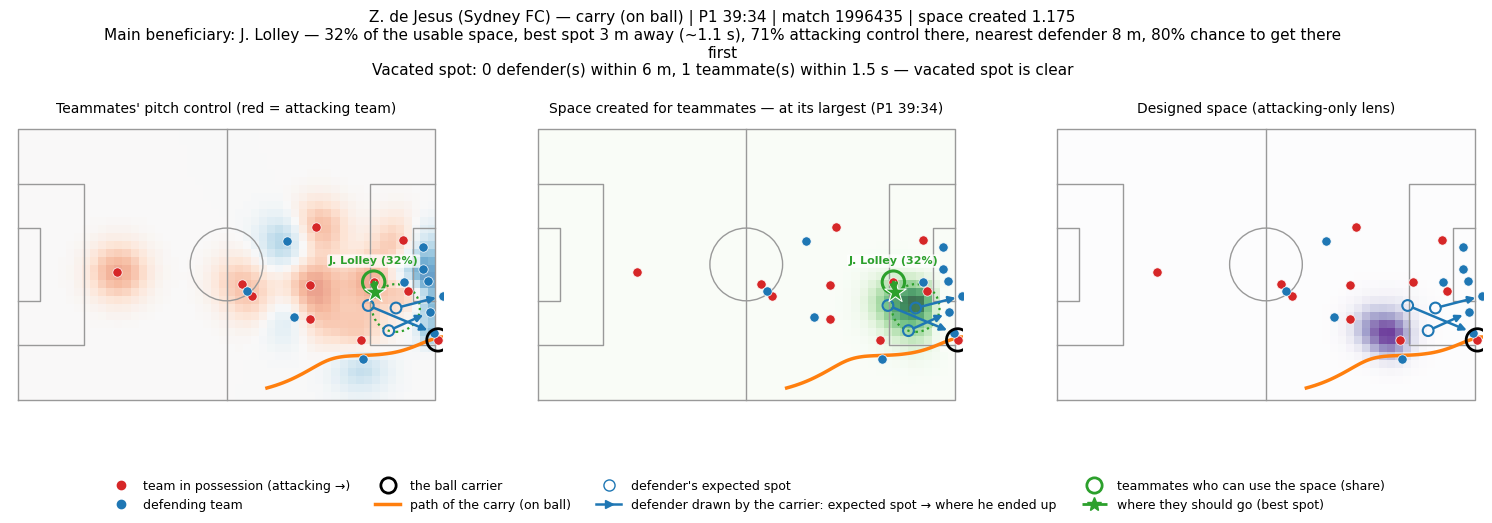

  who benefits from Z. de Jesus's carry (on ball):


,name,benefit,share
1,J. Lolley,0.489,0.324
2,A. Ouahim,0.367,0.243
5,A. Cáceres,0.307,0.203


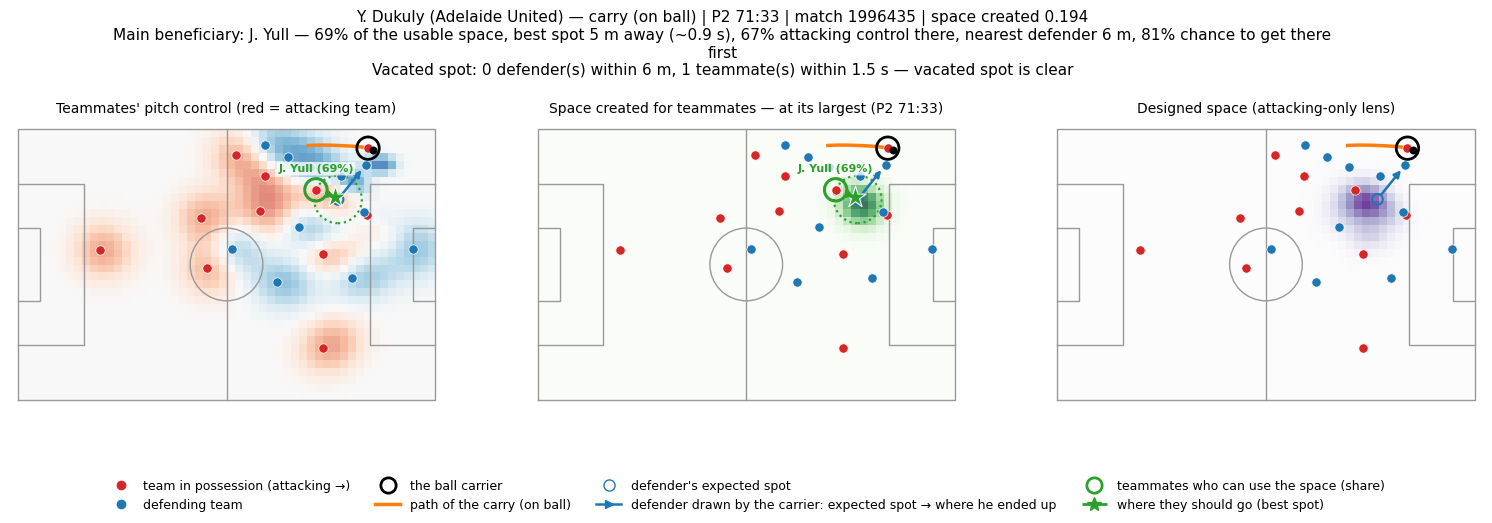

  who benefits from Y. Dukuly's carry (on ball):


,name,benefit,share
2,J. Yull,0.035,0.688
5,L. Jovanovic,0.006,0.114
0,Z. Clough,0.005,0.102


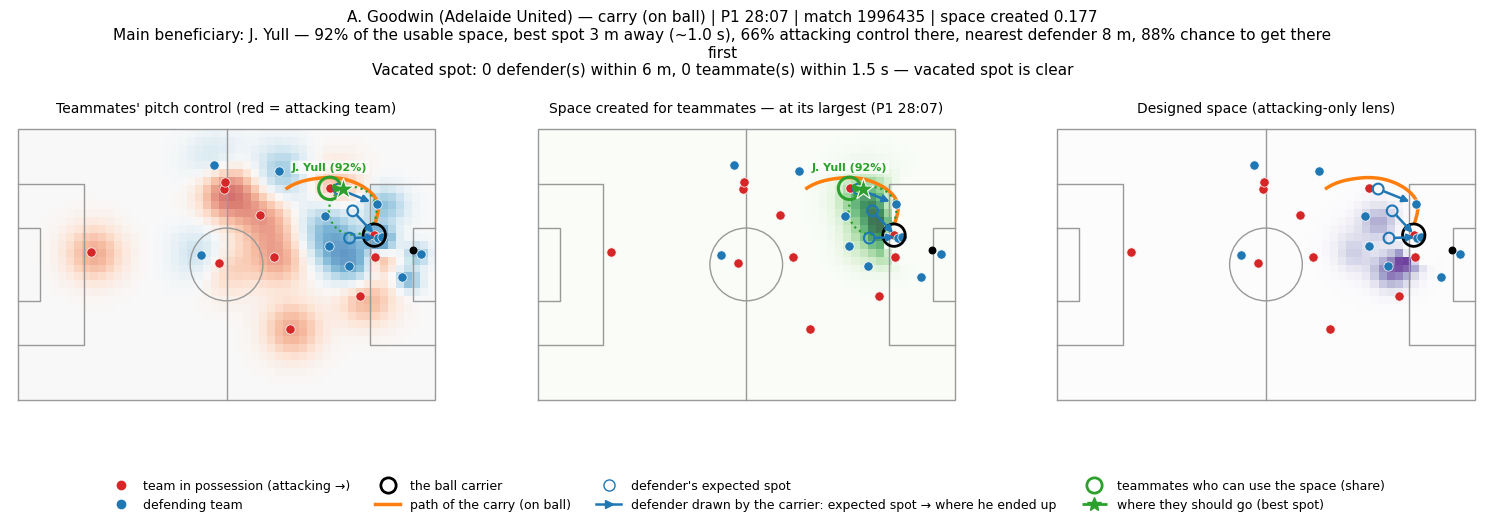

  who benefits from A. Goodwin's carry (on ball):


,name,benefit,share
4,J. Yull,0.073,0.916
2,S. Mauk,0.003,0.032
5,E. Alagich,0.002,0.028


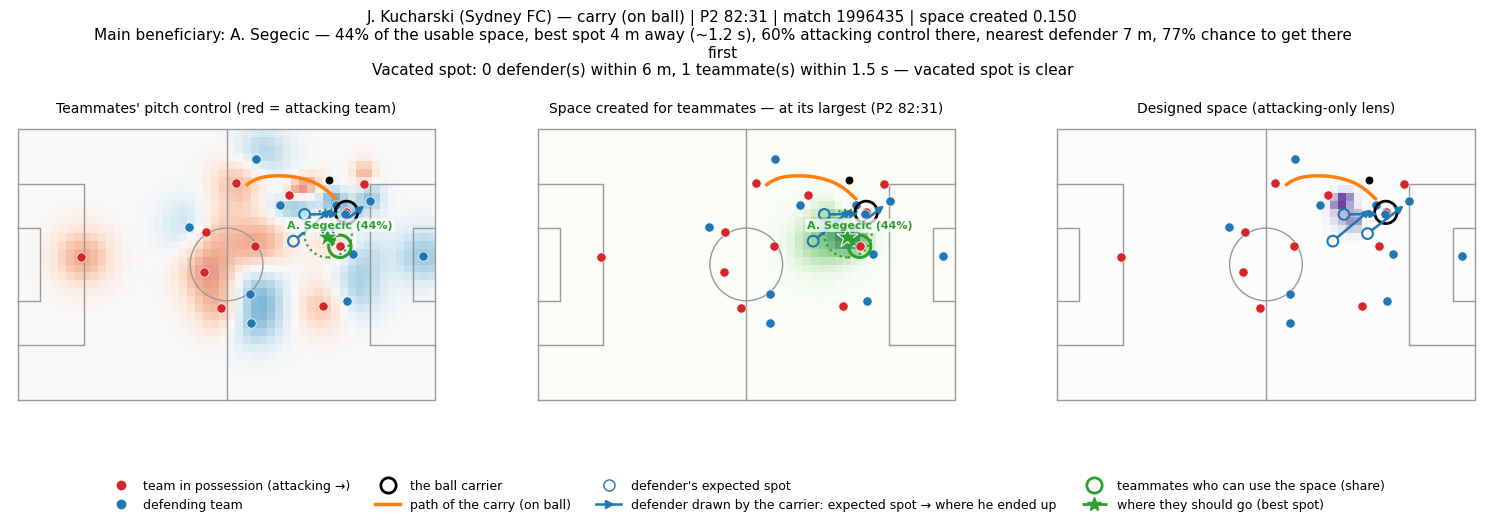

  who benefits from J. Kucharski's carry (on ball):


,name,benefit,share
6,A. Segecic,0.056,0.443
2,Léo Sena,0.039,0.312
4,A. Cáceres,0.015,0.118


,match_id,kind,player,clock,frame_start,created,created_opp_half,run_type,beneficiary,beneficiary_share,gif
6,1996435,carry,Z. de Jesus,P1 39:25,23660,1.1751,1.1751,carry (on ball),J. Lolley,0.32,carry_1996435_23737.gif
3,1996435,off_ball,P. Klimala,P2 78:30,48134,0.7397,0.7395,cross_receiver,A. Segecic,0.43,off_ball_1996435_48155.gif
4,1996435,off_ball,D. Pierias,P1 06:40,4011,0.3090,0.3090,run_ahead_of_the_ball,Z. Clough,0.81,off_ball_1996435_4047.gif
5,1996435,off_ball,A. Goodwin,P1 06:41,4023,0.2997,0.2997,cross_receiver,J. Yull,0.64,off_ball_1996435_4052.gif
0,1925299,off_ball,K. Ngo,P2 68:16,44218,0.2670,0.2670,cross_receiver,D. Williams,0.47,off_ball_1925299_44289.gif
1,1925299,off_ball,F. Bérenguer,P1 39:43,23845,0.2152,0.2152,pulling_wide,A. Zimarino,0.48,off_ball_1925299_23877.gif
7,1996435,carry,Y. Dukuly,P2 71:31,43944,0.1945,0.1945,carry (on ball),J. Yull,0.69,carry_1996435_43967.gif
2,1925299,carry,A. Faisal,P2 53:57,35624,0.1869,0.1847,carry (on ball),T. Gomulka,0.80,carry_1925299_35677.gif
8,1996435,carry,A. Goodwin,P1 28:00,16813,0.1765,0.1765,carry (on ball),J. Yull,0.92,carry_1996435_16865.gif
9,1996435,carry,J. Kucharski,P2 82:26,50491,0.1505,0.1486,carry (on ball),A. Segecic,0.44,carry_1996435_50529.gif


In [ ]:
if VACATED_ONLY:   # check a larger pool, then pick the best vacated-spot plays from it
    cases = pick_cases(filter_vacated(pick_cases(R, n=40, per_kind=(20, 20))), n=10)
else:
    cases = pick_cases(R, n=10)
print(cases.kind.value_counts().to_string())
index_rows = []
for mid, group in cases.groupby("match_id"):
    ctx = build_ctx(mid)                        # load each match once
    for run in group.itertuples():
        _, ben = plot_run_case(run, ctx)
        gif = animate_run(run, ctx)
        if ben is not None:
            print(f"  who benefits from {mins['name'].get(run.player_id, run.player_id)}'s {KIND_STYLE[run.kind]['label']}:")
            display(ben["ranking"].head(3)[["name", "benefit", "share"]].round(3))
        index_rows.append(dict(match_id=mid, kind=run.kind, player=mins["name"].get(run.player_id, run.player_id),
                               clock=match_clock(ctx.trk, int(run.idx_start)), frame_start=run.frame_start,
                               created=round(run.created, 4), created_opp_half=round(run.created_opp_half, 4), run_type=run.run_type,
                               beneficiary=ben["name"] if ben else None,
                               beneficiary_share=round(ben["share"], 2) if ben else None, gif=gif.name))
case_index = pd.DataFrame(index_rows).sort_values("created", ascending=False)
case_index.to_csv(FIG_DIR / "cases" / "case_index.csv", index=False)
display(case_index)

### 16.1 Showcase finder: plays like Kraev's decoy run

The Kraev run (match 1927964, P1 ~08:47) is the reference: a defender pulled a long way, space opening **away from the
runner**, concentrated in the opponent's half, and one clear teammate who can reach it. The first cell turns those traits
into a 0–1 score per component (cause, decoy distance, focus, beneficiary share, how free the spot is, reachability,
how advanced the spot is, size), adds a bonus when the ball was actually played there, and renders the best play per
player to `figures/showcase/` (`S01…`). The second cell finds the movements most similar to any play you like
(`locate_run(match_id, "name", "P1 mm:ss")`) and renders them (`L01…`).

In [ ]:
# ---- Showcase finder: plays like Kraev's decoy run (match 1927964, P1 ~08:47) -------------------------------------
# What makes that play a great example, turned into checks:
#   clear cause      — a defender visibly pulled a long way (big expected-spot → actual arrow)
#   decoy            — the space opens away from the runner, not where he ends up
#   focused space    — the created space is concentrated, not smeared across the pitch
#   in the opponent's half and well tracked (runner and dragged defenders mostly on camera)
#   clear beneficiary— one teammate gets most of the usable space, it's free (control, no defender close) and reachable
#   forward          — the best spot is advanced
#   used             — bonus if the team actually passed to that teammate or near his spot within 4 s
SHOWCASE_N = 12            # plays to render
SHOWCASE_POOL = 300        # candidates that get the (slower) full check
SHOWCASE_DIR = FIG_DIR / "showcase"
SHOWCASE_DIR.mkdir(parents=True, exist_ok=True)


def concentration(maps, top=10):
    m = np.stack(maps)
    tot = m.sum(1)
    return np.where(tot > 0, -np.sort(-m, axis=1)[:, :top].sum(1) / np.maximum(tot, 1e-12), 0.0)


cand = RUNS[RUNS.phase.isin(BUILDUP_PHASES) & RUNS.attacking_half & (RUNS.n_dragged > 0) & (RUNS.created > 0)
            & (RUNS.runner_detected >= 0.7) & (RUNS.dragged_detected.fillna(0) >= 0.7)].copy()
cand["decoy_dist"] = np.hypot(cand.created_cx - cand.x_end, cand.created_cy - cand.y_end)
cand["concentration"] = concentration(cand.defence_map.values)
cand["pre_score"] = (cand.created_opp_half.rank(pct=True) + cand.decoy_dist.rank(pct=True)
                     + cand.concentration.rank(pct=True))
pool = cand.sort_values("pre_score", ascending=False).head(SHOWCASE_POOL)
print(f"{len(cand):,} well-tracked attacking-half movements that pulled a defender; checking the top {len(pool)}")


def showcase_features(ctx, run) -> dict:
    trk = ctx.trk
    peak, peak_val = space_peak(ctx, run)
    sc = run_scene(ctx, run, peak, with_created=True)
    ben = find_beneficiary(ctx, run, peak, sc["created"])
    drag = np.linalg.norm(sc["drag_now"] - sc["drag_exp"], axis=1) if len(sc["drag_now"]) else np.zeros(0)
    used = False
    if ben is not None:
        hi = trk.frames[min(peak + 4 * FPS, len(trk.frames) - 1)]
        p = PASSES[(PASSES.match_id == run.match_id) & (PASSES.team_id == run.team_id)
                   & PASSES.frame_pass.between(trk.frames[int(run.idx_start)], hi)]
        near = np.hypot(p.target_x - ben["target"][0], p.target_y - ben["target"][1]) <= 8
        used = bool(((p.target_id == ben["player_id"]) | near).any())
    vac = vacated_check(ctx, run, peak=peak, sc=sc, ben=ben)
    return dict(peak_idx=peak, peak_space=peak_val, drag_m=float(np.nanmax(drag)) if len(drag) else 0.0,
                vacated=vac["vacated"], space_to_spot=vac["space_to_spot"],
                ben_name=ben["name"] if ben else None, ben_share=ben["share"] if ben else 0.0,
                ben_time=ben["time_s"] if ben else np.nan, ben_control=ben["control"] if ben else 0.0,
                ben_def_m=ben["nearest_def_m"] if ben else 0.0,
                ben_target_x=ben["target"][0] if ben else np.nan, ball_used=used)


rows, ctxs = [], {}
for mid, group in pool.groupby("match_id"):
    ctx = build_ctx(mid)
    for run in group.itertuples():
        rows.append(dict(idx=run.Index, **showcase_features(ctx, run)))
feat = pd.DataFrame(rows).set_index("idx")
SHOW = pool.join(feat)
SHOW = SHOW[SHOW.ben_name.notna()]
if VACATED_ONLY:
    SHOW = SHOW[SHOW.vacated]
    print(f"{len(SHOW)} showcase candidates open space at a vacated defender spot")

# Each component is 0–1; the showcase score is their mean, plus a bonus if the ball was actually played there.
SHOW["s_cause"] = (SHOW.drag_m / 12).clip(0, 1)
SHOW["s_decoy"] = (SHOW.decoy_dist / 15).clip(0, 1)
SHOW["s_focus"] = SHOW.concentration.clip(0, 1)
SHOW["s_beneficiary"] = SHOW.ben_share.clip(0, 1)
SHOW["s_free"] = SHOW.ben_control.clip(0, 1) * (SHOW.ben_def_m >= DEF_CLEAR_M)
SHOW["s_reach"] = np.where(SHOW.ben_time.between(0.8, 3.0), 1.0, 0.5)
SHOW["s_forward"] = ((SHOW.ben_target_x + 10) / 50).clip(0, 1)
SHOW["s_size"] = SHOW.peak_space.rank(pct=True)
parts = ["s_cause", "s_decoy", "s_focus", "s_beneficiary", "s_free", "s_reach", "s_forward", "s_size"]
SHOW["showcase_score"] = SHOW[parts].mean(axis=1) + 0.15 * SHOW.ball_used
SHOW = SHOW.sort_values("showcase_score", ascending=False)
best = SHOW.groupby("player_id").head(1).head(SHOWCASE_N)       # one per player, for variety

show_rows = []
_show = plt.show
plt.show = lambda *a, **k: plt.close("all")
try:
    for mid, group in best.groupby("match_id"):
        ctx = build_ctx(mid)
        for run in group.itertuples():
            sid = f"S{list(best.index).index(run.Index) + 1:02d}"
            plot_run_case(run, ctx, peak=int(run.peak_idx))
            shutil.copy(FIG_DIR / "cases" / f"{run.kind}_{run.match_id}_{run.frame_end}.png", SHOWCASE_DIR / f"{sid}.png")
            animate_run(run, ctx, fname=f"../showcase/{sid}.gif")
            show_rows.append(dict(id=sid, match_id=mid, kind=run.kind, player=mins["name"].get(run.player_id, run.player_id),
                                  team=team_names.get(run.team_id, ""), clock=match_clock(ctx.trk, int(run.idx_start)),
                                  run_type=run.run_type, beneficiary=run.ben_name, share=round(run.ben_share, 2),
                                  drag_m=round(run.drag_m, 1), decoy_m=round(run.decoy_dist, 1),
                                  ball_used=run.ball_used, score=round(run.showcase_score, 3)))
finally:
    plt.show = _show
showcase = pd.DataFrame(show_rows).sort_values("id")
showcase.to_csv(SHOWCASE_DIR / "showcase_index.csv", index=False)
print(f"Rendered {len(showcase)} showcase plays to {SHOWCASE_DIR}")
display(showcase)

114 well-tracked attacking-half movements that pulled a defender; checking the top 114


KeyboardInterrupt: 

In [ ]:
# ---- "More like this": nearest neighbours of a play you like ------------------------------------------------------
SIM_FEATS = ["decoy_dist", "created_cx", "created_cy", "concentration", "dx", "dy", "x_end", "y_end", "opp_half_share"]


def locate_run(match_id, player, clock, tol_s=6):
    """Find a movement by match, player name (part of it is fine) and match clock, e.g. "P1 08:47"."""
    if match_id not in metas:
        return None
    trk, _ = load_match(match_id)
    p = int(clock.split()[0][1])
    mm, ss = map(int, clock.split()[1].split(":"))
    f = trk.frames[trk.period == p].min() + ((mm * 60 + ss) - (45 * 60 if p == 2 else 0)) * FPS
    pids = mins.index[mins["name"].str.contains(player, case=False, na=False)]
    m = RUNS[(RUNS.match_id == match_id) & RUNS.player_id.isin(pids)
             & ((RUNS.frame_start - f).abs() <= tol_s * FPS)]
    return (m.frame_start - f).abs().idxmin() if len(m) else None


def more_like_this(seed, n=10, same_kind=True):
    base = cand if seed in cand.index else pd.concat([cand, RUNS.loc[[seed]].assign(
        decoy_dist=np.hypot(RUNS.at[seed, "created_cx"] - RUNS.at[seed, "x_end"], RUNS.at[seed, "created_cy"] - RUNS.at[seed, "y_end"]),
        concentration=concentration([RUNS.at[seed, "defence_map"]]))])
    if same_kind:
        base = base[base.kind == RUNS.at[seed, "kind"]]
    X = StandardScaler().fit_transform(base[SIM_FEATS].fillna(0))
    d = np.linalg.norm(X - X[list(base.index).index(seed)], axis=1)
    out = base.assign(similarity_dist=d).drop(index=seed).sort_values("similarity_dist")
    return out.groupby("player_id").head(1).head(n)


SEED = locate_run(1927964, "Kraev", "P1 08:47")
if SEED is None:
    print("Seed play not found — check the match id, name and clock")
else:
    print(f"Seed: {mins['name'].get(RUNS.at[SEED, 'player_id'])}, run type {RUNS.at[SEED, 'run_type']}")
    similar = more_like_this(SEED, n=24 if VACATED_ONLY else 6)
    if VACATED_ONLY:
        similar = filter_vacated(similar).head(6)
    sim_rows = []
    _show = plt.show
    plt.show = lambda *a, **k: plt.close("all")
    try:
        for mid, group in similar.groupby("match_id"):
            ctx = build_ctx(mid)
            for run in group.itertuples():
                sid = f"L{list(similar.index).index(run.Index) + 1:02d}"
                _, ben = plot_run_case(run, ctx)
                shutil.copy(FIG_DIR / "cases" / f"{run.kind}_{run.match_id}_{run.frame_end}.png", SHOWCASE_DIR / f"{sid}.png")
                animate_run(run, ctx, fname=f"../showcase/{sid}.gif")
                sim_rows.append(dict(id=sid, match_id=mid, player=mins["name"].get(run.player_id, run.player_id),
                                     clock=match_clock(ctx.trk, int(run.idx_start)), run_type=run.run_type,
                                     beneficiary=ben["name"] if ben else None, distance=round(run.similarity_dist, 2)))
    finally:
        plt.show = _show
    like = pd.DataFrame(sim_rows).sort_values("id")
    like.to_csv(SHOWCASE_DIR / "more_like_this.csv", index=False)
    display(like)

In [ ]:
import shutil

N_REVIEW = 50
REVIEW_DIR = FIG_DIR / REVIEW_NAME
REVIEW_DIR.mkdir(parents=True, exist_ok=True)
SHEET = REVIEW_DIR / "review_sheet.csv"
BUILD_REVIEW = REBUILD_REVIEW or not SHEET.exists()
if not BUILD_REVIEW:
    print(f"Review already built — open {REVIEW_DIR / 'review.html'} (set REBUILD_REVIEW = True or a new REVIEW_NAME for a new sample)")

# ---- Lens overlap: where designed space (attacking-only) and real space (defence-aware) coincide ------------------
# Both maps are value-weighted and scaled by their own maximum over the play, so neither lens dominates. A spot counts
# as "prime" only if it is BOTH designed and actually open (the smaller of the two scaled values). The prime moment is
# when total overlap peaks; the prime window is the continuous stretch around it where overlap stays above half that.
OVERLAP_MIN = 0.25          # scaled overlap a pass target needs to count as "into prime space"
PRIME_WINDOW_FRAC = 0.5
GOLD = "#c98a00"


def lens_series(ctx, run, idxs):
    """Scene, real-space and designed-space maps for every frame in idxs."""
    scenes, real, designed = {}, {}, {}
    for i in idxs:
        sc = run_scene(ctx, run, int(i), with_created=True)
        scenes[int(i)] = sc
        real[int(i)] = np.clip(sc["created"], 0, None) * ctx.value_grid
        designed[int(i)] = designed_map(ctx, run, int(i)) * ctx.value_grid
    return scenes, real, designed


def overlap_analysis(ctx, run):
    a = int(run.idx_start)
    peak, _ = space_peak(ctx, run)
    idxs = gif_window(ctx, run, peak)
    scenes, real, designed = lens_series(ctx, run, idxs)
    dmax = max(float(d.max()) for d in designed.values()) or 1e-12
    rmax = max(float(r.max()) for r in real.values()) or 1e-12
    O = {i: np.minimum(designed[i] / dmax, real[i] / rmax) for i in scenes}
    score = pd.Series({i: float(O[i].sum() * ctx.grid.cell_area) for i in scenes}).sort_index()
    cut = pass_cutoff(ctx, run)
    if cut is not None:                                    # nothing model-based after the ball is played
        score = score[score.index <= max(cut, a)]
    search = score[score.index >= a]                      # the prime moment can't come before the movement starts
    prime = int(search.idxmax()) if len(search) else int(score.idxmax())
    pmax = float(score[prime])
    w0 = w1 = prime
    if pmax > 0:
        keys = list(score.index)
        k = keys.index(prime)
        while k - 1 >= 0 and score[keys[k - 1]] >= PRIME_WINDOW_FRAC * pmax:
            k -= 1
        w0 = keys[k]
        k = keys.index(prime)
        while k + 1 < len(keys) and score[keys[k + 1]] >= PRIME_WINDOW_FRAC * pmax:
            k += 1
        w1 = keys[k]
    ben = find_beneficiary(ctx, run, prime, O[prime]) if pmax > 0 else None
    target = ctx.grid.points[int(np.argmax(O[prime]))] if pmax > 0 else None
    return dict(idxs=idxs, scenes=scenes, real=real, designed=designed, dmax=dmax, rmax=rmax, O=O, score=score,
                prime=prime, w0=w0, w1=w1, pmax=pmax, ben=ben, target=target, cut=cut)


def pass_timing(ctx, run, ov):
    """First pass by the movement's team after it starts: early / on time / late vs the prime window, and whether it
    went into prime space."""
    trk = ctx.trk
    f_from, f_to = trk.frames[int(run.idx_start)], trk.frames[int(ov["idxs"][-1])]
    p = PASSES[(PASSES.match_id == run.match_id) & (PASSES.team_id == run.team_id)
               & PASSES.frame_pass.between(f_from, f_to)].sort_values("frame_pass")
    if not len(p):
        return dict(timing="no pass", into_prime=False, pass_idx=None)
    r = p.iloc[0]
    i_p = int(trk.idx(int(r.frame_pass)))
    if i_p < 0:
        return dict(timing="no pass", into_prime=False, pass_idx=None)
    if ov["pmax"] <= 0:
        timing = "no prime space"
    else:
        timing = "early" if i_p < ov["w0"] else ("on time" if i_p <= ov["w1"] else "late")
    tgt = np.array([r.target_x, r.target_y])
    o_ref = ov["O"][ov["prime"]]
    into = bool(ov["pmax"] > 0 and o_ref[ctx.grid.cell(tgt)[0]] / max(o_ref.max(), 1e-12) >= OVERLAP_MIN)
    return dict(timing=timing, into_prime=into, pass_idx=i_p, passer=int(r.player_id), target_xy=tgt,
                completed=bool(r.completed), receiver=int(r.target_id))


def timing_text(pt):
    if pt["pass_idx"] is None:
        return "no pass during the play"
    return (f"ball played {pt['timing']}" + (", into prime space" if pt["into_prime"] else ", not into prime space")
            + (" (completed)" if pt["completed"] else " (not completed)"))


def show_map(ax, m, cmap, vmax, alpha=.8, floor=0.05):
    shown = np.ma.masked_less(m, floor * vmax)
    ax.imshow(shown.reshape(ax._grid_ny, ax._grid_nx), origin="lower", extent=[-52.5, 52.5, -34, 34], cmap=cmap,
              vmin=0, vmax=vmax, alpha=alpha)


def plot_overlap_case(run, ctx, ov, pt, out):
    """Designed space, real space and their overlap at the prime moment."""
    g, i = ctx.grid, ov["prime"]
    sc = ov["scenes"][i]
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
    panels = [(ov["designed"][i] / ov["dmax"], "Purples", "Designed space (attacking-only lens)"),
              (ov["real"][i] / ov["rmax"], "Greens", "Real space (defence-aware lens)"),
              (ov["O"][i], "YlOrBr", "Overlap = prime space: designed AND open")]
    for ax, (m, cmap, title) in zip(axes, panels):
        ax._grid_ny, ax._grid_nx = g.ny, g.nx
        draw_pitch(ax)
        show_map(ax, m, cmap, 1.0)
        draw_scene(ax, sc, run)
        if ax is axes[2] and ov["ben"] is not None:
            draw_beneficiaries(ax, sc["P"], ov["ben"])
        if pt["pass_idx"] is not None and ax is axes[2]:
            ax.scatter(*pt["target_xy"], marker="X", s=140, c="black", zorder=8)
        ax.set_title(title, fontsize=10)
    fig.legend(handles=legend_handles(run) + [Line2D([], [], marker="X", ls="", color="black", ms=9,
                                                     label="where the ball actually went")],
               loc="lower center", ncol=5, fontsize=8.5, frameon=False)
    fig.suptitle(wrap_lines(case_title(ctx, run, i),
                            f"Prime moment {match_clock(ctx.trk, i)}, window {(ov['w1'] - ov['w0']) / FPS:.1f} s | "
                            + timing_text(pt), width=160), fontsize=11)
    fig.subplots_adjust(bottom=0.13, top=0.86)
    fig.savefig(out, dpi=140, bbox_inches="tight")
    plt.close(fig)


def animate_overlap(run, ctx, ov, pt, out):
    """Model GIF: build-up, movement, pause at the prime moment (gold = prime space, arrows = who should go there),
    a hold when the ball is played, then what happened next."""
    trk, g = ctx.trk, ctx.grid
    a, e, prime = int(run.idx_start), int(run.idx_end), ov["prime"]
    i_p = pt["pass_idx"]
    seq = []
    for i in ov["idxs"]:
        i = int(i)
        seq.append((i, None))
        if i == a:
            seq += [(i, "movement starts")] * int(PAUSE_START_S * FPS)
        if i == prime and ov["pmax"] > 0:
            seq += [(i, "PAUSED — prime moment: designed and real space overlap (gold)")] * int(PAUSE_PEAK_S * FPS)
        if i_p is not None and i == i_p:
            seq += [(i, f"BALL PLAYED — {pt['timing']}" + (", into prime space" if pt["into_prime"] else "")
                     + " — analysis stops here")] * FPS
    fig, ax = plt.subplots(figsize=(10, 7.8))
    ax._grid_ny, ax._grid_nx = g.ny, g.nx

    def draw(k):
        i, label = seq[k]
        sc = ov["scenes"].get(i) or run_scene(ctx, run, i)
        ax.clear()
        ax._grid_ny, ax._grid_nx = g.ny, g.nx
        draw_pitch(ax)
        ax.imshow(sc["pc"].reshape(g.ny, g.nx), origin="lower", extent=[-52.5, 52.5, -34, 34], cmap="RdBu_r",
                  vmin=0, vmax=1, alpha=.35)
        live = i >= a and (ov["cut"] is None or i <= ov["cut"])
        if i in ov["O"] and live:
            show_map(ax, ov["O"][i], "YlOrBr", 1.0, alpha=.85, floor=0.1)
        draw_scene(ax, sc, run, show_arrows=live)
        if live and i >= prime and ov["ben"] is not None:
            draw_beneficiaries(ax, sc["P"], ov["ben"])
        if i_p is not None and i >= i_p:
            ax.scatter(*pt["target_xy"], marker="X", s=140, c="black", zorder=8)
        stage = ("before" if i < a else ("during" if i <= e else "after")) + f" the {KIND_STYLE[run.kind]['label']}"
        if ov["cut"] is not None and i > ov["cut"]:
            stage = "after the pass — how the play panned out (no prime space computed)"
        elif ov["pmax"] > 0 and i < prime:
            stage += f" — prime moment in {(prime - i) / FPS:.1f} s"
        extra = ""
        if i >= prime and ov["pmax"] > 0:
            extra = f"Prime window {(ov['w1'] - ov['w0']) / FPS:.1f} s | " + timing_text(pt)
        ax.set_title(wrap_lines(case_title(ctx, run, i), stage, extra), fontsize=8.5)
        if label:
            ax.text(0, 33, label, ha="center", va="top", fontsize=10, weight="bold",
                    bbox=dict(boxstyle="round,pad=0.3", fc="#fff3b0", ec="#c9a400"))
        ax.legend(handles=legend_handles(run) + [Line2D([], [], marker="s", ls="", color=GOLD, label="prime space (overlap)"),
                                                 Line2D([], [], marker="X", ls="", color="black", label="where the ball went")],
                  loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, fontsize=7.5, frameon=False)

    anim = animation.FuncAnimation(fig, draw, frames=len(seq), interval=100)
    anim.save(out, writer=animation.PillowWriter(fps=10))
    plt.close(fig)


def animate_blind(run, ctx, out, cid):
    """Same window as the model GIF, with every model output hidden and no pause at the model's peak."""
    trk, g = ctx.trk, ctx.grid
    a, e = int(run.idx_start), int(run.idx_end)
    peak, _ = space_peak(ctx, run)
    seq = frame_sequence(gif_window(ctx, run, peak), a, peak, with_peak_pause=False)
    fig, ax = plt.subplots(figsize=(10, 7))
    scenes = {}

    def draw(k):
        i, label = seq[k]
        if i not in scenes:
            scenes[i] = run_scene(ctx, run, i)
        sc = scenes[i]
        ax.clear()
        draw_pitch(ax)
        ax.imshow(sc["pc"].reshape(g.ny, g.nx), origin="lower", extent=[-52.5, 52.5, -34, 34], cmap="RdBu_r",
                  vmin=0, vmax=1, alpha=.55)
        draw_scene(ax, sc, run, show_arrows=False)
        stage = "before" if i < a else ("during" if i <= e else "after")
        ax.set_title(f"{cid} (blind) — {KIND_STYLE[run.kind]['label']} | {match_clock(trk, i)} | {stage}", fontsize=9)
        if label:
            ax.text(0, 33, label, ha="center", va="top", fontsize=10, weight="bold",
                    bbox=dict(boxstyle="round,pad=0.3", fc="#fff3b0", ec="#c9a400"))

    anim = animation.FuncAnimation(fig, draw, frames=len(seq), interval=100)
    anim.save(out, writer=animation.PillowWriter(fps=10))
    plt.close(fig)


if BUILD_REVIEW:
    # A representative sample, not just the best cases: top cases, random credited, random NOT credited (to catch misses),
    # and low data quality (to see what extrapolation does).
    base = RUNS[RUNS.phase.isin(BUILDUP_PHASES)]
    if OPP_HALF_ONLY:
        base = base[base.attacking_half]
    reliable = base[(base.runner_detected >= 0.5) & ~(base.dragged_detected < 0.5)]
    credited = reliable[(reliable.n_dragged > 0) & (reliable.created > 0)]

    top = credited.sort_values("created_opp_half", ascending=False).groupby(["kind", "player_id"]).head(1)
    if VACATED_ONLY:   # credited cases must open space at a dragged defender's vacated spot
        top = filter_vacated(pd.concat([top[top.kind == "off_ball"].head(36), top[top.kind == "carry"].head(24)]))
        credited = filter_vacated(credited.drop(index=top.index).sample(min(80, len(credited) - len(top)),
                                                                        random_state=RANDOM_STATE))
    top = pd.concat([top[top.kind == "off_ball"].head(9), top[top.kind == "carry"].head(6)]).assign(stratum="top")
    strata, used = [top], set(top.index)
    for label, pool, n in [("random credited", credited, 20),
                           ("random not credited", reliable[reliable.n_dragged == 0], 10),
                           ("low data quality", base[base.runner_detected < 0.5], 5)]:
        pool = pool.drop(index=list(used), errors="ignore")
        s = pool.sample(min(n, len(pool)), random_state=RANDOM_STATE).assign(stratum=label)
        used |= set(s.index)
        strata.append(s)
    REVIEW = pd.concat(strata).head(N_REVIEW).copy()
    REVIEW["case_id"] = [f"C{k + 1:02d}" for k in range(len(REVIEW))]
    print(REVIEW.groupby(["stratum", "kind"]).size().to_string())

    rows = []
    _show = plt.show
    plt.show = lambda *a, **k: plt.close("all")      # don't display 50 figures inline
    try:
        for mid, group in REVIEW.groupby("match_id"):
            ctx = build_ctx(mid)
            for run in group.itertuples():
                cid = run.case_id
                _, ben = plot_run_case(run, ctx)
                shutil.copy(FIG_DIR / "cases" / f"{run.kind}_{run.match_id}_{run.frame_end}.png", REVIEW_DIR / f"{cid}.png")
                vac = vacated_check(ctx, run)
                ov = overlap_analysis(ctx, run)
                pt = pass_timing(ctx, run, ov)
                plot_overlap_case(run, ctx, ov, pt, REVIEW_DIR / f"{cid}_overlap.png")
                animate_overlap(run, ctx, ov, pt, REVIEW_DIR / f"{cid}.gif")
                animate_blind(run, ctx, REVIEW_DIR / f"{cid}_blind.gif", cid)
                rows.append(dict(
                    case_id=cid, stratum=run.stratum, match_id=mid, kind=run.kind,
                    player=mins["name"].get(run.player_id, run.player_id), team=team_names.get(run.team_id, ""),
                    clock=match_clock(ctx.trk, int(run.idx_start)), frame_start=run.frame_start, frame_end=run.frame_end,
                    run_type=run.run_type, created=round(run.created, 4), created_opp_half=round(run.created_opp_half, 4),
                    n_dragged=run.n_dragged, dragged=", ".join(str(mins["name"].get(p, p)) for p in run.dragged_ids),
                    beneficiary=ben["name"] if ben else "", beneficiary_share=round(ben["share"], 2) if ben else None,
                    prime_clock=match_clock(ctx.trk, ov["prime"]) if ov["pmax"] > 0 else "",
                    prime_overlap=round(ov["pmax"], 2), prime_window_s=round((ov["w1"] - ov["w0"]) / FPS, 1),
                    prime_beneficiary=ov["ben"]["name"] if ov["ben"] else "",
                    pass_timing=pt["timing"], pass_into_prime=pt["into_prime"], vacated_cover=vac["cover"],
                    pass_completed=pt.get("completed") if pt["pass_idx"] is not None else None,
                    runner_detected=round(run.runner_detected, 2),
                    # fill these in: y / n / u (unsure)
                    movement_real="", dragged_correct="", missed_defender="", beneficiary_correct="",
                    prime_space_correct="", data_issue="", notes=""))
                print(cid, "done")
    finally:
        plt.show = _show

    sheet = pd.DataFrame(rows).sort_values("case_id")
    sheet.to_csv(SHEET, index=False)

    cards = []
    for r in sheet.itertuples():
        cards.append(
            f"<section><h3>{r.case_id} · {r.stratum} · {r.kind} · {r.player} ({r.team}) · {r.clock} · match {r.match_id}</h3>"
            f"<img src='{r.case_id}_blind.gif' width='640'>"
            f"<details><summary>Reveal model</summary><img src='{r.case_id}.gif' width='640'>"
            f"<img src='{r.case_id}.png' width='100%'><img src='{r.case_id}_overlap.png' width='100%'>"
            f"<p>Dragged/drawn: {r.dragged or 'none'} · Beneficiary: {r.beneficiary or 'none'} · "
            f"Space created: {r.created:.3f} · Runner on camera: {r.runner_detected:.0%}<br>"
            f"Prime moment: {r.prime_clock or 'none'} (window {r.prime_window_s} s) · Prime beneficiary: "
            f"{r.prime_beneficiary or 'none'} · Pass: {r.pass_timing}"
            f"{', into prime space' if r.pass_into_prime else ''}</p></details><hr></section>")
    (REVIEW_DIR / "review.html").write_text(
        "<html><body style='font-family:sans-serif;max-width:1000px;margin:auto'>" + "".join(cards) + "</body></html>",
        encoding="utf-8")
    print("Open", REVIEW_DIR / "review.html", "and fill in", SHEET)
    print("\nPass timing vs the prime window in this sample:")
    display(pd.crosstab(sheet.pass_timing, sheet.pass_into_prime, margins=True))

*Review*

In [ ]:
checks = ["movement_real", "dragged_correct", "missed_defender", "beneficiary_correct", "prime_space_correct", "data_issue"]
checks = [c for c in checks if c in pd.read_csv(SHEET, nrows=0).columns] if SHEET.exists() else checks   # older sheets


def yes_rate(s):
    s = s.dropna().astype(str).str.strip().str.lower().str[0]
    s = s[s.isin(["y", "n"])]                     # unsure answers are left out
    if not len(s):
        return pd.Series({"rate": np.nan, "n": 0, "ci_low": np.nan, "ci_high": np.nan})
    p, n, z = (s == "y").mean(), len(s), 1.96     # Wilson 95% interval
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return pd.Series({"rate": p, "n": n, "ci_low": c - h, "ci_high": c + h})


rv = pd.read_csv(SHEET) if SHEET.exists() else pd.DataFrame()
answered = rv[checks].notna().any(axis=1).sum() if len(rv) else 0
if answered == 0:
    print(f"No answers yet — fill in {SHEET} after watching {REVIEW_DIR / 'review.html'}")
else:
    print(f"{answered} of {len(rv)} cases reviewed\n")
    print("Overall"); display(pd.DataFrame({c: yes_rate(rv[c]) for c in checks}).T.round(2))
    for by in ("stratum", "kind"):
        print(f"By {by}")
        display(rv.groupby(by).apply(lambda g: pd.Series({c: yes_rate(g[c])["rate"] for c in checks})).round(2))

## 17. Next steps

* **Refactor into `src/`** — sections 2, 4–11 map directly onto modules (`data`, `value`, `pitch_control`,
  `baseline`, `runs`, `metrics`, `line`), which is what the Cup's reusability criterion rewards.
* **Sensitivity checks** — vary `CF_BANDWIDTH`, the drag thresholds, `PC_OPEN` and the value surface
  (fitted vs parametric) and confirm the leaderboards are stable.
* **Credit sharing** — when several runs happen at once, split created space by each runner's share of the
  dragged defenders (Shapley-style) instead of crediting each run independently.
* **Pose** — run Section 13 on both full pose matches; compare decoy vs genuine runs by orientation.
* **Footage** — use the match clocks on the case-study figures to pull matching broadcast clips (check the
  competition rules and rights first).